In [1]:
!pip install timm -q

import re, random, hashlib
from pathlib import Path
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import timm
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import f1_score, accuracy_score, recall_score

DATA_ROOT = "/kaggle/input/cervical-cancer-largest-dataset-sipakmed"  # change if needed
MODELS = ["resnet50", "efficientnet_b0", "vit_base_patch16_224"]
SEEDS = [0]                 # later: [0, 1, 2, 3, 4]
EPOCHS, BS, LR, IMG = 3, 32, 1e-4, 224   # use EPOCHS=10 after the test run
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLASS_KEYS = ["dyskeratotic", "koilocytotic", "metaplastic", "parabasal", "superficial"]

def seed_all(s):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print("Device:", DEVICE)
print("Data folder exists:", Path(DATA_ROOT).exists())

Device: cuda
Data folder exists: False


In [2]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 3:
        print(root, "| subfolders:", len(dirs), "| files:", len(files))

/kaggle/input | subfolders: 1 | files: 0
/kaggle/input/datasets | subfolders: 1 | files: 0
/kaggle/input/datasets/prahladmehandiratta | subfolders: 1 | files: 0
/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed | subfolders: 5 | files: 0


In [3]:
DATA_ROOT = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"
print("Data folder exists:", Path(DATA_ROOT).exists())

Data folder exists: True


In [4]:
def get_class(p: Path):
    low = [x.lower() for x in p.parts]
    for k in CLASS_KEYS:
        if any(k in part for part in low):
            return k
    return p.parent.name.lower()

def get_group(p: Path, cls: str):
    # names like 001_01.bmp: prefix = source cluster image (same slide)
    m = re.match(r"^(\d+)_\d+", p.stem)
    return f"{cls}_{m.group(1)}" if m else f"{cls}_{p.stem}"

exts = {".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"}
files = [p for p in Path(DATA_ROOT).rglob("*") if p.suffix.lower() in exts]
cropped = [p for p in files if "cropped" in str(p).lower()]
files = cropped if cropped else files

df = pd.DataFrame({"path": [str(p) for p in files]})
df["cls"] = [get_class(p) for p in files]
df["group"] = [get_group(p, c) for p, c in zip(files, df["cls"])]
df["md5"] = [hashlib.md5(open(p, "rb").read()).hexdigest() for p in df["path"]]

n0 = len(df)
df = df.drop_duplicates("md5").reset_index(drop=True)
print(f"Images: {n0} -> {len(df)} after exact-duplicate removal")
print(df["cls"].value_counts())
print("Unique groups:", df["group"].nunique())

classes = sorted(df["cls"].unique())
cid = {c: i for i, c in enumerate(classes)}
df["y"] = df["cls"].map(cid)

print("\nSample paths:")
for p in df["path"].sample(5, random_state=0):
    print(p)

Images: 4049 -> 4049 after exact-duplicate removal
cls
superficial     831
koilocytotic    825
dyskeratotic    813
metaplastic     793
parabasal       787
Name: count, dtype: int64
Unique groups: 966

Sample paths:
/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed/im_Superficial-Intermediate/im_Superficial-Intermediate/CROPPED/023_09.bmp
/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed/im_Koilocytotic/im_Koilocytotic/CROPPED/042_03.bmp
/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed/im_Parabasal/im_Parabasal/CROPPED/064_04.bmp
/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed/im_Metaplastic/im_Metaplastic/CROPPED/139_03.bmp
/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed/im_Superficial-Intermediate/im_Superficial-Intermediate/CROPPED/097_07.bmp


In [5]:
def random_split(df, seed):
    tr, tmp = train_test_split(df, test_size=0.3, stratify=df["y"], random_state=seed)
    va, te = train_test_split(tmp, test_size=0.5, stratify=tmp["y"], random_state=seed)
    return tr, va, te

def group_split(df, seed):
    g1 = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    tr_i, tmp_i = next(g1.split(df, groups=df["group"]))
    tr, tmp = df.iloc[tr_i], df.iloc[tmp_i]
    g2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=seed)
    va_i, te_i = next(g2.split(tmp, groups=tmp["group"]))
    return tr, tmp.iloc[va_i], tmp.iloc[te_i]

def overlap(a, b):
    return len(set(a["group"]) & set(b["group"]))

for name, fn in [("random", random_split), ("group", group_split)]:
    tr, va, te = fn(df, 0)
    print(f"\n[{name}] train={len(tr)} val={len(va)} test={len(te)}")
    print("  shared groups train/test:", overlap(tr, te), "| train/val:", overlap(tr, va), "| val/test:", overlap(va, te))
    print("  test class counts:", te["cls"].value_counts().to_dict())


[random] train=2834 val=607 test=608
  shared groups train/test: 368 | train/val: 359 | val/test: 199
  test class counts: {'superficial': 125, 'koilocytotic': 124, 'dyskeratotic': 122, 'metaplastic': 119, 'parabasal': 118}

[group] train=2754 val=680 test=615
  shared groups train/test: 0 | train/val: 0 | val/test: 0
  test class counts: {'superficial': 143, 'parabasal': 143, 'koilocytotic': 130, 'dyskeratotic': 108, 'metaplastic': 91}


In [6]:
norm = T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])

train_tf = T.Compose([
    T.Resize((IMG, IMG)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(0.2, 0.2, 0.2, 0.05),   # simple stain/color augmentation
    T.ToTensor(), norm,
])
eval_tf = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), norm])

class DS(Dataset):
    def __init__(self, d, tf):
        self.p, self.y, self.tf = d["path"].tolist(), d["y"].tolist(), tf
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        return self.tf(Image.open(self.p[i]).convert("RGB")), self.y[i]

def loader(d, tf, shuffle):
    return DataLoader(DS(d, tf), batch_size=BS, shuffle=shuffle, num_workers=2)

# quick test on the group split
seed_all(0)
tr, va, te = group_split(df, 0)
dl_tr, dl_va, dl_te = loader(tr, train_tf, True), loader(va, eval_tf, False), loader(te, eval_tf, False)

x, y = next(iter(dl_tr))
print("Batch shape:", x.shape, "| labels:", y[:8].tolist())
print("Classes:", classes)

Batch shape: torch.Size([32, 3, 224, 224]) | labels: [2, 3, 1, 0, 4, 3, 4, 2]
Classes: ['dyskeratotic', 'koilocytotic', 'metaplastic', 'parabasal', 'superficial']


In [7]:
def run_epoch(model, dl, opt=None):
    train = opt is not None
    model.train(train)
    total, n = 0.0, 0
    for x, y in dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            loss = F.cross_entropy(model(x), y)
        if train:
            opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * len(y); n += len(y)
    return total / n

@torch.no_grad()
def get_logits(model, dl):
    model.eval()
    L, Y = [], []
    for x, y in dl:
        L.append(model(x.to(DEVICE)).cpu()); Y.append(y)
    return torch.cat(L), torch.cat(Y)

def ece(logits, y, bins=15):
    p = F.softmax(logits, 1)
    conf, pred = p.max(1)
    acc = (pred == y).float()
    edges = torch.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.float().mean() * (conf[m].mean() - acc[m].mean()).abs()
    return float(e)

def fit_temperature(val_logits, val_y):
    logT = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
    def closure():
        opt.zero_grad()
        loss = F.cross_entropy(val_logits / logT.exp(), val_y)
        loss.backward()
        return loss
    opt.step(closure)
    return float(logT.detach().exp())      # fixed: detach before converting to float

def metrics(logits, y, temp=1.0):
    pred = (logits / temp).argmax(1).numpy()
    yt = y.numpy()
    rec = recall_score(yt, pred, average=None)
    return dict(acc=accuracy_score(yt, pred),
                macro_f1=f1_score(yt, pred, average="macro"),
                ece=ece(logits / temp, y),
                **{f"recall_{classes[i]}": r for i, r in enumerate(rec)})

# sanity test on dummy overconfident logits
torch.manual_seed(0)
dummy_y = torch.randint(0, 5, (500,))
dummy_logits = torch.randn(500, 5) * 3
dummy_logits[torch.arange(500), dummy_y] += 3
Tt = fit_temperature(dummy_logits, dummy_y)
print("ECE before:", round(ece(dummy_logits, dummy_y), 4),
      "| after TS:", round(ece(dummy_logits / Tt, dummy_y), 4),
      "| T =", round(Tt, 3))

ECE before: 0.3171 | after TS: 0.0417 | T = 3.193


In [8]:
import time
seed_all(0)
tr, va, te = group_split(df, 0)
dl_tr, dl_va, dl_te = loader(tr, train_tf, True), loader(va, eval_tf, False), loader(te, eval_tf, False)

model = timm.create_model("resnet50", pretrained=True, num_classes=len(classes)).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

t0 = time.time()
loss = run_epoch(model, dl_tr, opt)
print(f"Epoch 1 train loss: {loss:.4f} | time: {time.time()-t0:.0f}s")

vl, vy = get_logits(model, dl_va)
tl, ty = get_logits(model, dl_te)
Tt = fit_temperature(vl, vy)

print("T =", round(Tt, 3))
before = metrics(tl, ty)
after = metrics(tl, ty, Tt)
print("Before TS:", {k: round(v, 3) for k, v in before.items()})
print("After TS: ", {k: round(v, 3) for k, v in after.items()})

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1 train loss: 1.4747 | time: 32s
T = 0.054
Before TS: {'acc': 0.766, 'macro_f1': 0.748, 'ece': 0.462, 'recall_dyskeratotic': np.float64(0.981), 'recall_koilocytotic': np.float64(0.346), 'recall_metaplastic': np.float64(0.989), 'recall_parabasal': np.float64(0.755), 'recall_superficial': np.float64(0.853)}
After TS:  {'acc': 0.766, 'macro_f1': 0.748, 'ece': 0.157, 'recall_dyskeratotic': np.float64(0.981), 'recall_koilocytotic': np.float64(0.346), 'recall_metaplastic': np.float64(0.989), 'recall_parabasal': np.float64(0.755), 'recall_superficial': np.float64(0.853)}


In [9]:
import copy, gc, os

EPOCHS = 10
SEEDS = [0]                                   # add 1,2,3,4 later
LRS = {"vit_base_patch16_224": 3e-5}          # ViT needs a smaller LR; others use LR
RESULTS = "baseline_results.csv"

rows, done = [], set()
if os.path.exists(RESULTS):
    prev = pd.read_csv(RESULTS)
    rows = prev.to_dict("records")
    done = set(zip(prev["split"], prev["seed"], prev["model"]))

def train_model(name, dl_tr, dl_va):
    model = timm.create_model(name, pretrained=True, num_classes=len(classes)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LRS.get(name, LR), weight_decay=1e-4)
    best_f1, best_state = -1.0, None
    for ep in range(EPOCHS):
        loss = run_epoch(model, dl_tr, opt)
        vl, vy = get_logits(model, dl_va)
        f1 = f1_score(vy.numpy(), vl.argmax(1).numpy(), average="macro")
        print(f"  ep{ep+1:2d} train loss {loss:.3f} | val macro-F1 {f1:.3f}")
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model

for split_name, splitter in [("random", random_split), ("group", group_split)]:
    for seed in SEEDS:
        seed_all(seed)
        tr, va, te = splitter(df, seed)
        dl_tr, dl_va, dl_te = loader(tr, train_tf, True), loader(va, eval_tf, False), loader(te, eval_tf, False)
        for name in MODELS:
            if (split_name, seed, name) in done:
                print("skip", split_name, seed, name); continue
            print(f"\n[{split_name} | seed {seed} | {name}]")
            t0 = time.time()
            model = train_model(name, dl_tr, dl_va)
            vl, vy = get_logits(model, dl_va)
            tl, ty = get_logits(model, dl_te)
            Tt = fit_temperature(vl, vy)
            for cal in (False, True):
                m = metrics(tl, ty, Tt if cal else 1.0)
                rows.append(dict(split=split_name, seed=seed, model=name,
                                 temp=Tt, calibrated=cal, **m))
            if seed == SEEDS[0]:
                torch.save(model.state_dict(), f"ckpt_{split_name}_{name}_s{seed}.pt")
            pd.DataFrame(rows).to_csv(RESULTS, index=False)
            print(f"  test macro-F1 {rows[-2]['macro_f1']:.3f} | ECE {rows[-2]['ece']:.3f} -> {rows[-1]['ece']:.3f} "
                  f"| T {Tt:.2f} | {time.time()-t0:.0f}s")
            del model; gc.collect(); torch.cuda.empty_cache()

res = pd.DataFrame(rows)
print(res.groupby(["split", "model", "calibrated"])[["acc", "macro_f1", "ece"]].mean().round(4))


[random | seed 0 | resnet50]
  ep 1 train loss 1.465 | val macro-F1 0.816
  ep 2 train loss 0.796 | val macro-F1 0.876
  ep 3 train loss 0.438 | val macro-F1 0.886
  ep 4 train loss 0.295 | val macro-F1 0.928
  ep 5 train loss 0.283 | val macro-F1 0.948
  ep 6 train loss 0.229 | val macro-F1 0.935
  ep 7 train loss 0.217 | val macro-F1 0.928
  ep 8 train loss 0.205 | val macro-F1 0.942
  ep 9 train loss 0.169 | val macro-F1 0.964
  ep10 train loss 0.176 | val macro-F1 0.948
  test macro-F1 0.960 | ECE 0.023 -> 0.022 | T 0.79 | 355s

[random | seed 0 | efficientnet_b0]


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep 1 train loss 1.023 | val macro-F1 0.803
  ep 2 train loss 0.412 | val macro-F1 0.864
  ep 3 train loss 0.271 | val macro-F1 0.889
  ep 4 train loss 0.227 | val macro-F1 0.916
  ep 5 train loss 0.182 | val macro-F1 0.888
  ep 6 train loss 0.160 | val macro-F1 0.919
  ep 7 train loss 0.132 | val macro-F1 0.928
  ep 8 train loss 0.136 | val macro-F1 0.927
  ep 9 train loss 0.119 | val macro-F1 0.948
  ep10 train loss 0.101 | val macro-F1 0.942
  test macro-F1 0.952 | ECE 0.020 -> 0.018 | T 1.18 | 176s

[random | seed 0 | vit_base_patch16_224]


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

  ep 1 train loss 0.384 | val macro-F1 0.935
  ep 2 train loss 0.119 | val macro-F1 0.960
  ep 3 train loss 0.096 | val macro-F1 0.957
  ep 4 train loss 0.065 | val macro-F1 0.960
  ep 5 train loss 0.110 | val macro-F1 0.975
  ep 6 train loss 0.050 | val macro-F1 0.950
  ep 7 train loss 0.054 | val macro-F1 0.950
  ep 8 train loss 0.031 | val macro-F1 0.956
  ep 9 train loss 0.026 | val macro-F1 0.982
  ep10 train loss 0.030 | val macro-F1 0.979
  test macro-F1 0.982 | ECE 0.011 -> 0.010 | T 1.27 | 1168s

[group | seed 0 | resnet50]
  ep 1 train loss 1.485 | val macro-F1 0.718
  ep 2 train loss 0.911 | val macro-F1 0.856
  ep 3 train loss 0.484 | val macro-F1 0.851
  ep 4 train loss 0.358 | val macro-F1 0.915
  ep 5 train loss 0.292 | val macro-F1 0.921
  ep 6 train loss 0.260 | val macro-F1 0.941
  ep 7 train loss 0.237 | val macro-F1 0.938
  ep 8 train loss 0.205 | val macro-F1 0.934
  ep 9 train loss 0.194 | val macro-F1 0.946
  ep10 train loss 0.188 | val macro-F1 0.937
  test macr

In [10]:
# Paste each "CELL" block into a new Kaggle cell. Run in order, after the baseline training cell.
# Needs: df, classes, MODELS, DEVICE, loader, eval_tf, get_logits, fit_temperature,
#        random_split, group_split, and ckpt_{split}_{model}_s0.pt saved by the baseline cell.


# %% ===================== CELL 1: near-duplicate audit (leakage check) =====================
import time, math
import numpy as np, pandas as pd, torch, timm
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import f1_score

COS_THR, HAM_THR = 0.90, 8      # tune after looking at the printed quantiles


def load_ckpt(name, split):
    m = timm.create_model(name, pretrained=False, num_classes=len(classes))
    m.load_state_dict(torch.load(f"ckpt_{split}_{name}_s0.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


def dhash(path, size=8):
    im = Image.open(path).convert("L").resize((size + 1, size), Image.BILINEAR)
    a = np.asarray(im, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()                    # 64 bits


t0 = time.time()
H = np.stack([dhash(p) for p in df["path"]])
print("dHash:", H.shape, f"{time.time() - t0:.0f}s")


@torch.no_grad()
def embed_all(dframe):
    m = timm.create_model("resnet50", pretrained=True, num_classes=0).to(DEVICE).eval()
    E = torch.cat([m(x.to(DEVICE)).cpu() for x, _ in loader(dframe, eval_tf, False)])
    del m; torch.cuda.empty_cache()
    E = E - E.mean(0, keepdim=True)                            # centering makes cosine more discriminative
    return F.normalize(E, dim=1)


E = embed_all(df)                                              # df index is 0..N-1, same order as loader
print("Embeddings:", tuple(E.shape))


def nearest_train(te_idx, tr_idx):
    cos_max = (E[te_idx] @ E[tr_idx].T).max(1).values.numpy()
    ham_min = (H[te_idx][:, None, :] != H[tr_idx][None, :, :]).sum(2).min(1)
    return cos_max, ham_min


audit = {}
for split, fn in [("random", random_split), ("group", group_split)]:
    tr, va, te = fn(df, 0)
    cmax, hmin = nearest_train(te.index.values, tr.index.values)
    near = (cmax >= COS_THR) | (hmin <= HAM_THR)
    audit[split] = dict(te=te, near=near)
    print(f"[{split}] test={len(te)} | cos_max q50/q90/q99 = {np.round(np.quantile(cmax, [.5, .9, .99]), 3)} "
          f"| hamming<={HAM_THR}: {(hmin <= HAM_THR).sum()} | near-dup: {near.sum()} ({near.mean():.1%})")

rows_a = []
for split in ["random", "group"]:
    te, near = audit[split]["te"], audit[split]["near"]
    dl_te = loader(te, eval_tf, False)
    for name in MODELS:
        m = load_ckpt(name, split)
        tl, ty = get_logits(m, dl_te)
        pred, yt = tl.argmax(1).numpy(), ty.numpy()
        f_all = f1_score(yt, pred, average="macro")
        f_dd = f1_score(yt[~near], pred[~near], average="macro")
        rows_a.append(dict(split=split, model=name, n_test=len(yt), n_near=int(near.sum()),
                           f1_all=f_all, f1_dedup=f_dd, drop=f_all - f_dd))
        del m; torch.cuda.empty_cache()

audit_df = pd.DataFrame(rows_a).round(4)
audit_df.to_csv("near_dup_audit.csv", index=False)
print(audit_df.to_string(index=False))


# %% ===================== CELL 2: cache logits + conformal prediction =====================
LOGITS = {}
for split, fn in [("random", random_split), ("group", group_split)]:
    tr, va, te = fn(df, 0)
    dl_va, dl_te = loader(va, eval_tf, False), loader(te, eval_tf, False)
    for name in MODELS:
        m = load_ckpt(name, split)
        vl, vy = get_logits(m, dl_va)
        tl, ty = get_logits(m, dl_te)
        LOGITS[(split, name)] = dict(vl=vl, vy=vy, tl=tl, ty=ty, T=fit_temperature(vl, vy))
        del m; torch.cuda.empty_cache()
torch.save(LOGITS, "logits_cache.pt")                          # later steps (shift, external) reuse this


def conformal_sets(cal_p, cal_y, test_p, alpha=0.1, classwise=False):
    s = 1 - cal_p[torch.arange(len(cal_y)), cal_y]             # LAC nonconformity score

    def qhat(sc):
        n = len(sc)
        k = math.ceil((n + 1) * (1 - alpha))
        return float("inf") if k > n else torch.sort(sc).values[k - 1].item()

    if not classwise:
        return (1 - test_p) <= qhat(s)
    sets = torch.zeros_like(test_p, dtype=torch.bool)
    for c in range(test_p.shape[1]):                           # Mondrian / class-conditional
        sets[:, c] = (1 - test_p[:, c]) <= qhat(s[cal_y == c])
    return sets


def conf_report(sets, y):
    n, K = len(y), sets.shape[1]
    size = sets.sum(1)
    cov = sets[torch.arange(n), y].float()
    single = size == 1
    pred1 = sets.float().argmax(1)
    return dict(coverage=cov.mean().item(),
                avg_size=size.float().mean().item(),
                singleton=single.float().mean().item(),
                abstain=(~single).float().mean().item(),       # empty or multi-label set
                acc_on_singleton=(pred1[single] == y[single]).float().mean().item() if single.any() else float("nan"),
                worst_class_cov=min(cov[y == c].mean().item() for c in range(K)))


ALPHA = 0.1                                                    # target coverage = 90%
rows_c = []
for (split, name), d in LOGITS.items():
    cal_p = F.softmax(d["vl"] / d["T"], 1)
    test_p = F.softmax(d["tl"] / d["T"], 1)
    for method, cw in [("LAC", False), ("class-cond", True)]:
        sets = conformal_sets(cal_p, d["vy"], test_p, ALPHA, cw)
        rows_c.append(dict(split=split, model=name, method=method, **conf_report(sets, d["ty"])))

conf_df = pd.DataFrame(rows_c).round(3)
conf_df.to_csv("conformal_baseline.csv", index=False)
print(conf_df.to_string(index=False))

dHash: (4049, 64) 4s
Embeddings: (4049, 2048)
[random] test=608 | cos_max q50/q90/q99 = [0.634 0.841 0.94 ] | hamming<=8: 292 | near-dup: 292 (48.0%)
[group] test=615 | cos_max q50/q90/q99 = [0.65  0.82  0.924] | hamming<=8: 276 | near-dup: 276 (44.9%)
 split                model  n_test  n_near  f1_all  f1_dedup    drop
random             resnet50     608     292  0.9603    0.9548  0.0055
random      efficientnet_b0     608     292  0.9524    0.9415  0.0109
random vit_base_patch16_224     608     292  0.9820    0.9806  0.0014
 group             resnet50     615     276  0.9742    0.9742 -0.0001
 group      efficientnet_b0     615     276  0.9377    0.9396 -0.0018
 group vit_base_patch16_224     615     276  0.9706    0.9817 -0.0111
 split                model     method  coverage  avg_size  singleton  abstain  acc_on_singleton  worst_class_cov
random             resnet50        LAC     0.923     0.934      0.934    0.066             0.988            0.847
random             resnet50 c

In [11]:
# Paste each CELL into a new Kaggle cell and run in order, after Cell 1 and Cell 2 of next_cells.py
# (needs: df, classes, MODELS, DEVICE, eval_tf, random_split, group_split, fit_temperature, ece,
#  conformal_sets from Cell 2, and the ckpt_{split}_{model}_s0.pt files).
# Cell 3 is the slow one (~10-15 min, inference only). Cell 4 takes a few seconds.


# %% ===================== CELL 3: apply stain / color shifts, collect logits =====================
import time, math
import numpy as np, pandas as pd, torch, timm
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from PIL import Image
from skimage.color import rgb2hed, hed2rgb
from torch.utils.data import Dataset, DataLoader


def load_ckpt(name, split):
    m = timm.create_model(name, pretrained=False, num_classes=len(classes))
    m.load_state_dict(torch.load(f"ckpt_{split}_{name}_s0.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


# ---- shift functions: f(PIL image, rng) -> PIL image -------------------------------------
def hed_jitter(s):
    def f(img, rng):
        a = np.asarray(img).astype(np.float64) / 255
        hed = rgb2hed(a)
        hed = hed * rng.uniform(1 - s, 1 + s, 3) + rng.uniform(-s, s, 3)
        return Image.fromarray((np.clip(hed2rgb(hed), 0, 1) * 255).astype(np.uint8))
    return f


def _macenko_fit(arr, Io=240, beta=0.15, alpha=1):
    I = arr.reshape(-1, 3).astype(np.float64)
    OD = -np.log((I + 1) / Io)
    ODh = OD[~np.any(OD < beta, axis=1)]
    if len(ODh) < 20:
        return None
    _, V = np.linalg.eigh(np.cov(ODh.T))
    V = V[:, 1:3]
    if V[0, 0] < 0: V[:, 0] *= -1
    if V[0, 1] < 0: V[:, 1] *= -1
    phi = np.arctan2((ODh @ V)[:, 1], (ODh @ V)[:, 0])
    lo, hi = np.percentile(phi, alpha), np.percentile(phi, 100 - alpha)
    v1 = V @ np.array([np.cos(lo), np.sin(lo)])
    v2 = V @ np.array([np.cos(hi), np.sin(hi)])
    HE = np.stack([v1, v2], 1) if v1[0] > v2[0] else np.stack([v2, v1], 1)
    C = np.linalg.lstsq(HE, OD.T, rcond=None)[0]
    return HE, np.percentile(C, 99, axis=1), C


_ref = _macenko_fit(np.asarray(Image.open(df["path"].iloc[0]).convert("RGB")))
assert _ref is not None, "pick another reference image for Macenko"
HE_REF, MAXC_REF, _ = _ref


def macenko_norm(img, rng, Io=240):
    try:
        arr = np.asarray(img)
        fit = _macenko_fit(arr)
        if fit is None:
            return img
        HE, maxC, C = fit
        Cn = C / (maxC[:, None] + 1e-8) * MAXC_REF[:, None]
        out = Io * np.exp(-HE_REF @ Cn)
        return Image.fromarray(np.clip(out, 0, 255).astype(np.uint8).T.reshape(arr.shape))
    except Exception:
        return img


SHIFTS = {
    "clean":      lambda im, r: im,
    "hed_mild":   hed_jitter(0.05),
    "hed_strong": hed_jitter(0.12),
    "brightness": lambda im, r: TF.adjust_brightness(im, 0.6),
    "contrast":   lambda im, r: TF.adjust_contrast(im, 0.6),
    "saturation": lambda im, r: TF.adjust_saturation(im, 0.4),
    "hue":        lambda im, r: TF.adjust_hue(im, 0.06),
    "macenko":    macenko_norm,
}


class ShiftDS(Dataset):
    def __init__(self, d, fn):
        self.p, self.y, self.fn = d["path"].tolist(), d["y"].tolist(), fn
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        img = Image.open(self.p[i]).convert("RGB")
        img = self.fn(img, np.random.default_rng(1000 + i))      # fixed seed per image: reproducible
        return eval_tf(img), self.y[i]


def materialize(d, fn):
    dl = DataLoader(ShiftDS(d, fn), batch_size=64, shuffle=False, num_workers=2)
    xs, ys = zip(*[(x, y) for x, y in dl])
    return torch.cat(xs).half(), torch.cat(ys)


@torch.no_grad()
def collect(model, X, bs=64):
    return torch.cat([model(X[i:i + bs].to(DEVICE).float()).cpu() for i in range(0, len(X), bs)])


VL, TL, YV, YT = {}, {}, {}, {}
for split, fn in [("random", random_split), ("group", group_split)]:
    tr, va, te = fn(df, 0)
    models = {n: load_ckpt(n, split) for n in MODELS}
    for sh, f in SHIFTS.items():
        t0 = time.time()
        Xv, YV[split] = materialize(va, f)
        Xt, YT[split] = materialize(te, f)
        for n, m in models.items():
            VL[(split, n, sh)] = collect(m, Xv)
            TL[(split, n, sh)] = collect(m, Xt)
        del Xv, Xt
        print(f"[{split}] {sh:10s} done in {time.time() - t0:.0f}s")
    del models; torch.cuda.empty_cache()

torch.save(dict(VL=VL, TL=TL, YV=YV, YT=YT), "shift_logits.pt")


# %% ===================== CELL 4: analysis (clean calibration vs shift-aware calibration) =====================
from sklearn.metrics import f1_score

ALPHA = 0.1
rows = []
for split in ["random", "group"]:
    yv, yt = YV[split], YT[split]
    for name in MODELS:
        T0 = fit_temperature(VL[(split, name, "clean")], yv)
        for sh in SHIFTS:
            tl = TL[(split, name, sh)]
            pred, y_np = tl.argmax(1).numpy(), yt.numpy()

            # leave-one-shift-out pool: calibrate on val images under all OTHER shifts
            pool = [s for s in SHIFTS if s != sh]
            pool_l = torch.cat([VL[(split, name, s)] for s in pool])
            pool_y = yv.repeat(len(pool))
            Tp = fit_temperature(pool_l, pool_y)

            base = dict(split=split, model=name, shift=sh,
                        acc=float((pred == y_np).mean()),
                        macro_f1=f1_score(y_np, pred, average="macro"),
                        ece_cleanT=ece(tl / T0, yt), ece_poolT=ece(tl / Tp, yt))

            cal_clean = F.softmax(VL[(split, name, "clean")] / T0, 1)
            sets = conformal_sets(cal_clean, yv, F.softmax(tl / T0, 1), ALPHA)
            rows.append(dict(base, method="clean-cal",
                             coverage=sets[torch.arange(len(yt)), yt].float().mean().item(),
                             avg_size=sets.sum(1).float().mean().item()))

            sets = conformal_sets(F.softmax(pool_l / Tp, 1), pool_y, F.softmax(tl / Tp, 1), ALPHA)
            rows.append(dict(base, method="pooled-cal",
                             coverage=sets[torch.arange(len(yt)), yt].float().mean().item(),
                             avg_size=sets.sum(1).float().mean().item()))

R = pd.DataFrame(rows)
R.to_csv("stain_shift_results.csv", index=False)
pd.set_option("display.width", 200)

print("\n1) Macro-F1 by shift (clean-cal rows, group split)")
print(R[(R.split == "group") & (R.method == "clean-cal")]
      .pivot(index="shift", columns="model", values="macro_f1").round(3))

print("\n2) ECE by shift (group split): clean temperature vs pooled temperature")
g = R[(R.split == "group") & (R.method == "clean-cal")]
print(g.pivot(index="shift", columns="model", values="ece_cleanT").round(3))
print(g.pivot(index="shift", columns="model", values="ece_poolT").round(3))

print("\n3) Conformal coverage by shift (target 0.90), group split")
print(R[R.split == "group"].pivot_table(index="shift", columns=["model", "method"],
                                        values="coverage").round(3))

print("\n4) Summary over shifts: mean / worst coverage and mean set size")
print(R.groupby(["split", "model", "method"])
        .agg(cov_mean=("coverage", "mean"), cov_worst=("coverage", "min"),
             size_mean=("avg_size", "mean")).round(3))

[random] clean      done in 26s
[random] hed_mild   done in 29s
[random] hed_strong done in 28s
[random] brightness done in 26s
[random] contrast   done in 26s
[random] saturation done in 25s
[random] hue        done in 27s
[random] macenko    done in 53s
[group] clean      done in 28s
[group] hed_mild   done in 29s
[group] hed_strong done in 30s
[group] brightness done in 27s
[group] contrast   done in 27s
[group] saturation done in 27s
[group] hue        done in 29s
[group] macenko    done in 56s

1) Macro-F1 by shift (clean-cal rows, group split)
model       efficientnet_b0  resnet50  vit_base_patch16_224
shift                                                      
brightness            0.858     0.852                 0.958
clean                 0.938     0.973                 0.971
contrast              0.864     0.942                 0.966
hed_mild              0.692     0.774                 0.819
hed_strong            0.463     0.577                 0.616
hue                   0.

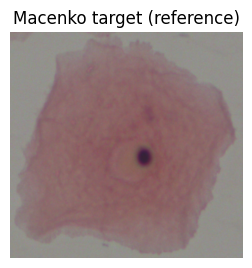

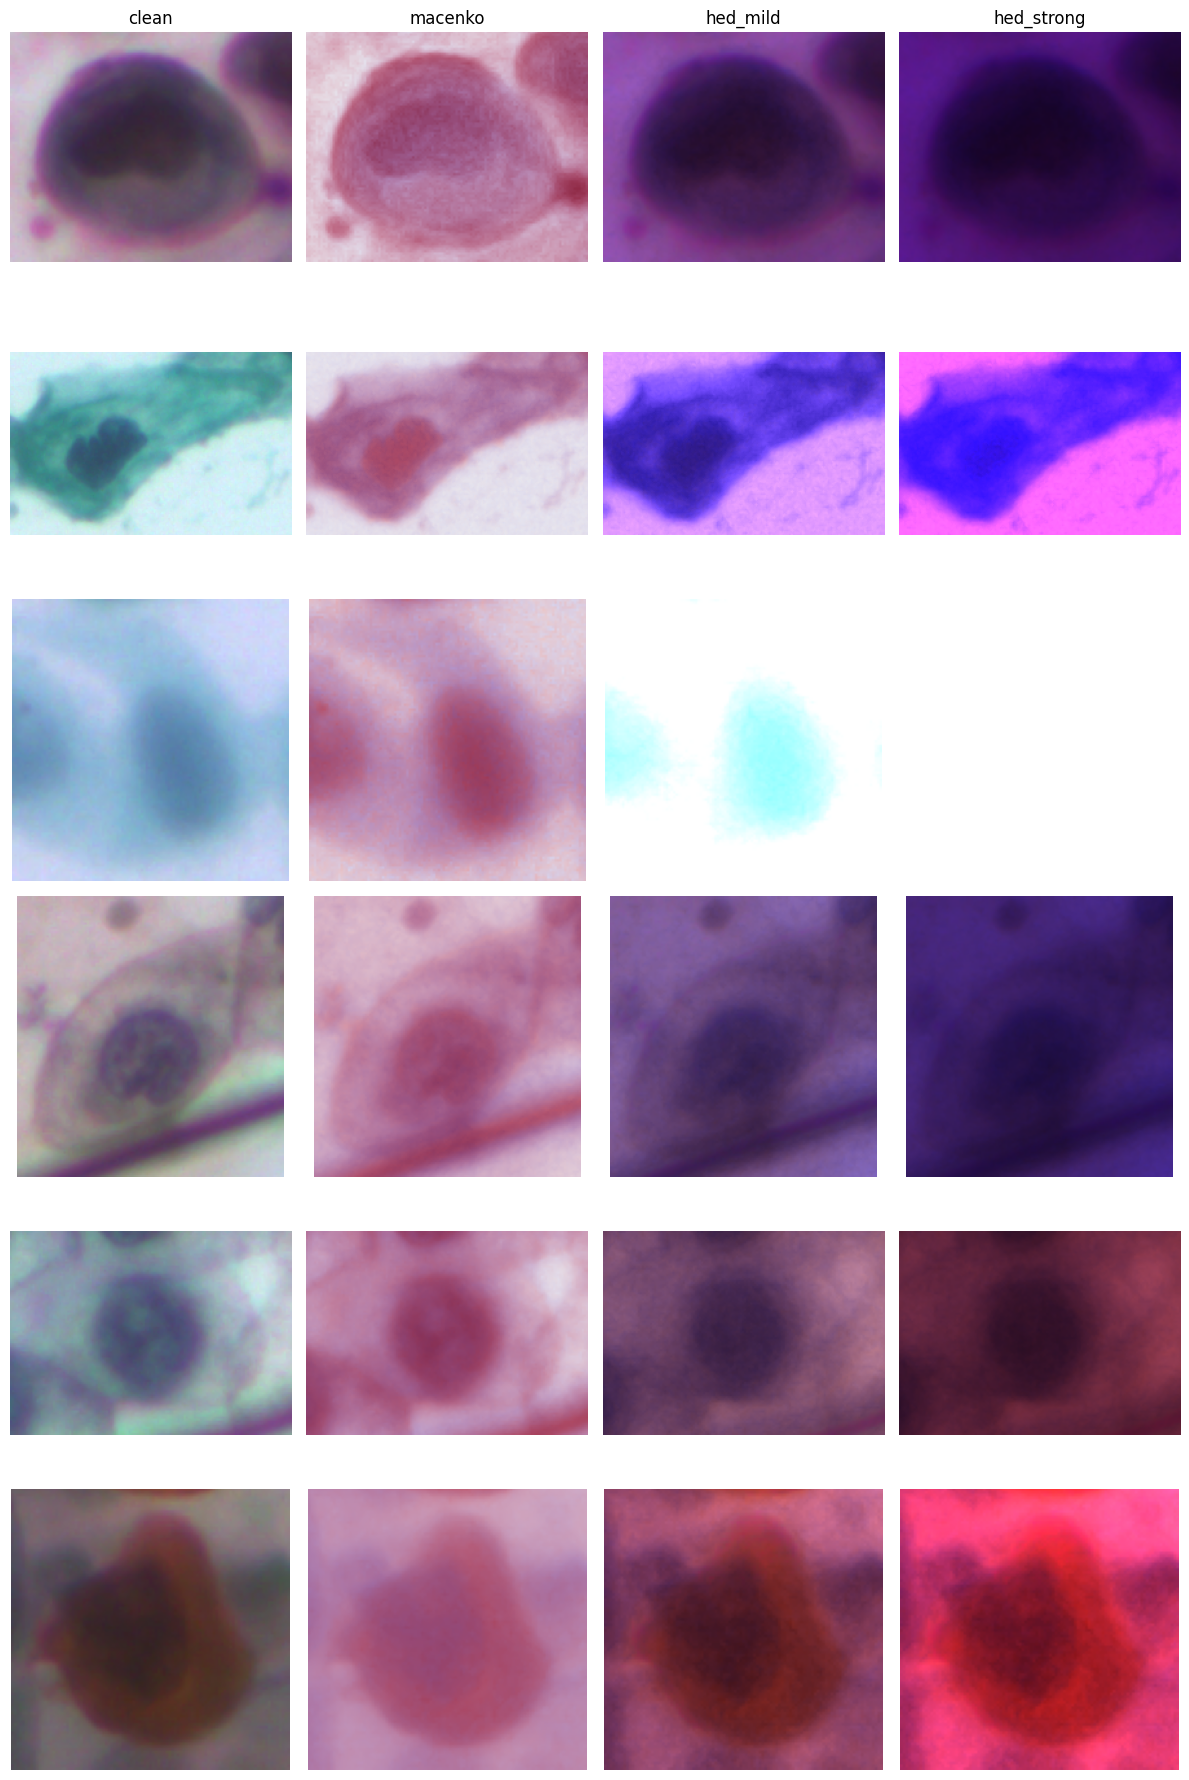

1) Coverage by shift, group split (target 0.90)
model      efficientnet_b0              resnet50             vit_base_patch16_224            
method           clean-cal pooled-LOFO clean-cal pooled-LOFO            clean-cal pooled-LOFO
shift                                                                                        
brightness           0.867       0.990     0.717       0.977                0.902       0.995
contrast             0.865       0.987     0.876       0.995                0.914       0.993
hed_mild             0.685       0.859     0.649       0.891                0.649       0.795
hed_strong           0.455       0.714     0.369       0.741                0.408       0.569
hue                  0.907       0.995     0.919       0.992                0.894       0.993
macenko              0.582       0.816     0.563       0.816                0.629       0.885
saturation           0.841       0.993     0.711       0.920                0.899       0.993

2) Mean cov

In [12]:
# Paste each CELL into a new Kaggle cell and run after stain_shift_cells.py (Cell 3 and Cell 4).
# Both cells take seconds. They use SHIFTS, VL, TL, YV, YT, conformal_sets, fit_temperature, ece from earlier cells.


# %% ===================== CELL 5: visual check of the shifts (is Macenko sane?) =====================
import numpy as np, matplotlib.pyplot as plt
from PIL import Image

ref = Image.open(df["path"].iloc[0]).convert("RGB")
idx = df.sample(6, random_state=1).index
names = ["clean", "macenko", "hed_mild", "hed_strong"]

plt.figure(figsize=(3, 3)); plt.imshow(ref); plt.axis("off")
plt.title("Macenko target (reference)"); plt.show()

fig, ax = plt.subplots(len(idx), len(names), figsize=(3 * len(names), 3 * len(idx)))
for r, i in enumerate(idx):
    img = Image.open(df.loc[i, "path"]).convert("RGB")
    for c, n in enumerate(names):
        out = SHIFTS[n](img, np.random.default_rng(1000 + int(i)))
        ax[r, c].imshow(out); ax[r, c].axis("off")
        if r == 0:
            ax[r, c].set_title(n)
plt.tight_layout(); plt.savefig("shift_samples.png", dpi=120); plt.show()


# %% ===================== CELL 6: leave-one-FAMILY-out conformal calibration =====================
# Stricter than Cell 4: when testing on a shift, the calibration pool excludes the whole family
# (both hed shifts, or all photometric shifts), so the pool never contains a similar shift.
import torch, pandas as pd
import torch.nn.functional as F

FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}
ALPHA = 0.1
rows = []
for split in ["random", "group"]:
    yv, yt = YV[split], YT[split]
    for name in MODELS:
        T0 = fit_temperature(VL[(split, name, "clean")], yv)
        cal_clean = F.softmax(VL[(split, name, "clean")] / T0, 1)
        for sh in SHIFTS:
            if sh == "clean":
                continue
            tl = TL[(split, name, sh)]
            pool = [s for s in SHIFTS if FAMILY[s] != FAMILY[sh]]      # always contains clean
            pool_l = torch.cat([VL[(split, name, s)] for s in pool])
            pool_y = yv.repeat(len(pool))
            Tp = fit_temperature(pool_l, pool_y)

            for method, cal_p, cal_y, T in [("clean-cal", cal_clean, yv, T0),
                                            ("pooled-LOFO", F.softmax(pool_l / Tp, 1), pool_y, Tp)]:
                sets = conformal_sets(cal_p, cal_y, F.softmax(tl / T, 1), ALPHA)
                rows.append(dict(split=split, model=name, shift=sh, family=FAMILY[sh], method=method,
                                 coverage=sets[torch.arange(len(yt)), yt].float().mean().item(),
                                 avg_size=sets.sum(1).float().mean().item(),
                                 ece=ece(tl / T, yt)))

L = pd.DataFrame(rows)
L.to_csv("lofo_results.csv", index=False)
pd.set_option("display.width", 200)

print("1) Coverage by shift, group split (target 0.90)")
print(L[L.split == "group"].pivot_table(index="shift", columns=["model", "method"], values="coverage").round(3))

print("\n2) Mean coverage by shift FAMILY (all models, both splits)")
print(L.pivot_table(index="family", columns="method", values="coverage").round(3))

print("\n3) Summary: mean / worst coverage and mean set size")
print(L.groupby(["split", "model", "method"])
        .agg(cov_mean=("coverage", "mean"), cov_worst=("coverage", "min"),
             size_mean=("avg_size", "mean")).round(3))

In [13]:
# Run after stain_shift_cells.py (Cell 3, 4) and macenko_lofo_cells.py (Cell 6).
# CELL 3b  (~8 min): milder HED shifts + sanity check + re-collect logits.  Then re-run Cell 4 and Cell 6 (seconds).
# CELL 7   (~12-15 min per model): stain-augmented training vs baseline, same shifts, same conformal protocol.


# %% ===================== CELL 3b: fix the HED shifts, sanity-check, re-collect logits =====================
import time
import numpy as np, torch
from PIL import Image
from skimage.color import rgb2hed, hed2rgb


def hed_jitter_v2(s):
    """Scale stain concentrations only (no additive offset, which bleached pale cells to white)."""
    def f(img, rng):
        a = np.asarray(img).astype(np.float64) / 255
        hed = rgb2hed(a) * rng.uniform(1 - s, 1 + s, 3)
        return Image.fromarray((np.clip(hed2rgb(hed), 0, 1) * 255).astype(np.uint8))
    return f


SHIFTS["hed_mild"] = hed_jitter_v2(0.15)
SHIFTS["hed_strong"] = hed_jitter_v2(0.30)


def frac_destroyed(fn, n=150):
    """Share of images that come out almost entirely white (information destroyed)."""
    bad = 0
    for i in df.sample(n, random_state=2).index:
        out = np.asarray(fn(Image.open(df.loc[i, "path"]).convert("RGB"), np.random.default_rng(1000 + int(i))))
        bad += (out.min(2) > 240).mean() > 0.95
    return bad / n


for k, f in SHIFTS.items():
    print(f"{k:10s} images that became >95% white: {frac_destroyed(f):.1%}")

VL, TL, YV, YT = {}, {}, {}, {}
for split, fn in [("random", random_split), ("group", group_split)]:
    tr, va, te = fn(df, 0)
    models = {n: load_ckpt(n, split) for n in MODELS}
    for sh, f in SHIFTS.items():
        t0 = time.time()
        Xv, YV[split] = materialize(va, f)
        Xt, YT[split] = materialize(te, f)
        for n, m in models.items():
            VL[(split, n, sh)] = collect(m, Xv)
            TL[(split, n, sh)] = collect(m, Xt)
        del Xv, Xt
        print(f"[{split}] {sh:10s} done in {time.time() - t0:.0f}s")
    del models; torch.cuda.empty_cache()
torch.save(dict(VL=VL, TL=TL, YV=YV, YT=YT), "shift_logits_v2.pt")
# now re-run Cell 4 and Cell 6 unchanged


# %% ===================== CELL 7: stain-augmented training vs baseline =====================
import pandas as pd
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score

SPLIT = "group"
AUG_MODELS = ["resnet50"]            # add "efficientnet_b0" if time allows
ALPHA = 0.1
FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}


class AugDS(Dataset):
    """Train-time stain augmentation: random HED concentration scaling (strength up to 0.35) on 70% of images."""
    def __init__(self, d, p=0.7):
        self.p, self.y, self.prob = d["path"].tolist(), d["y"].tolist(), p
    def __len__(self):
        return len(self.p)
    def __getitem__(self, i):
        img = Image.open(self.p[i]).convert("RGB")
        rng = np.random.default_rng()
        if rng.random() < self.prob:
            img = hed_jitter_v2(rng.uniform(0.05, 0.35))(img, rng)
        return train_tf(img), self.y[i]


def train_stainaug(name, split):
    seed_all(0)
    tr, va, te = (random_split if split == "random" else group_split)(df, 0)
    dl_tr = DataLoader(AugDS(tr), batch_size=BS, shuffle=True, num_workers=2)
    dl_va = loader(va, eval_tf, False)
    model = timm.create_model(name, pretrained=True, num_classes=len(classes)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LRS.get(name, LR), weight_decay=1e-4)
    best, state = -1.0, None
    for ep in range(EPOCHS):
        loss = run_epoch(model, dl_tr, opt)
        vl, vy = get_logits(model, dl_va)
        f1 = f1_score(vy.numpy(), vl.argmax(1).numpy(), average="macro")
        print(f"  ep{ep + 1:2d} train loss {loss:.3f} | val macro-F1 {f1:.3f}")
        if f1 > best:
            best, state = f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(state)
    torch.save(model.state_dict(), f"ckpt_{split}_{name}_stainaug_s0.pt")
    return model.eval()


def eval_logits(VLd, TLd, yv, yt, tag):
    T0 = fit_temperature(VLd["clean"], yv)
    cal_clean = F.softmax(VLd["clean"] / T0, 1)
    rows = []
    for sh in SHIFTS:
        tl = TLd[sh]
        out = dict(model=tag, shift=sh, family=FAMILY[sh],
                   macro_f1=f1_score(yt.numpy(), tl.argmax(1).numpy(), average="macro"))
        pool = [s for s in SHIFTS if FAMILY[s] != FAMILY[sh]]       # leave-one-family-out
        pl = torch.cat([VLd[s] for s in pool]); py = yv.repeat(len(pool))
        Tp = fit_temperature(pl, py)
        for meth, cp, cy, T in [("clean", cal_clean, yv, T0), ("lofo", F.softmax(pl / Tp, 1), py, Tp)]:
            sets = conformal_sets(cp, cy, F.softmax(tl / T, 1), ALPHA)
            out[f"cov_{meth}"] = sets[torch.arange(len(yt)), yt].float().mean().item()
            out[f"size_{meth}"] = sets.sum(1).float().mean().item()
        rows.append(out)
    return pd.DataFrame(rows)


tr, va, te = (random_split if SPLIT == "random" else group_split)(df, 0)
yv, yt = YV[SPLIT], YT[SPLIT]
allr = []
for name in AUG_MODELS:
    base = eval_logits({s: VL[(SPLIT, name, s)] for s in SHIFTS}, {s: TL[(SPLIT, name, s)] for s in SHIFTS},
                       yv, yt, f"{name}-baseline")
    print(f"\n[{SPLIT} | {name} | stain-aug training]")
    t0 = time.time()
    m = train_stainaug(name, SPLIT)
    print(f"  trained in {time.time() - t0:.0f}s")
    AVL, ATL = {}, {}
    for sh, f in SHIFTS.items():
        Xv, _ = materialize(va, f); Xt, _ = materialize(te, f)
        AVL[sh], ATL[sh] = collect(m, Xv), collect(m, Xt)
        del Xv, Xt
    del m; torch.cuda.empty_cache()
    aug = eval_logits(AVL, ATL, yv, yt, f"{name}-stainaug")
    allr += [base, aug]

C = pd.concat(allr)
C.to_csv("stainaug_comparison.csv", index=False)
pd.set_option("display.width", 200)
for col, title in [("macro_f1", "Macro-F1"), ("cov_clean", "Coverage, clean calibration"),
                   ("cov_lofo", "Coverage, pooled leave-one-family-out calibration")]:
    print(f"\n{title} by shift")
    print(C.pivot(index="shift", columns="model", values=col).round(3))
print("\nMean by shift family")
print(C.groupby(["model", "family"])[["macro_f1", "cov_clean", "cov_lofo", "size_lofo"]].mean().round(3))

clean      images that became >95% white: 0.0%
hed_mild   images that became >95% white: 0.0%
hed_strong images that became >95% white: 0.0%
brightness images that became >95% white: 0.0%
contrast   images that became >95% white: 0.0%
saturation images that became >95% white: 0.0%
hue        images that became >95% white: 0.0%
macenko    images that became >95% white: 0.0%
[random] clean      done in 26s
[random] hed_mild   done in 28s
[random] hed_strong done in 27s
[random] brightness done in 26s
[random] contrast   done in 25s
[random] saturation done in 25s
[random] hue        done in 28s
[random] macenko    done in 54s
[group] clean      done in 28s
[group] hed_mild   done in 29s
[group] hed_strong done in 30s
[group] brightness done in 27s
[group] contrast   done in 27s
[group] saturation done in 27s
[group] hue        done in 29s
[group] macenko    done in 56s

[group | resnet50 | stain-aug training]
  ep 1 train loss 1.486 | val macro-F1 0.625
  ep 2 train loss 0.977 | val macr

In [15]:
import os
for root, dirs, files in os.walk("/kaggle/input"):
    depth = root.replace("/kaggle/input", "").count(os.sep)
    if depth <= 4:
        print("  " * depth + os.path.basename(root), "| subfolders:", len(dirs), "| files:", len(files))

input | subfolders: 1 | files: 0
  datasets | subfolders: 1 | files: 0
    prahladmehandiratta | subfolders: 1 | files: 0
      cervical-cancer-largest-dataset-sipakmed | subfolders: 5 | files: 0
        im_Dyskeratotic | subfolders: 1 | files: 0
        im_Koilocytotic | subfolders: 1 | files: 0
        im_Metaplastic | subfolders: 1 | files: 0
        im_Parabasal | subfolders: 1 | files: 0
        im_Superficial-Intermediate | subfolders: 1 | files: 0


In [17]:
# CELL 10 (~2-3 min). Run right after Cell 9 in the same kernel. Uses specs, dl_h, yh, ABN, get_logits,
# fit_temperature, VL, TL, YV, YT, AVL, ATL, SHIFTS, bin_metrics from earlier cells.
# Part A: bootstrap 95% CIs for Herlev AUROC and paired differences.
# Part B: conformal prediction on the binary normal/abnormal label, calibrated with a few labeled Herlev images
#         (disjoint from the images it is tested on), compared with SIPaKMeD-only calibration.


# %% ===================== CELL 10 =====================
import math, os
import numpy as np, pandas as pd, torch, timm
import torch.nn.functional as F
from sklearn.metrics import roc_auc_score

ALPHA, B, R, NS = 0.1, 1000, 100, [20, 50, 100, 200]
rng = np.random.default_rng(0)
ABN_T = torch.tensor(ABN)
yv_bin = torch.isin(yv_g, ABN_T).long()
N = len(yh)


def bin_probs(logits, T):
    pa = F.softmax(logits / T, 1)[:, ABN].sum(1)
    return torch.stack([1 - pa, pa], 1)                        # col 0 = normal, col 1 = abnormal


def conf_bin(cal_P, cal_y, test_P, alpha=ALPHA):
    s = 1 - cal_P[torch.arange(len(cal_y)), cal_y]
    n = len(s)
    k = math.ceil((n + 1) * (1 - alpha))
    q = float("inf") if k > n else torch.sort(s).values[k - 1].item()
    return (1 - test_P) <= q


def cov_stats(sets, y):
    cov = sets[torch.arange(len(y)), y].float()
    return dict(cov=cov.mean().item(), cov_normal=cov[y == 0].mean().item(),
                cov_abnormal=cov[y == 1].mean().item(),
                size=sets.sum(1).float().mean().item(), singleton=(sets.sum(1) == 1).float().mean().item())


HL, P0, SRC = {}, {}, {}
for tag, name, ck in specs:
    if not os.path.exists(ck):
        print("missing", ck); continue
    m = timm.create_model(name, pretrained=False, num_classes=len(classes))
    m.load_state_dict(torch.load(ck, map_location="cpu"))
    m = m.to(DEVICE).eval()
    hl, _ = get_logits(m, dl_h)
    del m; torch.cuda.empty_cache()
    vd = AVL if tag.endswith("stainaug") else {s: VL[("group", name, s)] for s in SHIFTS}
    T0 = fit_temperature(vd["clean"], yv_g)
    pl = torch.cat([vd[s] for s in SHIFTS]); py = yv_g.repeat(len(SHIFTS))
    Tp = fit_temperature(pl, py)
    HL[tag] = hl
    P0[tag] = bin_probs(hl, T0)
    SRC[tag] = dict(
        clean=(bin_probs(vd["clean"], T0), yv_bin, P0[tag]),
        pooled=(bin_probs(pl, Tp), torch.isin(py, ABN_T).long(), bin_probs(hl, Tp)))
torch.save(HL, "herlev_logits.pt")

# ---------------- Part A: bootstrap CIs ----------------
yb = yh.numpy()
boots = rng.integers(0, N, (B, N))
auc = {t: np.array([roc_auc_score(yb[b], P0[t][b, 1].numpy()) for b in boots]) for t in P0}
rowsA = [dict(model=t, auroc=roc_auc_score(yb, P0[t][:, 1].numpy()),
              ci_lo=np.percentile(a, 2.5), ci_hi=np.percentile(a, 97.5)) for t, a in auc.items()]
print("A1) Herlev AUROC with 95% bootstrap CI")
print(pd.DataFrame(rowsA).round(3).to_string(index=False))

ref = "resnet50-baseline"
rowsD = []
for t in auc:
    if t == ref:
        continue
    d = auc[t] - auc[ref]
    rowsD.append(dict(comparison=f"{t} - {ref}", diff=d.mean(), ci_lo=np.percentile(d, 2.5),
                      ci_hi=np.percentile(d, 97.5), p_diff_gt0=(d > 0).mean()))
print("\nA2) Paired AUROC difference vs ResNet50 baseline (same bootstrap resamples)")
print(pd.DataFrame(rowsD).round(3).to_string(index=False))

# ---------------- Part B: few-shot target calibration ----------------
rowsB = []
for t in P0:
    for meth, (cP, cy, tP) in [("source-cal (clean val)", SRC[t]["clean"]),
                               ("source-cal (pooled shifts)", SRC[t]["pooled"])]:
        rowsB.append(dict(model=t, method=meth, n=0, cov_sd=np.nan, **cov_stats(conf_bin(cP, cy, tP), yh)))
    P = P0[t]
    for n in NS:
        draws = []
        for _ in range(R):
            perm = torch.tensor(rng.permutation(N))
            cal, test = perm[:n], perm[n:]
            draws.append(cov_stats(conf_bin(P[cal], yh[cal], P[test]), yh[test]))
        D = pd.DataFrame(draws)
        rowsB.append(dict(model=t, method="target-cal (labeled Herlev)", n=n,
                          cov_sd=D["cov"].std(), **D.mean().to_dict()))

Bdf = pd.DataFrame(rowsB)
Bdf.to_csv("herlev_fewshot_conformal.csv", index=False)
pd.set_option("display.width", 220)
print("\nB) Binary conformal coverage on Herlev (target 0.90). n = labeled Herlev images used for calibration")
print(Bdf.round(3).to_string(index=False))

A1) Herlev AUROC with 95% bootstrap CI
                   model  auroc  ci_lo  ci_hi
       resnet50-baseline  0.668  0.626  0.709
efficientnet_b0-baseline  0.688  0.642  0.729
            vit-baseline  0.752  0.710  0.790
       resnet50-stainaug  0.733  0.689  0.772

A2) Paired AUROC difference vs ResNet50 baseline (same bootstrap resamples)
                                  comparison  diff  ci_lo  ci_hi  p_diff_gt0
efficientnet_b0-baseline - resnet50-baseline 0.019 -0.017  0.055       0.863
            vit-baseline - resnet50-baseline 0.083  0.053  0.114       1.000
       resnet50-stainaug - resnet50-baseline 0.064  0.033  0.095       1.000

B) Binary conformal coverage on Herlev (target 0.90). n = labeled Herlev images used for calibration
                   model                      method   n  cov_sd   cov  cov_normal  cov_abnormal  size  singleton
       resnet50-baseline      source-cal (clean val)   0     NaN 0.327       0.269         0.348 0.406      0.406
       resnet50-

In [20]:
# FINAL BATCH 1 (corrected): 5-seed training + CIs + leakage verdict
# near-duplicate audit showed ~0 near-dups under strict rules, so the random_dedup arm is dropped.
# Run order: CELL A (replaces your cell 8), then CELL B.
# Needs from earlier cells: df, classes, MODELS, DEVICE, LR, IMG, loader, train_tf, eval_tf,
#   run_epoch, get_logits, fit_temperature, metrics, random_split, group_split, seed_all.
# Resumes from baseline_results.csv, so finished (split, seed, model) runs are skipped.


# %% ===================== CELL A: baseline training, 5 seeds (replaces cell 8) =====================
import copy, gc, os, time
import numpy as np, pandas as pd, torch, timm
from sklearn.metrics import f1_score

EPOCHS = 10
SEEDS = [0, 1, 2, 3, 4]
LRS = {"vit_base_patch16_224": 3e-5}
RESULTS = "baseline_results.csv"

rows, done = [], set()
if os.path.exists(RESULTS):
    prev = pd.read_csv(RESULTS)
    prev = prev[prev["split"].isin(["random", "group"])]        # drop any partial random_dedup rows
    rows = prev.to_dict("records")
    done = {(r["split"], int(r["seed"]), r["model"]) for r in rows}


def train_model(name, dl_tr, dl_va):
    model = timm.create_model(name, pretrained=True, num_classes=len(classes)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LRS.get(name, LR), weight_decay=1e-4)
    best_f1, best_state = -1.0, None
    for ep in range(EPOCHS):
        loss = run_epoch(model, dl_tr, opt)
        vl, vy = get_logits(model, dl_va)
        f1 = f1_score(vy.numpy(), vl.argmax(1).numpy(), average="macro")
        print(f"  ep{ep+1:2d} train loss {loss:.3f} | val macro-F1 {f1:.3f}")
        if f1 > best_f1:
            best_f1 = f1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model


for seed in SEEDS:
    for split_name, splitter in [("random", random_split), ("group", group_split)]:
        seed_all(seed)
        tr, va, te = splitter(df, seed)
        dl_tr, dl_va, dl_te = loader(tr, train_tf, True), loader(va, eval_tf, False), loader(te, eval_tf, False)
        for name in MODELS:
            if (split_name, seed, name) in done:
                print("skip", split_name, seed, name); continue
            print(f"\n[{split_name} | seed {seed} | {name}]")
            t0 = time.time()
            model = train_model(name, dl_tr, dl_va)
            vl, vy = get_logits(model, dl_va)
            tl, ty = get_logits(model, dl_te)
            Tt = fit_temperature(vl, vy)
            for cal in (False, True):
                m = metrics(tl, ty, Tt if cal else 1.0)
                rows.append(dict(split=split_name, seed=seed, model=name,
                                 temp=Tt, calibrated=cal, **m))
            torch.save(model.state_dict(), f"ckpt_{split_name}_{name}_s{seed}.pt")
            pd.DataFrame(rows).to_csv(RESULTS, index=False)       # saved after every run
            print(f"  test macro-F1 {rows[-2]['macro_f1']:.3f} | ECE {rows[-2]['ece']:.3f} -> {rows[-1]['ece']:.3f} "
                  f"| T {Tt:.2f} | {time.time()-t0:.0f}s")
            del model; gc.collect(); torch.cuda.empty_cache()

print("\nAll seeds finished.")


# %% ===================== CELL B: mean, 95% CI and leakage verdict =====================
import numpy as np, pandas as pd
from scipy import stats

RESULTS = "baseline_results.csv"


def mean_ci(x, level=0.95):
    x = np.asarray(x, float); n = len(x); m = x.mean()
    if n < 2:
        return m, np.nan, np.nan
    h = stats.t.ppf(0.5 + level / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return m, m - h, m + h


def summarize(res, metric="macro_f1", calibrated=False):
    r = res[res["calibrated"] == calibrated]
    out = []
    for (split, model), g in r.groupby(["split", "model"]):
        m, lo, hi = mean_ci(g[metric])
        out.append(dict(split=split, model=model, n_seeds=len(g), mean=m, ci_lo=lo, ci_hi=hi))
    return pd.DataFrame(out).round(4)


def gap_table(res, a, b, metric="macro_f1"):
    """Per-seed difference (split a minus split b), mean and 95% CI over seeds."""
    r = res[~res["calibrated"]]
    out = []
    for model in sorted(r["model"].unique()):
        A = r[(r.split == a) & (r.model == model)].set_index("seed")[metric]
        B = r[(r.split == b) & (r.model == model)].set_index("seed")[metric]
        seeds = A.index.intersection(B.index)
        if len(seeds) == 0:
            continue
        d = (A[seeds] - B[seeds]).values
        m, lo, hi = mean_ci(d)
        out.append(dict(model=model, gap=f"{a} - {b}", n_seeds=len(d), mean_gap=m,
                        ci_lo=lo, ci_hi=hi,
                        ci_includes_0=(bool(lo <= 0 <= hi) if not np.isnan(lo) else "n/a")))
    return pd.DataFrame(out).round(4)




res = pd.read_csv(RESULTS)
res = res[res["split"].isin(["random", "group"])]
print("Macro-F1 (uncalibrated), mean and 95% CI over seeds"); print(summarize(res, "macro_f1").to_string(index=False))
print("\nECE before temperature scaling");                   print(summarize(res, "ece", False).to_string(index=False))
print("\nECE after temperature scaling");                    print(summarize(res, "ece", True).to_string(index=False))

gaps = gap_table(res, "random", "group")
gaps.to_csv("leakage_gap_table.csv", index=False)
print("\nLeakage inflation gap, random minus group"); print(gaps.to_string(index=False))

print("\nVerdict per model (random minus group):")
for _, r in gaps.iterrows():
    if r.ci_includes_0 == "n/a":
        print(f"  {r.model}: only {r.n_seeds} seed, no CI yet")
    elif r.ci_includes_0:
        print(f"  {r.model}: gap {r.mean_gap:+.4f}, 95% CI [{r.ci_lo:+.4f}, {r.ci_hi:+.4f}] -> no detectable inflation")
    elif r.mean_gap > 0:
        print(f"  {r.model}: gap {r.mean_gap:+.4f}, 95% CI [{r.ci_lo:+.4f}, {r.ci_hi:+.4f}] -> random split inflates F1")
    else:
        print(f"  {r.model}: gap {r.mean_gap:+.4f}, 95% CI [{r.ci_lo:+.4f}, {r.ci_hi:+.4f}] -> group split is easier, not harder")

skip random 0 resnet50
skip random 0 efficientnet_b0
skip random 0 vit_base_patch16_224
skip group 0 resnet50
skip group 0 efficientnet_b0
skip group 0 vit_base_patch16_224

[random | seed 1 | resnet50]
  ep 1 train loss 1.441 | val macro-F1 0.782
  ep 2 train loss 0.815 | val macro-F1 0.885
  ep 3 train loss 0.422 | val macro-F1 0.929
  ep 4 train loss 0.332 | val macro-F1 0.927
  ep 5 train loss 0.250 | val macro-F1 0.928
  ep 6 train loss 0.239 | val macro-F1 0.952
  ep 7 train loss 0.202 | val macro-F1 0.955
  ep 8 train loss 0.179 | val macro-F1 0.950
  ep 9 train loss 0.155 | val macro-F1 0.970
  ep10 train loss 0.132 | val macro-F1 0.962
  test macro-F1 0.964 | ECE 0.012 -> 0.017 | T 0.75 | 359s

[random | seed 1 | efficientnet_b0]
  ep 1 train loss 0.958 | val macro-F1 0.811
  ep 2 train loss 0.396 | val macro-F1 0.856
  ep 3 train loss 0.279 | val macro-F1 0.883
  ep 4 train loss 0.214 | val macro-F1 0.887
  ep 5 train loss 0.165 | val macro-F1 0.907
  ep 6 train loss 0.175 | 

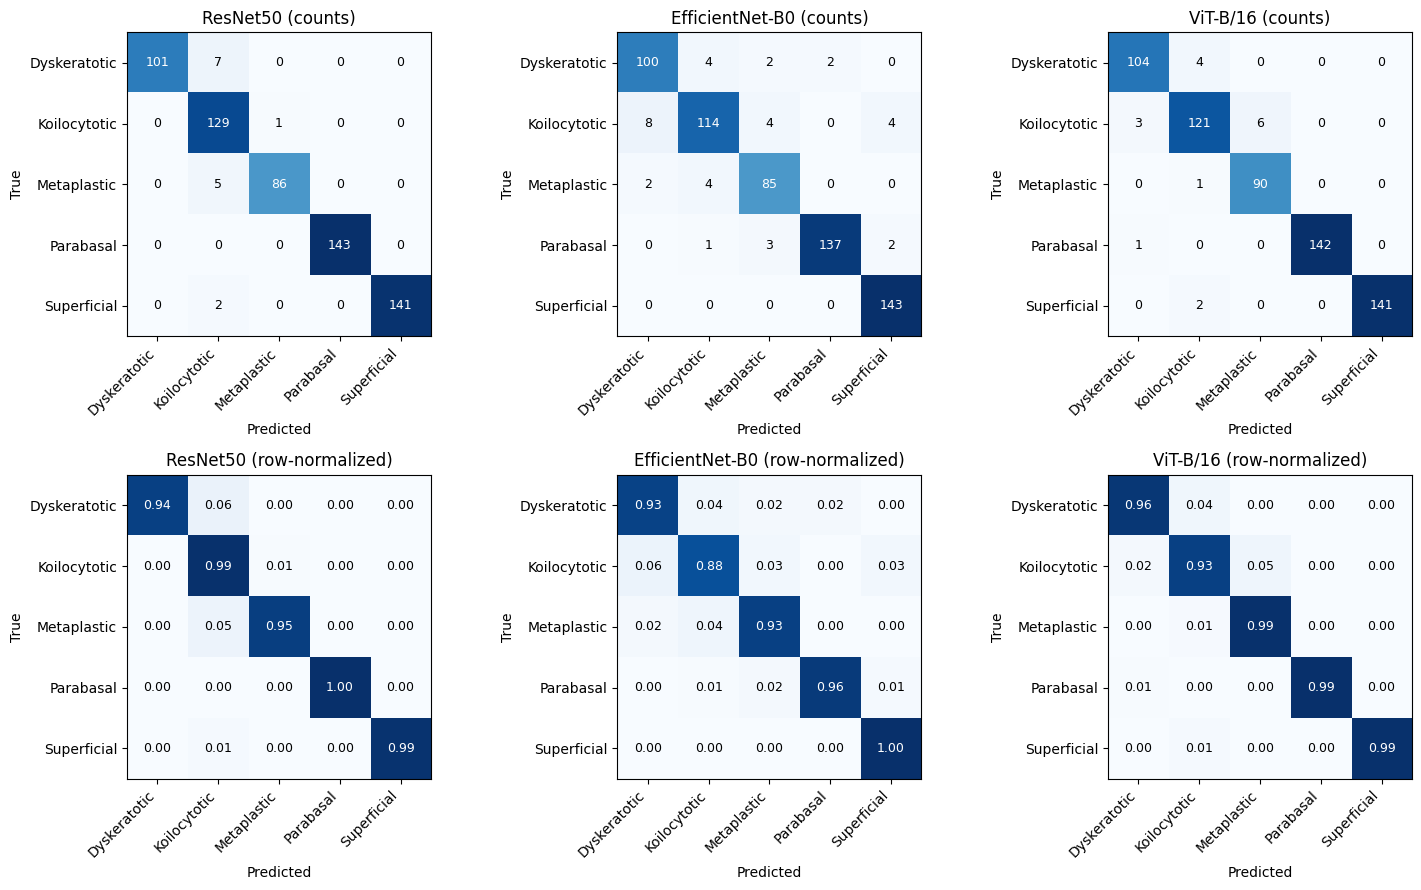

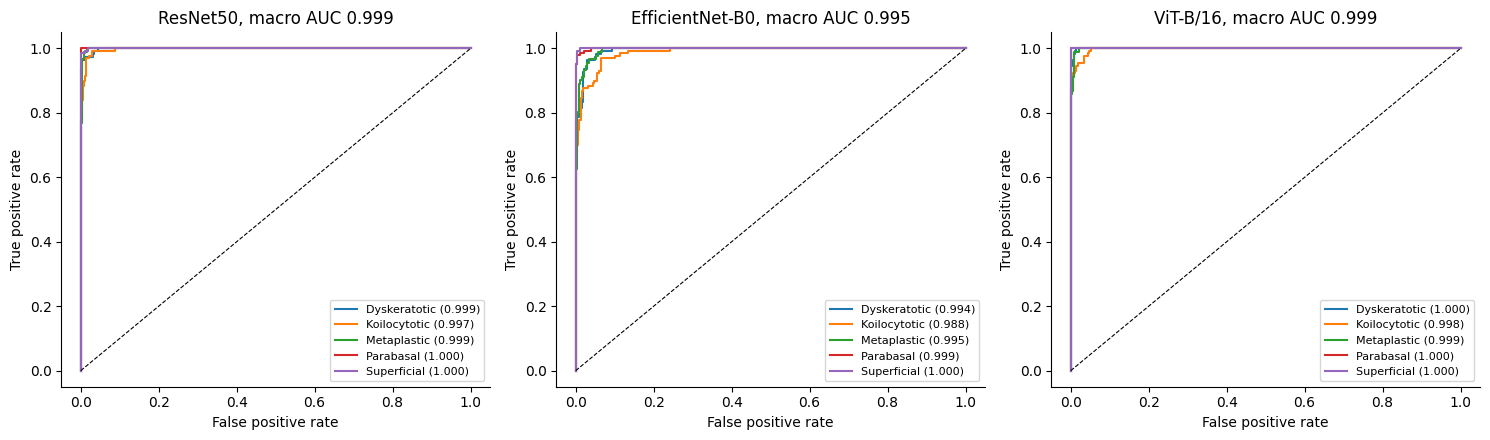

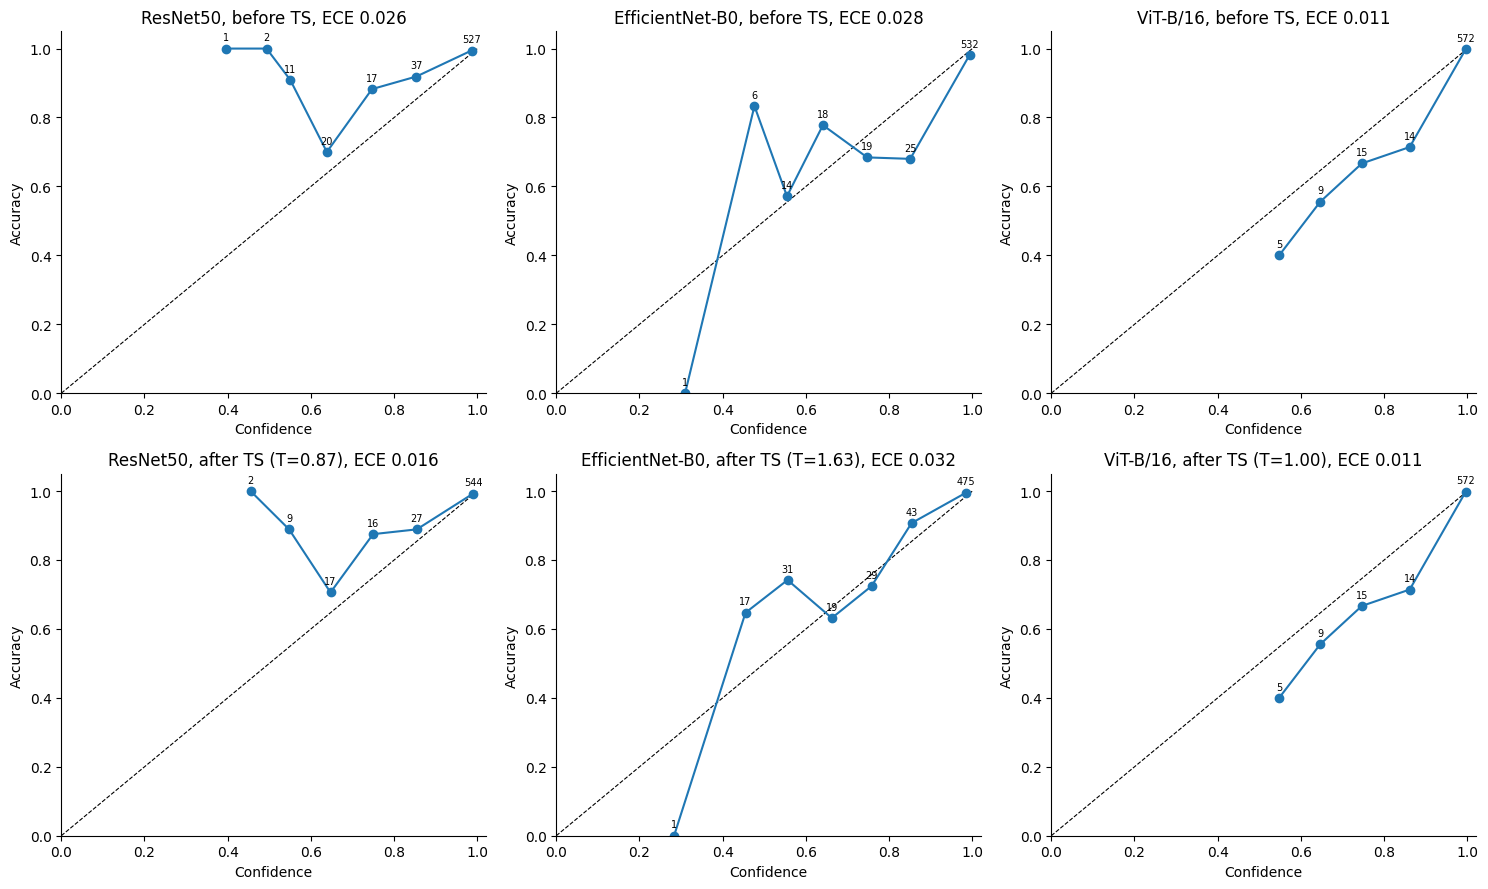

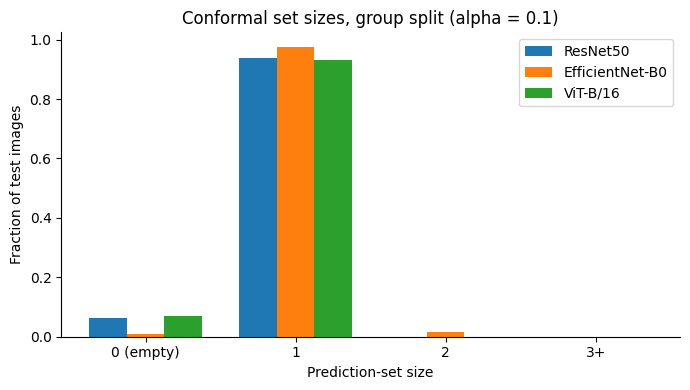

split                model    acc  macro_f1  macro_auc  ece_before  ece_after      T
group             resnet50 0.9756    0.9742     0.9990      0.0259     0.0158 0.8720
group      efficientnet_b0 0.9415    0.9377     0.9954      0.0277     0.0316 1.6285
group vit_base_patch16_224 0.9724    0.9706     0.9992      0.0111     0.0111 0.9999
model      efficientnet_b0                          resnet50                         vit_base_patch16_224                        
method           clean-cal pooled-LOFO pooled-LOSO clean-cal pooled-LOFO pooled-LOSO            clean-cal pooled-LOFO pooled-LOSO
shift                                                                                                                            
brightness           0.867       0.972       0.954     0.717       0.959       0.946                0.902       0.971       0.961
clean                0.941       0.990       0.990     0.925       0.990       0.990                0.928       0.974       0.974
contrast  

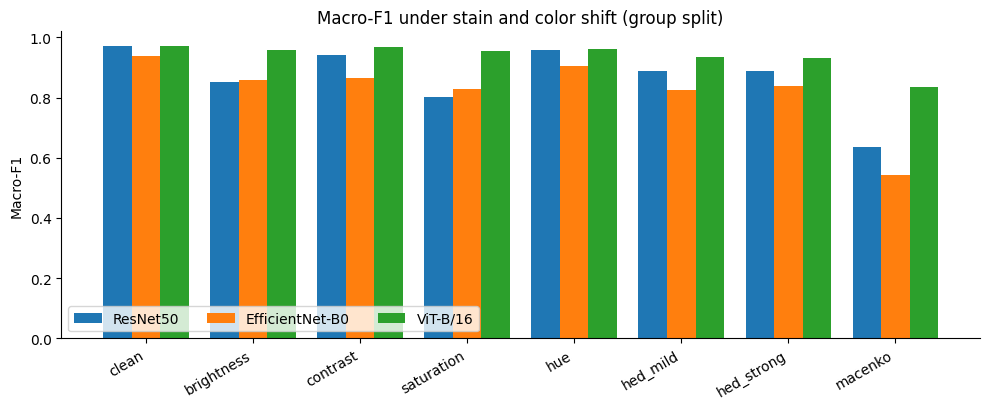

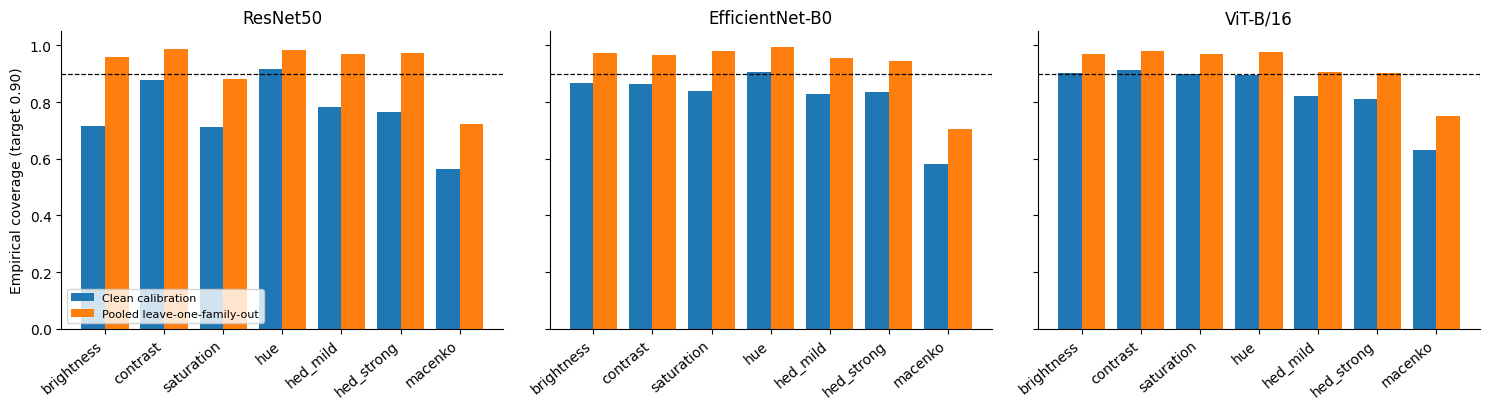

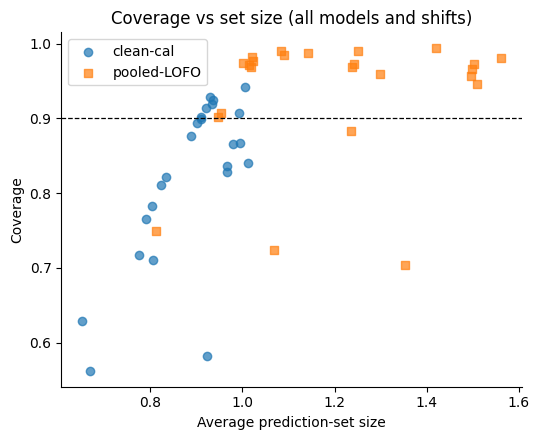

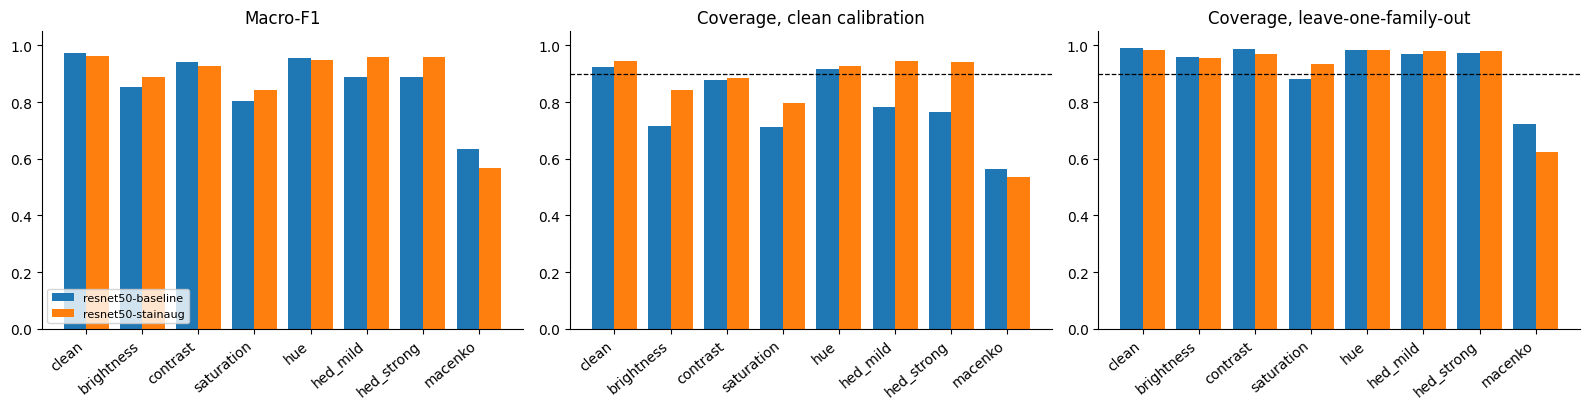

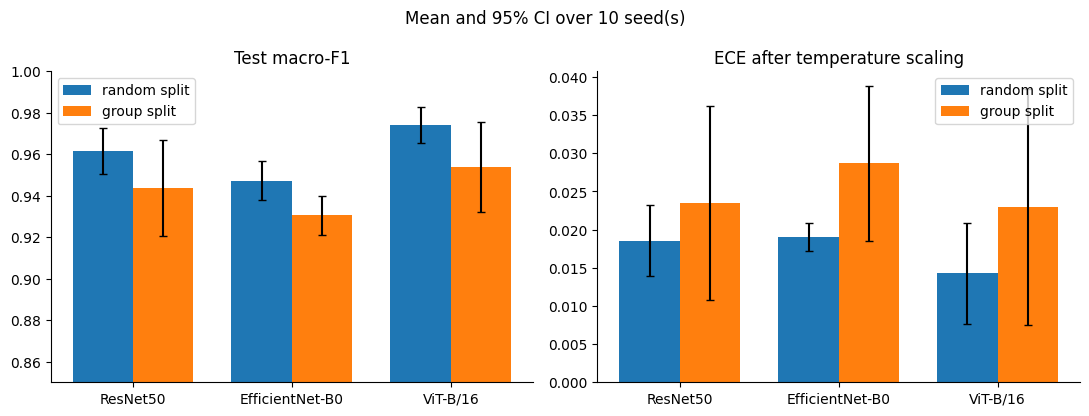

['baseline_results.csv', 'classification_report_group_efficientnet_b0.csv', 'classification_report_group_resnet50.csv', 'classification_report_group_vit_base_patch16_224.csv', 'conformal_baseline.csv', 'fig_confusion_group.pdf', 'fig_confusion_group.png', 'fig_coverage_by_shift.pdf', 'fig_coverage_by_shift.png', 'fig_coverage_vs_size.pdf', 'fig_coverage_vs_size.png', 'fig_f1_by_shift.pdf', 'fig_f1_by_shift.png', 'fig_leakage_gap.pdf', 'fig_leakage_gap.png', 'fig_reliability_group.pdf', 'fig_reliability_group.png', 'fig_roc_group.pdf', 'fig_roc_group.png', 'fig_setsize_group.pdf', 'fig_setsize_group.png', 'fig_stainaug_vs_baseline.pdf', 'fig_stainaug_vs_baseline.png', 'leakage_gap_table.csv', 'near_dup_audit.csv', 'shift_results_v2.csv', 'stainaug_comparison.csv', 'table_seed0_summary.csv', 'table_shift_results_v2.csv']
Download figures_and_tables.zip from the Output tab.


In [21]:
# RESULTS AND FIGURES EXPORT: confusion matrices, ROC, reliability, shift figures, leakage figure, tables
# Run order: F0, F1, F2, F3, F4, F5. Run AFTER the 5-seed training cell finishes (same kernel, GPU free).
# Everything is saved under figures/ as PNG (300 dpi) and PDF, tables as CSV, and zipped at the end (F5).
# F1 needs: df, classes, MODELS, DEVICE, loader, eval_tf, get_logits, fit_temperature, ece, conformal_sets,
#           random_split, group_split, and the ckpt_{split}_{model}_s0.pt files.
# F2 needs: shift_logits_v2.pt (saved by your cell 12) and conformal_sets, fit_temperature, ece.
# F3, F4 only read CSV files, so they also work in a fresh kernel.


# %% ===================== CELL F0: setup =====================
import os, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
SHORT = {"resnet50": "ResNet50", "efficientnet_b0": "EfficientNet-B0", "vit_base_patch16_224": "ViT-B/16"}
SHIFT_ORDER = ["clean", "brightness", "contrast", "saturation", "hue", "hed_mild", "hed_strong", "macenko"]
FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}


def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"{OUT}/{name}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/{name}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)


def mean_ci(x, level=0.95):
    from scipy import stats
    x = np.asarray(x, float); n = len(x); m = x.mean()
    if n < 2:
        return m, np.nan, np.nan
    h = stats.t.ppf(0.5 + level / 2, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return m, m - h, m + h


# %% ===================== CELL F1: checkpoint figures (seed 0, group split) =====================
import torch, timm
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, classification_report, f1_score
from sklearn.preprocessing import label_binarize

SPLITS_FIG, SEED_FIG = ["group"], 0
K = len(classes)
CN = [c.capitalize() for c in classes]


def _load(name, split, seed=0):
    m = timm.create_model(name, pretrained=False, num_classes=K)
    m.load_state_dict(torch.load(f"ckpt_{split}_{name}_s{seed}.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


LOG = {}
for split in SPLITS_FIG:
    fn = group_split if split == "group" else random_split
    tr, va, te = fn(df, SEED_FIG)
    dl_va, dl_te = loader(va, eval_tf, False), loader(te, eval_tf, False)
    for name in MODELS:
        m = _load(name, split, SEED_FIG)
        vl, vy = get_logits(m, dl_va); tl, ty = get_logits(m, dl_te)
        LOG[(split, name)] = dict(vl=vl, vy=vy, tl=tl, ty=ty, T=fit_temperature(vl, vy))
        del m; torch.cuda.empty_cache()

summary = []
for split in SPLITS_FIG:
    # ---- confusion matrices: counts (top) and row-normalized (bottom)
    fig, ax = plt.subplots(2, len(MODELS), figsize=(5 * len(MODELS), 9))
    for j, name in enumerate(MODELS):
        d = LOG[(split, name)]
        y, p = d["ty"].numpy(), d["tl"].argmax(1).numpy()
        cm = confusion_matrix(y, p, labels=range(K))
        cmn = cm / cm.sum(1, keepdims=True)
        pd.DataFrame(classification_report(y, p, target_names=classes, output_dict=True, zero_division=0)).T \
            .round(4).to_csv(f"{OUT}/classification_report_{split}_{name}.csv")
        for r, (M, fmt, title) in enumerate([(cm, "d", "counts"), (cmn, ".2f", "row-normalized")]):
            a = ax[r, j]
            a.imshow(M, cmap="Blues", vmin=0, vmax=M.max())
            a.set_xticks(range(K)); a.set_xticklabels(CN, rotation=45, ha="right")
            a.set_yticks(range(K)); a.set_yticklabels(CN)
            for i in range(K):
                for k in range(K):
                    a.text(k, i, format(M[i, k], fmt), ha="center", va="center",
                           color="white" if M[i, k] > M.max() / 2 else "black", fontsize=9)
            a.set_xlabel("Predicted"); a.set_ylabel("True")
            a.set_title(f"{SHORT[name]} ({title})")
            a.spines[["top", "right"]].set_visible(True)
    save(fig, f"fig_confusion_{split}")

    # ---- one-vs-rest ROC per class
    fig, ax = plt.subplots(1, len(MODELS), figsize=(5 * len(MODELS), 4.5))
    for j, name in enumerate(MODELS):
        d = LOG[(split, name)]
        y = d["ty"].numpy(); P = F.softmax(d["tl"], 1).numpy()
        Y = label_binarize(y, classes=range(K))
        macro = roc_auc_score(Y, P, average="macro")
        for c in range(K):
            fpr, tpr, _ = roc_curve(Y[:, c], P[:, c])
            ax[j].plot(fpr, tpr, lw=1.5, label=f"{CN[c]} ({roc_auc_score(Y[:, c], P[:, c]):.3f})")
        ax[j].plot([0, 1], [0, 1], "k--", lw=0.8)
        ax[j].set_xlabel("False positive rate"); ax[j].set_ylabel("True positive rate")
        ax[j].set_title(f"{SHORT[name]}, macro AUC {macro:.3f}"); ax[j].legend(loc="lower right", fontsize=8)
        summary.append(dict(split=split, model=name, macro_auc=macro))
    save(fig, f"fig_roc_{split}")

    # ---- reliability diagrams before / after temperature scaling
    def rel(logits, y, bins=10):
        p = F.softmax(logits, 1); conf, pred = p.max(1); acc = (pred == y).float()
        edges = torch.linspace(0, 1, bins + 1); xs, ys, ns = [], [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            m = (conf > lo) & (conf <= hi)
            if m.any():
                xs.append(conf[m].mean().item()); ys.append(acc[m].mean().item()); ns.append(int(m.sum()))
        return xs, ys, ns

    fig, ax = plt.subplots(2, len(MODELS), figsize=(5 * len(MODELS), 9))
    for j, name in enumerate(MODELS):
        d = LOG[(split, name)]
        for r, (T, tag) in enumerate([(1.0, "before TS"), (d["T"], f"after TS (T={d['T']:.2f})")]):
            lg = d["tl"] / T
            xs, ys, ns = rel(lg, d["ty"])
            a = ax[r, j]
            a.plot([0, 1], [0, 1], "k--", lw=0.8)
            a.plot(xs, ys, "o-", lw=1.5)
            for x_, y_, n_ in zip(xs, ys, ns):
                a.annotate(str(n_), (x_, y_), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=7)
            a.set_xlim(0, 1.02); a.set_ylim(0, 1.05)
            a.set_xlabel("Confidence"); a.set_ylabel("Accuracy")
            a.set_title(f"{SHORT[name]}, {tag}, ECE {ece(lg, d['ty']):.3f}")
    save(fig, f"fig_reliability_{split}")

    # ---- conformal prediction-set size distribution (LAC, alpha = 0.1)
    fig, ax = plt.subplots(figsize=(7, 4))
    w = 0.25
    for j, name in enumerate(MODELS):
        d = LOG[(split, name)]
        sets = conformal_sets(F.softmax(d["vl"] / d["T"], 1), d["vy"], F.softmax(d["tl"] / d["T"], 1), 0.1)
        sz = sets.sum(1).numpy().clip(max=3)
        frac = [(sz == s).mean() for s in range(4)]
        ax.bar(np.arange(4) + (j - 1) * w, frac, w, label=SHORT[name])
    ax.set_xticks(range(4)); ax.set_xticklabels(["0 (empty)", "1", "2", "3+"])
    ax.set_xlabel("Prediction-set size"); ax.set_ylabel("Fraction of test images"); ax.legend()
    ax.set_title(f"Conformal set sizes, {split} split (alpha = 0.1)")
    save(fig, f"fig_setsize_{split}")

rows = []
for (split, name), d in LOG.items():
    y, p = d["ty"].numpy(), d["tl"].argmax(1).numpy()
    rows.append(dict(split=split, model=name, acc=float((y == p).mean()),
                     macro_f1=f1_score(y, p, average="macro"),
                     macro_auc=[s["macro_auc"] for s in summary if s["split"] == split and s["model"] == name][0],
                     ece_before=ece(d["tl"], d["ty"]), ece_after=ece(d["tl"] / d["T"], d["ty"]), T=d["T"]))
pd.DataFrame(rows).round(4).to_csv(f"{OUT}/table_seed0_summary.csv", index=False)
print(pd.DataFrame(rows).round(4).to_string(index=False))


# %% ===================== CELL F2: recompute shift tables from the fixed-HED logits (seconds) =====================
# Your earlier stain_shift_results.csv / lofo_results.csv came from the old HED shifts. This rebuilds them
# from shift_logits_v2.pt without touching SHIFTS or re-running inference.
S = torch.load("shift_logits_v2.pt")
VL, TL, YV, YT = S["VL"], S["TL"], S["YV"], S["YT"]
SH = [s for s in SHIFT_ORDER if any(k[2] == s for k in VL)]
ALPHA = 0.1
rows_a, rows_l = [], []
for split in ["random", "group"]:
    yv, yt = YV[split], YT[split]
    for name in MODELS:
        T0 = fit_temperature(VL[(split, name, "clean")], yv)
        cal_clean = F.softmax(VL[(split, name, "clean")] / T0, 1)
        for sh in SH:
            tl = TL[(split, name, sh)]
            pred, y_np = tl.argmax(1).numpy(), yt.numpy()
            base = dict(split=split, model=name, shift=sh, family=FAMILY[sh],
                        acc=float((pred == y_np).mean()), macro_f1=f1_score(y_np, pred, average="macro"))
            for method, pool in [("pooled-LOSO", [s for s in SH if s != sh]),
                                 ("pooled-LOFO", [s for s in SH if FAMILY[s] != FAMILY[sh]])]:
                pl = torch.cat([VL[(split, name, s)] for s in pool]); py = yv.repeat(len(pool))
                Tp = fit_temperature(pl, py)
                sets = conformal_sets(F.softmax(pl / Tp, 1), py, F.softmax(tl / Tp, 1), ALPHA)
                rows_l.append(dict(base, method=method, ece=ece(tl / Tp, yt),
                                   coverage=sets[torch.arange(len(yt)), yt].float().mean().item(),
                                   avg_size=sets.sum(1).float().mean().item()))
            sets = conformal_sets(cal_clean, yv, F.softmax(tl / T0, 1), ALPHA)
            rows_l.append(dict(base, method="clean-cal", ece=ece(tl / T0, yt),
                               coverage=sets[torch.arange(len(yt)), yt].float().mean().item(),
                               avg_size=sets.sum(1).float().mean().item()))
R2 = pd.DataFrame(rows_l)
R2.to_csv("shift_results_v2.csv", index=False)
R2.to_csv(f"{OUT}/table_shift_results_v2.csv", index=False)
print(R2[R2.split == "group"].pivot_table(index="shift", columns=["model", "method"], values="coverage").round(3))
print(R2.groupby(["split", "model", "method"]).agg(cov_mean=("coverage", "mean"), cov_worst=("coverage", "min"),
                                                   size_mean=("avg_size", "mean")).round(3))


# %% ===================== CELL F3: shift figures (reads CSV only) =====================
R2 = pd.read_csv("shift_results_v2.csv")
g = R2[(R2.split == "group")]
models = [m for m in SHORT if m in g.model.unique()]
shifts = [s for s in SHIFT_ORDER if s in g["shift"].unique()]
w = 0.8 / len(models)

# macro-F1 by shift
fig, ax = plt.subplots(figsize=(10, 4.2))
for j, m in enumerate(models):
    d = g[(g.model == m) & (g.method == "clean-cal")].set_index("shift").loc[shifts]
    ax.bar(np.arange(len(shifts)) + (j - (len(models) - 1) / 2) * w, d["macro_f1"], w, label=SHORT[m])
ax.set_xticks(range(len(shifts))); ax.set_xticklabels(shifts, rotation=30, ha="right")
ax.set_ylabel("Macro-F1"); ax.set_ylim(0, 1.02); ax.legend(ncol=3, loc="lower left")
ax.set_title("Macro-F1 under stain and color shift (group split)")
save(fig, "fig_f1_by_shift")

# conformal coverage by shift: clean calibration vs pooled leave-one-family-out
sh2 = [s for s in shifts if s != "clean"]
fig, ax = plt.subplots(1, len(models), figsize=(5 * len(models), 4.2), sharey=True)
ax = np.atleast_1d(ax)
for j, m in enumerate(models):
    for k, (meth, lab) in enumerate([("clean-cal", "Clean calibration"), ("pooled-LOFO", "Pooled leave-one-family-out")]):
        d = g[(g.model == m) & (g.method == meth)].set_index("shift").loc[sh2]
        ax[j].bar(np.arange(len(sh2)) + (k - 0.5) * 0.4, d["coverage"], 0.4, label=lab)
    ax[j].axhline(0.9, color="k", ls="--", lw=0.9)
    ax[j].set_xticks(range(len(sh2))); ax[j].set_xticklabels(sh2, rotation=40, ha="right")
    ax[j].set_title(SHORT[m]); ax[j].set_ylim(0, 1.05)
    if j == 0:
        ax[j].set_ylabel("Empirical coverage (target 0.90)"); ax[j].legend(fontsize=8, loc="lower left")
save(fig, "fig_coverage_by_shift")

# coverage vs set size trade-off
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for meth, mk in [("clean-cal", "o"), ("pooled-LOFO", "s")]:
    d = g[g.method == meth]
    ax.scatter(d["avg_size"], d["coverage"], marker=mk, alpha=0.7, label=meth)
ax.axhline(0.9, color="k", ls="--", lw=0.9)
ax.set_xlabel("Average prediction-set size"); ax.set_ylabel("Coverage"); ax.legend()
ax.set_title("Coverage vs set size (all models and shifts)")
save(fig, "fig_coverage_vs_size")

# stain-augmented vs baseline (ResNet50), from stainaug_comparison.csv
if os.path.exists("stainaug_comparison.csv"):
    C = pd.read_csv("stainaug_comparison.csv")
    mods = list(dict.fromkeys(C["model"]))
    sh3 = [s for s in SHIFT_ORDER if s in C["shift"].unique()]
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for a, col, title in zip(ax, ["macro_f1", "cov_clean", "cov_lofo"],
                             ["Macro-F1", "Coverage, clean calibration", "Coverage, leave-one-family-out"]):
        for k, m in enumerate(mods):
            d = C[C.model == m].set_index("shift").loc[sh3]
            a.bar(np.arange(len(sh3)) + (k - (len(mods) - 1) / 2) * 0.8 / len(mods), d[col], 0.8 / len(mods), label=m)
        a.set_xticks(range(len(sh3))); a.set_xticklabels(sh3, rotation=40, ha="right")
        a.set_title(title); a.set_ylim(0, 1.05)
        if col != "macro_f1":
            a.axhline(0.9, color="k", ls="--", lw=0.9)
    ax[0].legend(fontsize=8, loc="lower left")
    save(fig, "fig_stainaug_vs_baseline")


# %% ===================== CELL F4: leakage and calibration with 95% CI over seeds (reads CSV only) =====================
res = pd.read_csv("baseline_results.csv")
res = res[res["split"].isin(["random", "group"])]
models = [m for m in SHORT if m in res.model.unique()]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, metric, cal, title in [(ax[0], "macro_f1", False, "Test macro-F1"),
                              (ax[1], "ece", True, "ECE after temperature scaling")]:
    for k, split in enumerate(["random", "group"]):
        ms, errs = [], []
        for m in models:
            v = res[(res.split == split) & (res.model == m) & (res.calibrated == cal)][metric]
            mu, lo, hi = mean_ci(v)
            ms.append(mu); errs.append(0 if np.isnan(lo) else (hi - lo) / 2)
        a.bar(np.arange(len(models)) + (k - 0.5) * 0.38, ms, 0.38, yerr=errs, capsize=3, label=f"{split} split")
    a.set_xticks(range(len(models))); a.set_xticklabels([SHORT[m] for m in models])
    a.set_title(title); a.legend()
n_seeds = res.groupby(["split", "model"]).size().min()
ax[0].set_ylim(0.85, 1.0)
fig.suptitle(f"Mean and 95% CI over {n_seeds} seed(s)")
save(fig, "fig_leakage_gap")


# %% ===================== CELL F5: zip everything for download =====================
import shutil
for f in ["baseline_results.csv", "near_dup_audit.csv", "conformal_baseline.csv", "stainaug_comparison.csv",
          "shift_results_v2.csv", "leakage_gap_table.csv"]:
    if os.path.exists(f):
        shutil.copy(f, f"{OUT}/{f}")
shutil.make_archive("figures_and_tables", "zip", OUT)
print(sorted(os.listdir(OUT)))
print("Download figures_and_tables.zip from the Output tab.")

XAI subset: 120 images {0: 24, 1: 24, 2: 24, 3: 24, 4: 24}


/tmp/ipykernel_50/626669584.py:37: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sub = (te.groupby("y", group_keys=False).apply(lambda g: g.sample(min(N_PER_CLASS, len(g)), random_state=0))


[resnet50] subset accuracy: {'clean': 0.958, 'macenko': 0.65, 'hed_strong': 0.808}
   macenko   : prediction unchanged on 64.2% of images
   hed_strong: prediction unchanged on 81.7% of images
   done in 64s
[efficientnet_b0] subset accuracy: {'clean': 0.933, 'macenko': 0.583, 'hed_strong': 0.825}
   macenko   : prediction unchanged on 57.5% of images
   hed_strong: prediction unchanged on 83.3% of images
   done in 23s
[vit_base_patch16_224] subset accuracy: {'clean': 0.958, 'macenko': 0.833, 'hed_strong': 0.925}
   macenko   : prediction unchanged on 82.5% of images
   hed_strong: prediction unchanged on 95.0% of images
   done in 250s
               model       cond   method  del_auc  ins_auc   rho   iou  frac_pred_same
     efficientnet_b0      clean   random    0.281    0.718   NaN   NaN           1.000
     efficientnet_b0      clean saliency    0.579    0.816 1.000 1.000           1.000
     efficientnet_b0 hed_strong saliency    0.427    0.678 0.415 0.307           0.833
     e

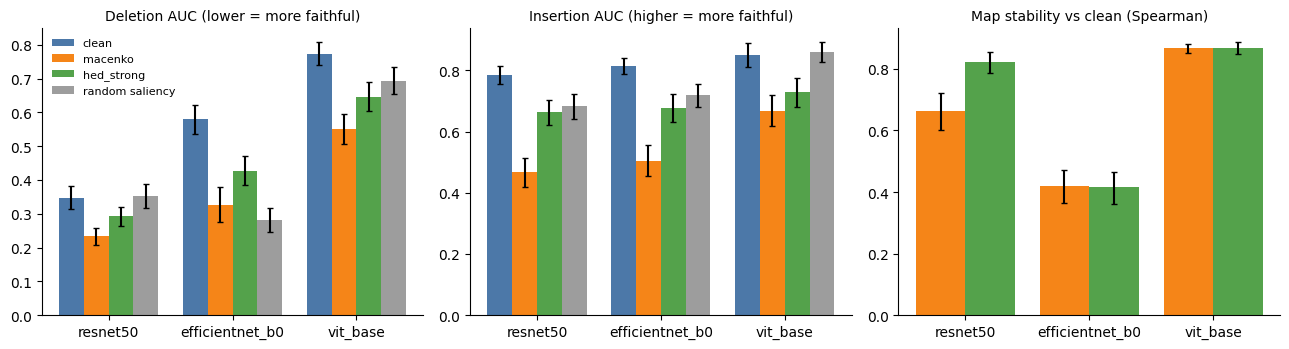

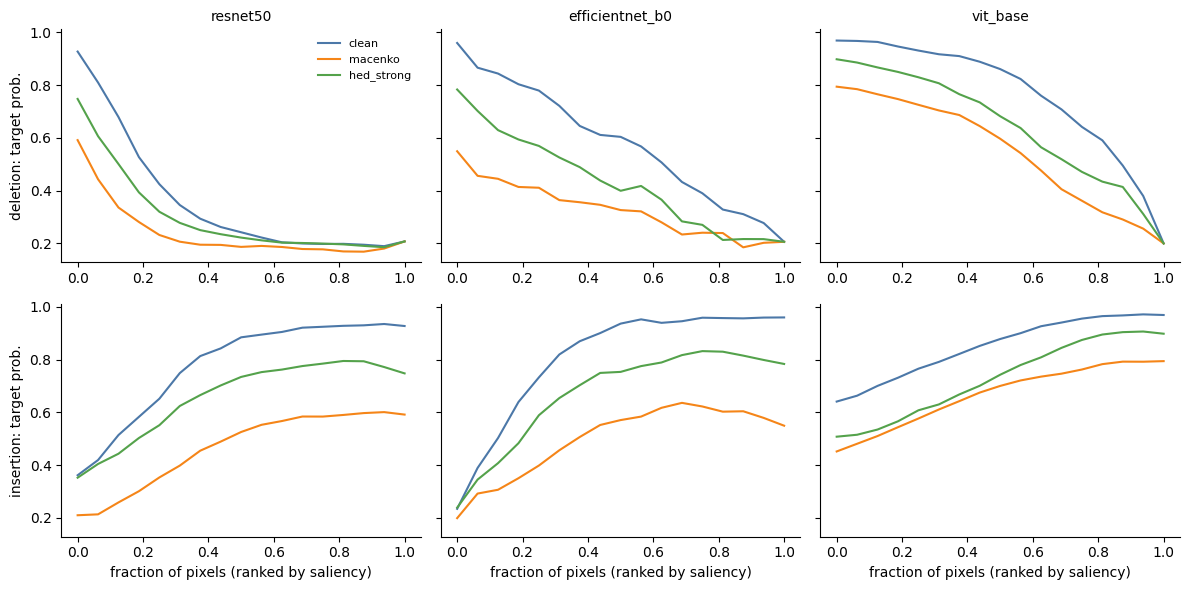

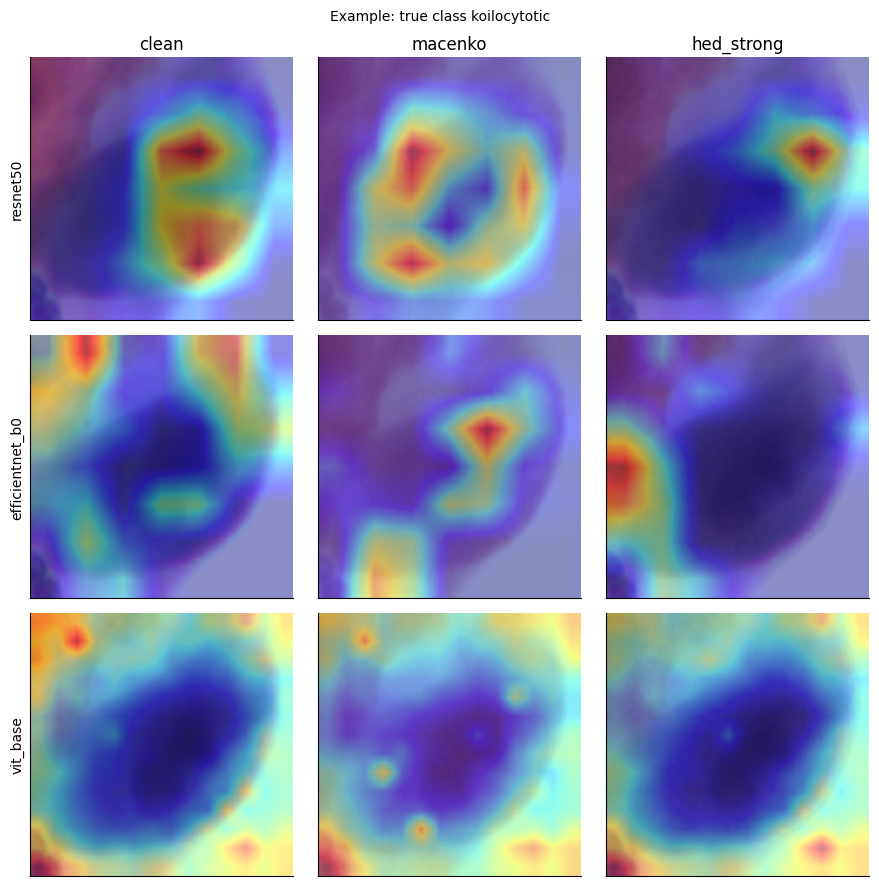

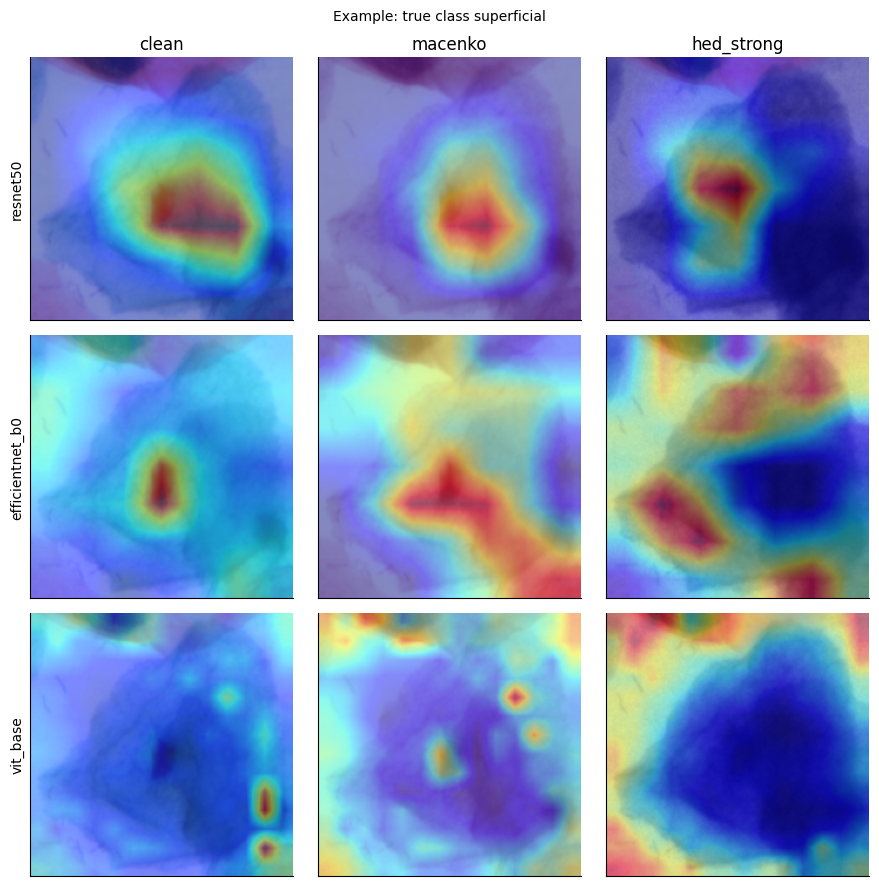


Saved: xai_per_image.csv, xai_summary.csv, figures/xai_*.png/.pdf
Re-run F5 to add them to figures_and_tables.zip.


In [22]:
# XAI CELL: explanation faithfulness under stain shift (clean vs Macenko vs HED-strong)
# Run AFTER the 5-seed training and F0 to F5 are done, in the SAME kernel (needs the GPU and these names):
#   df, classes, MODELS, DEVICE, IMG, eval_tf, group_split, load_ckpt, materialize, SHIFTS
# SHIFTS["hed_strong"] must be the v2 version from your cell 12 (scale 0.30). Do not re-run cell 10.
# Uses the seed-0 GROUP-split checkpoints: ckpt_group_{model}_s0.pt. Runtime ~5 to 10 min on a T4.
# Outputs: figures/xai_*.png/.pdf, xai_per_image.csv, xai_summary.csv
#
# Design
#   Methods : Grad-CAM (resnet50: layer4[-1], efficientnet_b0: bn2), attention rollout (ViT-B/16, CLS row).
#   Target  : the class the model predicts on the CLEAN image, explained under every condition (fixed target,
#             so changes in the map come from the stain shift and not from a changed label).
#   Faithfulness: deletion AUC (lower = better) and insertion AUC (higher = better) of the target-class probability.
#             Deletion sets pixels to 0 in normalised space (ImageNet mean grey); insertion starts from a blurred copy.
#   Stability: Spearman rank correlation (14x14 maps) and top-20% IoU between the clean map and the shifted map.
#   Baseline: random saliency on clean images, so you know what "no information" looks like for each model.
#   Compare AUCs WITHIN a model across conditions. Grad-CAM and rollout are different methods, so absolute
#   numbers across backbones are not a fair ranking.

import os, time
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import matplotlib
import matplotlib.pyplot as plt

assert "macenko" in SHIFTS and "hed_strong" in SHIFTS, "run the shift cells first (SHIFTS missing)"

SPLIT = "group"
CONDS = ["clean", "macenko", "hed_strong"]
N_PER_CLASS, STEPS, BSX = 24, 16, 16
os.makedirs("figures", exist_ok=True)
_trapz = getattr(np, "trapezoid", None) or np.trapz
MEAN = np.array([0.485, 0.456, 0.406]); STD = np.array([0.229, 0.224, 0.225])

# ---- fixed, class-stratified subset of the group-split test set --------------------------------------------------
_, _, te = group_split(df, 0)
sub = (te.groupby("y", group_keys=False).apply(lambda g: g.sample(min(N_PER_CLASS, len(g)), random_state=0))
         .sort_values("y").reset_index(drop=True))
print(f"XAI subset: {len(sub)} images", sub["y"].value_counts().sort_index().to_dict())
QI = [int(sub.index[sub['y'] == c][0]) for c in (1, 4) if (sub['y'] == c).any()]     # images for the example figure

XS = {}
for c in CONDS:
    XS[c], _ = materialize(sub, SHIFTS[c])
Y = torch.tensor(sub["y"].values)


# ---- saliency methods --------------------------------------------------------------------------------------------
def norm01(m):
    flat = m.flatten(1)
    lo, hi = flat.min(1, keepdim=True).values, flat.max(1, keepdim=True).values
    return ((flat - lo) / (hi - lo + 1e-8)).view_as(m)


def gradcam(model, name, x, cls):
    layer = model.layer4[-1] if name == "resnet50" else model.bn2
    store = {}
    h = layer.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    with torch.enable_grad():
        out = model(x)
        a = store["a"]
        g = torch.autograd.grad(out.gather(1, cls[:, None]).sum(), a)[0]
    h.remove()
    w = g.mean((2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True)).detach()
    cam = F.interpolate(cam, size=(IMG, IMG), mode="bilinear", align_corners=False)[:, 0]
    return norm01(cam)


def vit_rollout(model, x, cls=None):
    for b in model.blocks:
        b.attn.fused_attn = False                       # fused kernels do not expose the attention matrix
    atts = []
    hs = [b.attn.attn_drop.register_forward_hook(lambda m, i, o: atts.append(o.detach())) for b in model.blocks]
    with torch.no_grad():
        model(x)
    for h in hs:
        h.remove()
    assert len(atts) == len(model.blocks) and atts[0].dim() == 4, "attention hooks failed (timm version?)"
    A = torch.stack(atts).mean(2)                       # layers, B, N, N  (mean over heads)
    N = A.shape[-1]
    A = A + torch.eye(N, device=A.device)
    A = A / A.sum(-1, keepdim=True)
    R = A[0]
    for l in range(1, A.shape[0]):
        R = A[l] @ R
    m = R[:, 0, 1:]                                     # CLS row, drop the CLS column (1 class token)
    g = int(round(m.shape[1] ** 0.5))
    m = F.interpolate(m.reshape(-1, 1, g, g), size=(IMG, IMG), mode="bilinear", align_corners=False)[:, 0]
    return norm01(m)


def saliency(model, name, x, cls):
    return vit_rollout(model, x) if name.startswith("vit") else gradcam(model, name, x, cls)


# ---- faithfulness and stability ----------------------------------------------------------------------------------
@torch.no_grad()
def del_ins(model, x, cls, sal):
    B, P = x.shape[0], IMG * IMG
    base = TF.gaussian_blur(x, [51, 51], [10.0, 10.0])
    order = sal.reshape(B, -1).argsort(1, descending=True)
    rank = torch.empty_like(order)
    rank.scatter_(1, order, torch.arange(P, device=x.device).expand(B, P))
    fr = np.linspace(0, 1, STEPS + 1)
    D, I = [], []
    for f in fr:
        m = (rank < int(round(f * P))).float().reshape(B, 1, IMG, IMG)
        D.append(F.softmax(model(x * (1 - m)), 1).gather(1, cls[:, None])[:, 0])
        I.append(F.softmax(model(base * (1 - m) + x * m), 1).gather(1, cls[:, None])[:, 0])
    D = torch.stack(D, 1).cpu().numpy(); I = torch.stack(I, 1).cpu().numpy()
    return _trapz(D, fr, axis=1), _trapz(I, fr, axis=1), D, I


def spearman(a, b):
    ra, rb = a.argsort(1).argsort(1).float(), b.argsort(1).argsort(1).float()
    ra -= ra.mean(1, keepdim=True); rb -= rb.mean(1, keepdim=True)
    return (ra * rb).sum(1) / (ra.norm(dim=1) * rb.norm(dim=1) + 1e-8)


def stability(s_clean, s_shift):
    p = lambda s: F.adaptive_avg_pool2d(s[:, None], 14).flatten(1)
    rho = spearman(p(s_clean), p(s_shift))
    q = lambda s: s.flatten(1) >= torch.quantile(s.flatten(1), 0.8, dim=1, keepdim=True)
    a, b = q(s_clean), q(s_shift)
    iou = (a & b).float().sum(1) / ((a | b).float().sum(1) + 1e-8)
    return rho.cpu().numpy(), iou.cpu().numpy()


# ---- main loop ---------------------------------------------------------------------------------------------------
rows, CURVES, QUAL = [], {}, {}
rng_t = torch.Generator(device="cpu").manual_seed(0)
for name in MODELS:
    t0 = time.time()
    model = load_ckpt(name, SPLIT)
    with torch.no_grad():
        logit = {c: torch.cat([model(XS[c][i:i + 64].to(DEVICE).float()).cpu() for i in range(0, len(sub), 64)])
                 for c in CONDS}
    pred = {c: logit[c].argmax(1) for c in CONDS}
    tgt = pred["clean"]                                   # fixed target: clean prediction
    acc = {c: float((pred[c] == Y).float().mean()) for c in CONDS}
    print(f"[{name}] subset accuracy:", {c: round(v, 3) for c, v in acc.items()})

    sal_clean = []
    for c in CONDS:
        for i in range(0, len(sub), BSX):
            x = XS[c][i:i + BSX].to(DEVICE).float()
            cls = tgt[i:i + BSX].to(DEVICE)
            s = saliency(model, name, x, cls)
            dA, iA, Dc, Ic = del_ins(model, x, cls, s)
            if c == "clean":
                sal_clean.append(s.cpu())
                rho = np.ones(len(cls)); iou = np.ones(len(cls))
            else:
                rho, iou = stability(torch.cat(sal_clean)[i:i + BSX].to(DEVICE), s)
            pr = F.softmax(torch.from_numpy(logit[c][i:i + BSX].numpy()), 1).gather(1, tgt[i:i + BSX, None])[:, 0].numpy()
            for j in range(len(cls)):
                rows.append(dict(model=name, cond=c, method="saliency", idx=i + j, y=int(Y[i + j]),
                                 pred_cond=int(pred[c][i + j]), pred_same=bool(pred[c][i + j] == tgt[i + j]),
                                 p_target=float(pr[j]), del_auc=dA[j], ins_auc=iA[j], rho=rho[j], iou=iou[j]))
            CURVES.setdefault((name, c), []).append((Dc, Ic))
            for qi in QI:
                if i <= qi < i + BSX:
                    QUAL[(name, c, qi)] = s[qi - i].cpu().numpy()
            if c == "clean":                              # random-saliency baseline (clean only)
                r = torch.rand(len(cls), IMG, IMG, generator=rng_t).to(DEVICE)
                dR, iR, _, _ = del_ins(model, x, cls, r)
                for j in range(len(cls)):
                    rows.append(dict(model=name, cond="clean", method="random", idx=i + j, y=int(Y[i + j]),
                                     pred_cond=int(pred["clean"][i + j]), pred_same=True, p_target=np.nan,
                                     del_auc=dR[j], ins_auc=iR[j], rho=np.nan, iou=np.nan))
        if c != "clean":
            same = np.mean([r["pred_same"] for r in rows if r["model"] == name and r["cond"] == c and r["method"] == "saliency"])
            print(f"   {c:10s}: prediction unchanged on {same:.1%} of images")
    del model; torch.cuda.empty_cache()
    print(f"   done in {time.time() - t0:.0f}s")

R = pd.DataFrame(rows)
R.to_csv("xai_per_image.csv", index=False)


# ---- summary with bootstrap CIs ----------------------------------------------------------------------------------
def boot(v, n=2000, seed=0):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    m = np.random.default_rng(seed).choice(v, (n, len(v))).mean(1)
    return v.mean(), *np.percentile(m, [2.5, 97.5])


S = []
for (name, c, meth), g in R.groupby(["model", "cond", "method"]):
    row = dict(model=name, cond=c, method=meth, n=len(g), frac_pred_same=g["pred_same"].mean())
    for k in ["del_auc", "ins_auc", "rho", "iou"]:
        m, lo, hi = boot(g[k]); row.update({k: m, k + "_lo": lo, k + "_hi": hi})
    clean = R[(R.model == name) & (R.cond == "clean") & (R.method == "saliency")].set_index("idx")
    if meth == "saliency" and c != "clean":
        g2 = g.set_index("idx")
        for k in ["del_auc", "ins_auc"]:
            m, lo, hi = boot((g2[k] - clean[k]).values); row.update({k + "_delta": m, k + "_dlo": lo, k + "_dhi": hi})
    S.append(row)
S = pd.DataFrame(S).sort_values(["model", "method", "cond"])
S.to_csv("xai_summary.csv", index=False)
pd.set_option("display.width", 220)
print(S[["model", "cond", "method", "del_auc", "ins_auc", "rho", "iou", "frac_pred_same"]].round(3).to_string(index=False))
print("\nPaired change vs clean (95% CI over images; a CI that excludes 0 means the faithfulness changed)")
print(S[S.cond != "clean"][["model", "cond", "del_auc_delta", "del_auc_dlo", "del_auc_dhi",
                            "ins_auc_delta", "ins_auc_dlo", "ins_auc_dhi"]].round(3).to_string(index=False))

# ---- figures -----------------------------------------------------------------------------------------------------
PAL = {"clean": "#4C78A8", "macenko": "#F58518", "hed_strong": "#54A24B", "random": "#9D9D9D"}


def save(fig, stem):
    fig.savefig(f"figures/{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"figures/{stem}.pdf", bbox_inches="tight")
    plt.show()


# F-XAI-1: grouped bars
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (k, title) in zip(ax, [("del_auc", "Deletion AUC (lower = more faithful)"),
                              ("ins_auc", "Insertion AUC (higher = more faithful)"),
                              ("rho", "Map stability vs clean (Spearman)")]):
    conds = ["clean", "macenko", "hed_strong"] if k != "rho" else ["macenko", "hed_strong"]
    if k != "rho":
        conds = conds + ["random"]
    w = 0.8 / len(conds)
    for ci, c in enumerate(conds):
        meth = "random" if c == "random" else "saliency"
        cc = "clean" if c == "random" else c
        d = S[(S.cond == cc) & (S.method == meth)].set_index("model").reindex(MODELS)
        x = np.arange(len(MODELS)) + (ci - (len(conds) - 1) / 2) * w
        ax_err = np.vstack([d[k] - d[k + "_lo"], d[k + "_hi"] - d[k]])
        a.bar(x, d[k], w, yerr=ax_err, color=PAL[c], label=("random saliency" if c == "random" else c), capsize=2)
    a.set_xticks(range(len(MODELS))); a.set_xticklabels([m.replace("_patch16_224", "") for m in MODELS])
    a.set_title(title, fontsize=10)
    a.spines[["top", "right"]].set_visible(False)
ax[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); save(fig, "xai_faithfulness_bars")

# F-XAI-2: mean deletion / insertion curves
fig, ax = plt.subplots(2, len(MODELS), figsize=(4 * len(MODELS), 6), sharey=True)
fr = np.linspace(0, 1, STEPS + 1)
for j, name in enumerate(MODELS):
    for c in CONDS:
        D = np.concatenate([d for d, _ in CURVES[(name, c)]]).mean(0)
        I = np.concatenate([i for _, i in CURVES[(name, c)]]).mean(0)
        ax[0, j].plot(fr, D, color=PAL[c], label=c); ax[1, j].plot(fr, I, color=PAL[c], label=c)
    ax[0, j].set_title(name.replace("_patch16_224", ""), fontsize=10)
    ax[1, j].set_xlabel("fraction of pixels (ranked by saliency)")
ax[0, 0].set_ylabel("deletion: target prob."); ax[1, 0].set_ylabel("insertion: target prob.")
ax[0, 0].legend(frameon=False, fontsize=8)
for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); save(fig, "xai_curves")

# F-XAI-3: example overlays (rows = model, columns = condition), one figure per example image
for qi in QI:
    fig, ax = plt.subplots(len(MODELS), len(CONDS), figsize=(3 * len(CONDS), 3 * len(MODELS)))
    for r_, name in enumerate(MODELS):
        for c_, c in enumerate(CONDS):
            img = np.clip(XS[c][qi].float().numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1)
            ax[r_, c_].imshow(img)
            ax[r_, c_].imshow(QUAL[(name, c, qi)], cmap="jet", alpha=0.45, vmin=0, vmax=1)
            ax[r_, c_].set_xticks([]); ax[r_, c_].set_yticks([])
            if r_ == 0: ax[r_, c_].set_title(c)
            if c_ == 0: ax[r_, c_].set_ylabel(name.replace("_patch16_224", ""))
    fig.suptitle(f"Example: true class {classes[int(Y[qi])]}", fontsize=10)
    fig.tight_layout(); save(fig, f"xai_examples_{classes[int(Y[qi])]}")

print("\nSaved: xai_per_image.csv, xai_summary.csv, figures/xai_*.png/.pdf")
print("Re-run F5 to add them to figures_and_tables.zip.")

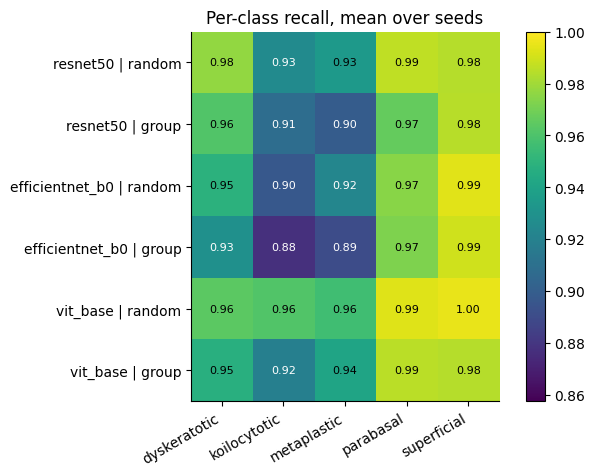


[2] top confusions (seed 0)
 split                model         true    predicted  count  pct_of_true_class
random             resnet50 koilocytotic  metaplastic      7                5.6
random             resnet50 koilocytotic  superficial      4                3.2
random             resnet50 koilocytotic dyskeratotic      4                3.2
random             resnet50  superficial koilocytotic      2                1.6
random             resnet50  metaplastic koilocytotic      2                1.7
random      efficientnet_b0 dyskeratotic koilocytotic      9                7.4
random      efficientnet_b0 koilocytotic  metaplastic      5                4.0
random      efficientnet_b0  metaplastic koilocytotic      3                2.5
random      efficientnet_b0 koilocytotic  superficial      3                2.4
random      efficientnet_b0 koilocytotic dyskeratotic      3                2.4
random vit_base_patch16_224  metaplastic koilocytotic      3                2.5
random vit_

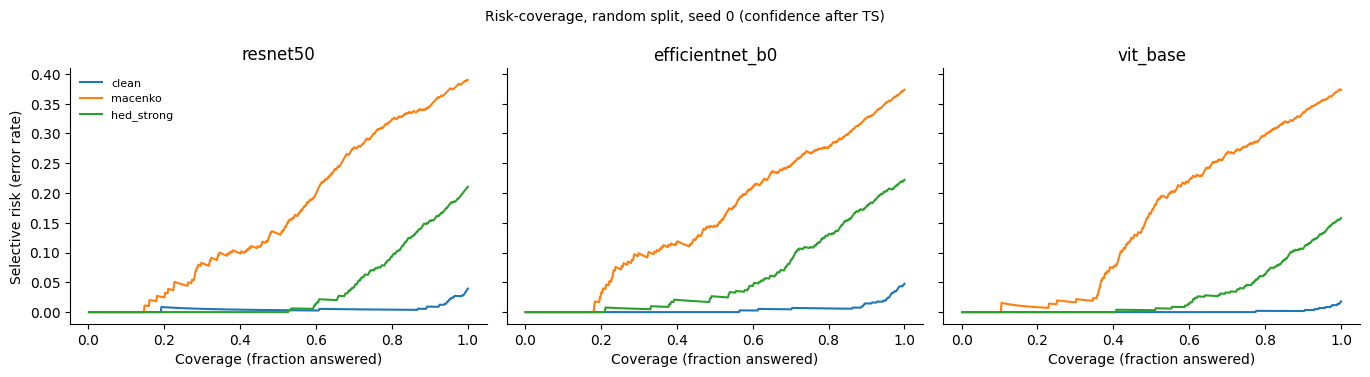

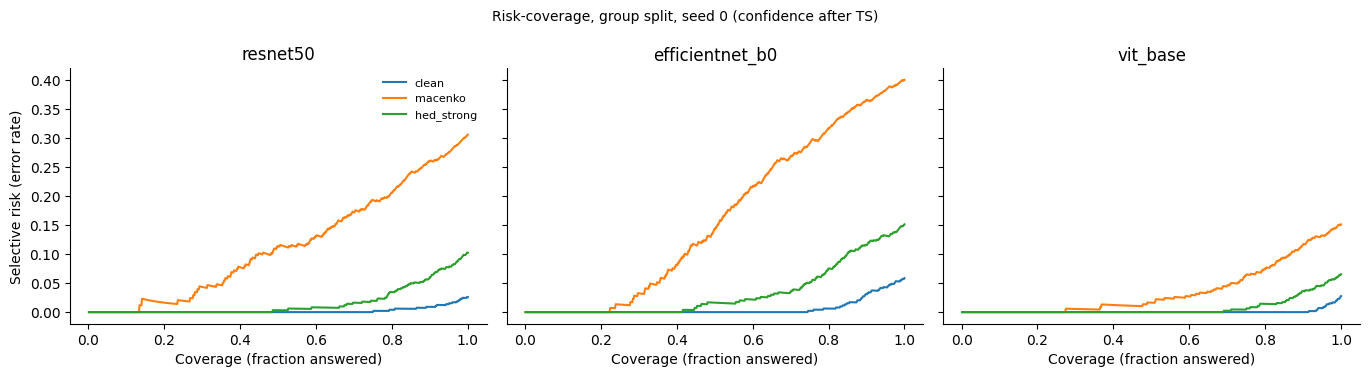


[3] AURC (lower is better)
 split                model      shift  error_at_full_coverage   AURC  cov_at_risk_le_1pct
random             resnet50      clean                  0.0395 0.0053               0.9227
random             resnet50    macenko                  0.3898 0.1679               0.1464
random             resnet50 hed_strong                  0.2105 0.0404               0.5938
random      efficientnet_b0      clean                  0.0477 0.0045               0.8898
random      efficientnet_b0    macenko                  0.3734 0.1629               0.1826
random      efficientnet_b0 hed_strong                  0.2220 0.0595               0.3783
random vit_base_patch16_224      clean                  0.0181 0.0010               0.9720
random vit_base_patch16_224    macenko                  0.3734 0.1579               0.2286
random vit_base_patch16_224 hed_strong                  0.1579 0.0305               0.5872
 group             resnet50      clean                  0.0260

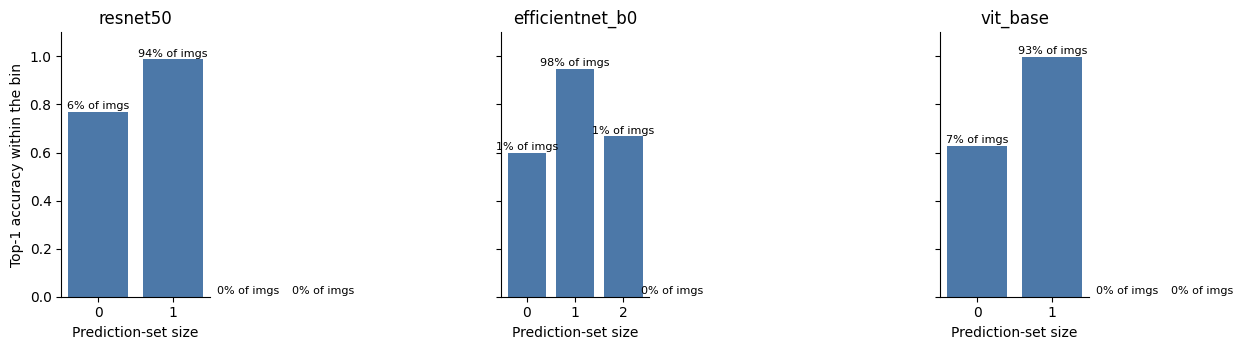

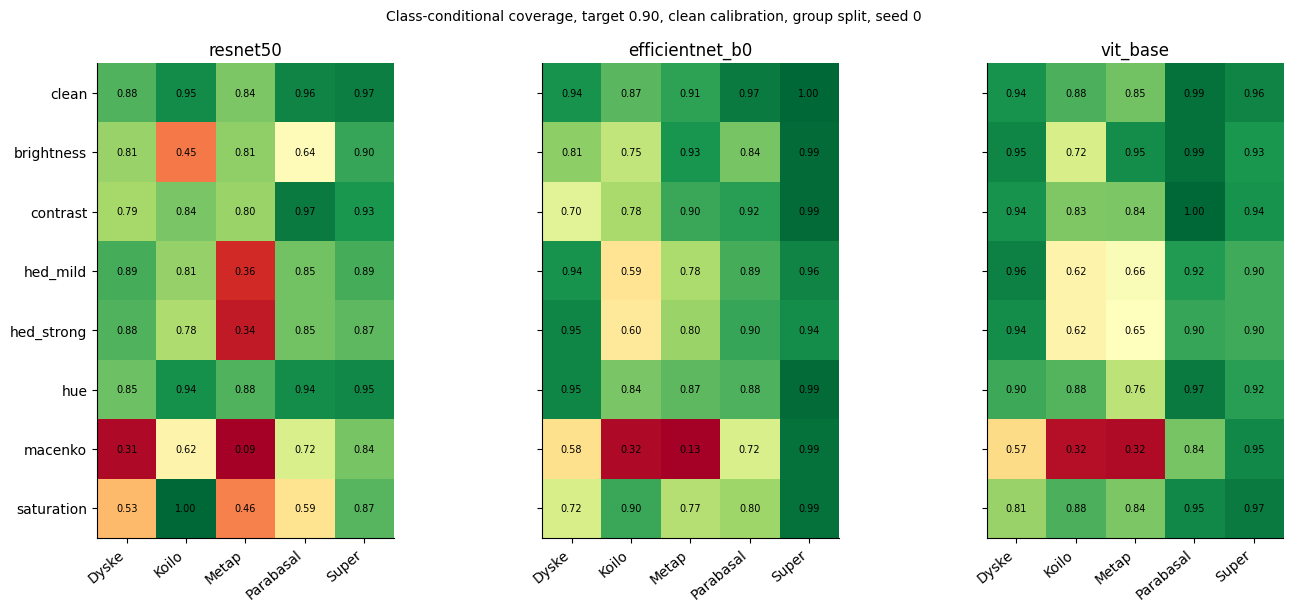

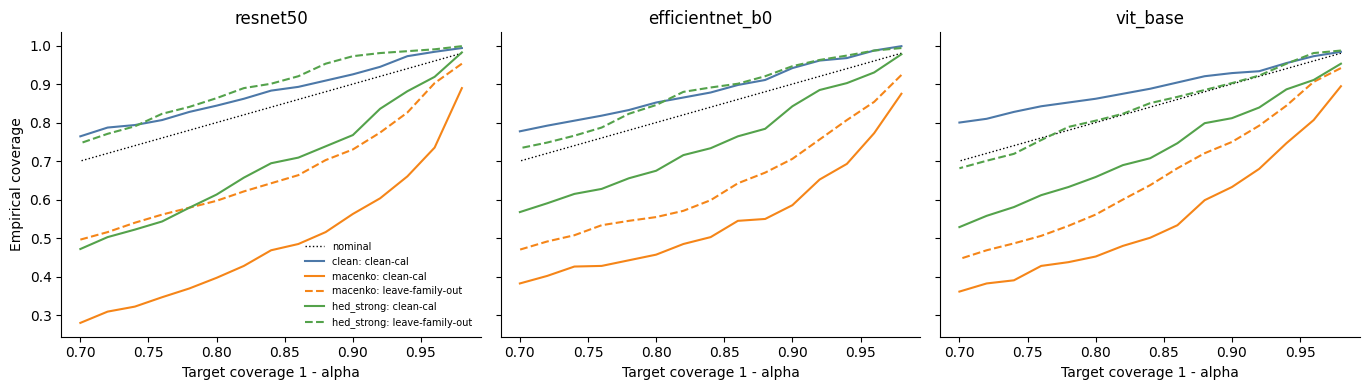

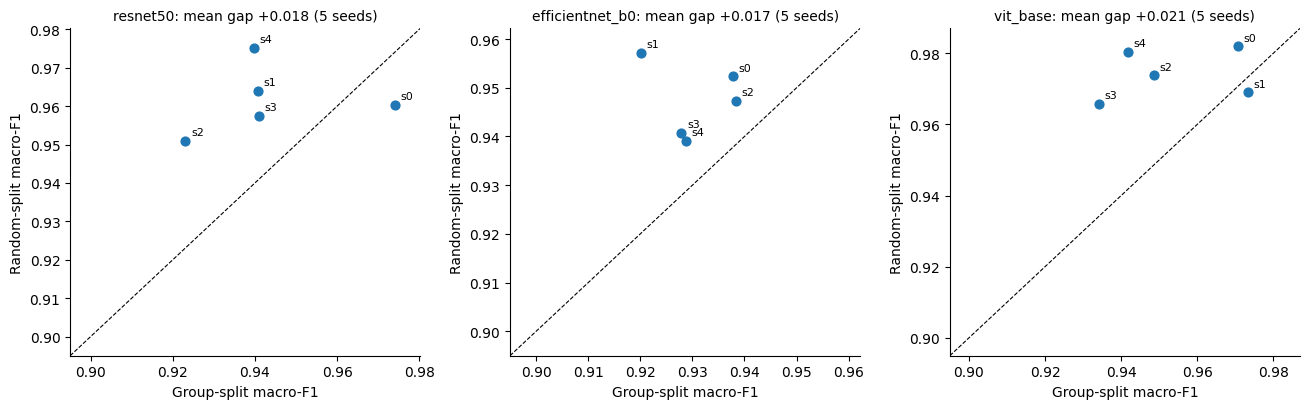

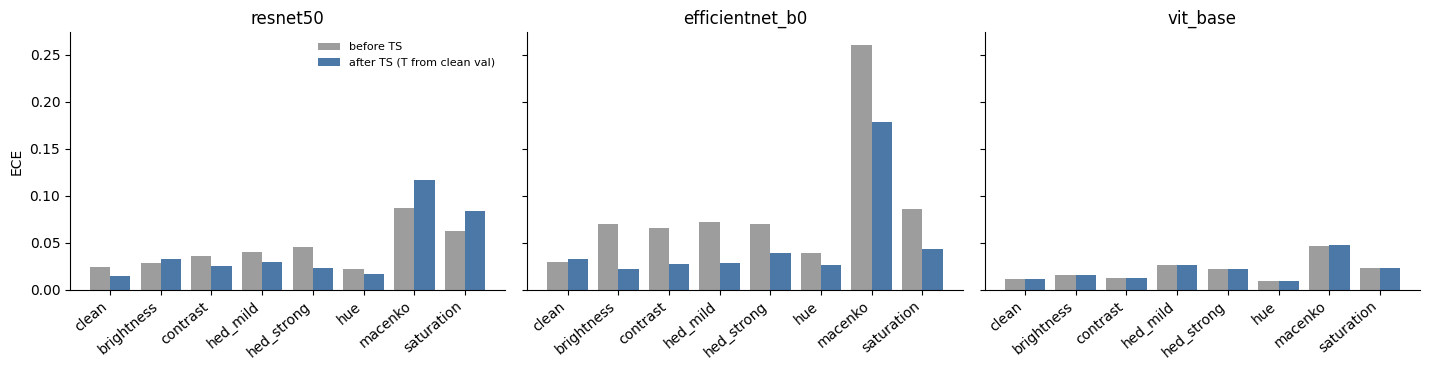


[9] ECE under shift
               model      shift  ece_before  ece_after      T
            resnet50      clean      0.0243     0.0141 0.8710
            resnet50 brightness      0.0282     0.0328 0.8710
            resnet50   contrast      0.0361     0.0254 0.8710
            resnet50   hed_mild      0.0407     0.0298 0.8710
            resnet50 hed_strong      0.0451     0.0228 0.8710
            resnet50        hue      0.0220     0.0167 0.8710
            resnet50    macenko      0.0870     0.1165 0.8710
            resnet50 saturation      0.0623     0.0836 0.8710
     efficientnet_b0      clean      0.0291     0.0326 1.6294
     efficientnet_b0 brightness      0.0697     0.0221 1.6294
     efficientnet_b0   contrast      0.0662     0.0274 1.6294
     efficientnet_b0   hed_mild      0.0723     0.0286 1.6294
     efficientnet_b0 hed_strong      0.0704     0.0393 1.6294
     efficientnet_b0        hue      0.0391     0.0267 1.6294
     efficientnet_b0    macenko      0.2611     0

In [23]:
# F6: ten extra outputs for the paper. Run AFTER F0 to F5, same kernel (or a fresh one: it needs only the files below).
#
#   Inputs : baseline_results.csv (5 seeds), shift_logits_v2.pt (seed 0, fixed HED v2 shifts)
#   Globals: classes, MODELS (from your notebook). DEVICE and timm are used only for item 10.
#   Outputs: figures/f6_*.png/.pdf and figures/f6_*.csv.  Re-run F5 afterwards to zip them.
#   Items 1 to 6, 8, 9, 10 need NO GPU and take about a minute. Item 7 (severity sweep) is in the next cell, F6b.
#
#   1 per-class recall heatmap          6 coverage vs alpha, clean-cal vs leave-one-family-out
#   2 top confused class pairs          7 HED severity sweep (cell F6b, GPU)
#   3 risk-coverage (selective pred.)   8 seed-wise paired scatter, random vs group
#   4 set size vs accuracy              9 ECE before/after temperature scaling under each shift
#   5 class-conditional coverage       10 cost table (params, train time, speed, F1, ECE)
#
# NOTE: items 2 to 6 and 9 use seed 0 only (that is what shift_logits_v2.pt holds). Say so in the captions.

import os, math, time
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
ALPHA = 0.1
FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}
SHOW = ["clean", "macenko", "hed_strong"]
# training seconds per run, averaged from your seed 1 to 3 log (T4/P100-class GPU). Edit if your log differs.
TRAIN_SEC = {"resnet50": 360, "efficientnet_b0": 176, "vit_base_patch16_224": 1160}
SHORT = lambda n: n.replace("_patch16_224", "")


def save6(fig, stem):
    fig.savefig(f"{OUT}/{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/{stem}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)


# ---- numpy helpers ------------------------------------------------------------------------------------------------
def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def fit_T(logits, y):
    def nll(lt):
        p = softmax(logits / math.exp(lt))
        return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
    return math.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x)


def ece_np(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1)
    acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1)
    e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(conf[m].mean() - acc[m].mean())
    return e


def lac_sets(p_cal, y_cal, p_test, alpha):
    """Split conformal (LAC): include class k when 1 - p_k <= qhat."""
    n = len(y_cal)
    s = 1 - p_cal[np.arange(n), y_cal]
    level = min(1.0, math.ceil((n + 1) * (1 - alpha)) / n)
    qhat = np.quantile(s, level, method="higher")
    return (1 - p_test) <= qhat


def covered(sets, y):
    return sets[np.arange(len(y)), y]


def lofo_pool(VL, split, name, yv, sh, shifts):
    pool = [s for s in shifts if FAMILY.get(s, s) != FAMILY.get(sh, sh)]
    pl = np.concatenate([VL[(split, name, s)] for s in pool])
    py = np.tile(yv, len(pool))
    return pl, py


# ---- the ten outputs ----------------------------------------------------------------------------------------------
def run_all(VL, TL, YV, YT, res, classes, MODELS, split_main="group"):
    K = len(classes)
    CN = [c[:5].title() if len(c) > 9 else c.title() for c in classes]
    shifts = ["clean"] + sorted({k[2] for k in VL if k[2] != "clean"})
    splits = ["random", "group"]
    res = res[res["split"].isin(splits)]
    raw = res[~res["calibrated"]]
    T0 = {(sp, n): fit_T(VL[(sp, n, "clean")], YV[sp]) for sp in splits for n in MODELS}

    # ---- 1. per-class recall heatmap (mean over seeds) ------------------------------------------------------------
    rc = [c for c in raw.columns if c.startswith("recall_")]
    keys = [(m, sp) for m in MODELS for sp in splits]
    M = np.array([[raw[(raw.model == m) & (raw.split == sp)][c].mean() for c in rc] for m, sp in keys])
    pd.DataFrame(M, index=[f"{SHORT(m)} | {sp}" for m, sp in keys], columns=[c[7:] for c in rc]) \
        .round(4).to_csv(f"{OUT}/f6_per_class_recall.csv")
    fig, a = plt.subplots(figsize=(7, 0.55 * len(keys) + 1.5))
    im = a.imshow(M, cmap="viridis", vmin=max(0.0, M.min() - 0.02), vmax=1.0)
    a.set_xticks(range(len(rc))); a.set_xticklabels([c[7:] for c in rc], rotation=30, ha="right")
    a.set_yticks(range(len(keys))); a.set_yticklabels([f"{SHORT(m)} | {sp}" for m, sp in keys])
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            a.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] < 0.93 else "black", fontsize=8)
    fig.colorbar(im, ax=a, fraction=0.04); a.set_title("Per-class recall, mean over seeds")
    save6(fig, "f6_1_per_class_recall")

    # ---- 2. top confused class pairs (seed 0, clean test) ---------------------------------------------------------
    rows = []
    for sp in splits:
        for n in MODELS:
            y, p = YT[sp], TL[(sp, n, "clean")].argmax(1)
            cm = np.zeros((K, K), int)
            np.add.at(cm, (y, p), 1)
            off = [(cm[i, j], i, j) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0]
            for cnt, i, j in sorted(off, reverse=True)[:5]:
                rows.append(dict(split=sp, model=n, true=classes[i], predicted=classes[j], count=int(cnt),
                                 pct_of_true_class=round(100 * cnt / cm[i].sum(), 1)))
    C2 = pd.DataFrame(rows); C2.to_csv(f"{OUT}/f6_2_top_confusions.csv", index=False)
    print("\n[2] top confusions (seed 0)"); print(C2.to_string(index=False))

    # ---- 3. risk-coverage curves + AURC ---------------------------------------------------------------------------
    aurc_rows = []
    for sp in splits:
        fig, ax = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 3.8), sharey=True)
        for j, n in enumerate(MODELS):
            for sh in SHOW:
                if (sp, n, sh) not in TL: continue
                p = softmax(TL[(sp, n, sh)] / T0[(sp, n)])
                conf, err = p.max(1), (p.argmax(1) != YT[sp]).astype(float)
                o = np.argsort(-conf)
                risk = np.cumsum(err[o]) / np.arange(1, len(o) + 1)
                cov = np.arange(1, len(o) + 1) / len(o)
                ax[j].plot(cov, risk, label=sh)
                aurc_rows.append(dict(split=sp, model=n, shift=sh, error_at_full_coverage=risk[-1], AURC=risk.mean(),
                                      cov_at_risk_le_1pct=cov[risk <= 0.01].max() if (risk <= 0.01).any() else 0.0))
            ax[j].set_title(SHORT(n)); ax[j].set_xlabel("Coverage (fraction answered)")
            ax[j].spines[["top", "right"]].set_visible(False)
        ax[0].set_ylabel("Selective risk (error rate)"); ax[0].legend(frameon=False, fontsize=8)
        fig.suptitle(f"Risk-coverage, {sp} split, seed 0 (confidence after TS)", fontsize=10)
        fig.tight_layout(); save6(fig, f"f6_3_risk_coverage_{sp}")
    A3 = pd.DataFrame(aurc_rows).round(4); A3.to_csv(f"{OUT}/f6_3_aurc.csv", index=False)
    print("\n[3] AURC (lower is better)"); print(A3.to_string(index=False))

    # ---- 4. set size vs accuracy ----------------------------------------------------------------------------------
    rows = []
    sp = split_main
    for n in MODELS:
        pc = softmax(VL[(sp, n, "clean")] / T0[(sp, n)])
        for sh in SHOW:
            pt = softmax(TL[(sp, n, sh)] / T0[(sp, n)])
            S = lac_sets(pc, YV[sp], pt, ALPHA)
            sz = S.sum(1).clip(max=3)
            ok = (pt.argmax(1) == YT[sp])
            for k in range(4):
                m = sz == k
                rows.append(dict(model=n, shift=sh, set_size="3+" if k == 3 else str(k), frac=m.mean(),
                                 top1_acc=ok[m].mean() if m.any() else np.nan,
                                 coverage=covered(S, YT[sp])[m].mean() if m.any() else np.nan, n=int(m.sum())))
    C4 = pd.DataFrame(rows).round(4); C4.to_csv(f"{OUT}/f6_4_setsize_vs_accuracy.csv", index=False)
    print(f"\n[4] set size vs accuracy ({sp}, alpha={ALPHA}, clean calibration)"); print(C4.to_string(index=False))
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 3.6), sharey=True)
    for j, n in enumerate(MODELS):
        d = C4[(C4.model == n) & (C4["shift"] == "clean")]
        a = ax[j]
        a.bar(d["set_size"], d["top1_acc"], color="#4C78A8")
        for x, (acc, fr) in enumerate(zip(d["top1_acc"], d["frac"])):
            a.text(x, (0 if np.isnan(acc) else acc) + 0.01, f"{fr:.0%} of imgs", ha="center", fontsize=8)
        a.set_title(SHORT(n)); a.set_xlabel("Prediction-set size"); a.set_ylim(0, 1.1)
        a.spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("Top-1 accuracy within the bin")
    fig.tight_layout(); save6(fig, "f6_4_setsize_vs_accuracy")

    # ---- 5. class-conditional coverage ----------------------------------------------------------------------------
    rows = []
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.8 * len(MODELS), 0.5 * len(shifts) + 2.2))
    for j, n in enumerate(MODELS):
        pc = softmax(VL[(sp, n, "clean")] / T0[(sp, n)])
        Mc = np.zeros((len(shifts), K))
        for i, sh in enumerate(shifts):
            pt = softmax(TL[(sp, n, sh)] / T0[(sp, n)])
            cv = covered(lac_sets(pc, YV[sp], pt, ALPHA), YT[sp])
            for c in range(K):
                Mc[i, c] = cv[YT[sp] == c].mean()
                rows.append(dict(model=n, shift=sh, cls=classes[c], coverage=Mc[i, c]))
        im = ax[j].imshow(Mc, cmap="RdYlGn", vmin=0.3, vmax=1.0)
        ax[j].set_xticks(range(K)); ax[j].set_xticklabels(CN, rotation=40, ha="right")
        ax[j].set_yticks(range(len(shifts))); ax[j].set_yticklabels(shifts if j == 0 else [])
        for i in range(len(shifts)):
            for c in range(K):
                ax[j].text(c, i, f"{Mc[i, c]:.2f}", ha="center", va="center", fontsize=7)
        ax[j].set_title(SHORT(n))
    fig.suptitle(f"Class-conditional coverage, target {1 - ALPHA:.2f}, clean calibration, {sp} split, seed 0", fontsize=10)
    fig.tight_layout(); save6(fig, "f6_5_class_conditional_coverage")
    pd.DataFrame(rows).round(4).to_csv(f"{OUT}/f6_5_class_conditional_coverage.csv", index=False)

    # ---- 6. coverage vs alpha -------------------------------------------------------------------------------------
    alphas = np.round(np.arange(0.02, 0.31, 0.02), 2)
    rows = []
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 4), sharey=True)
    cols = {"clean": "#4C78A8", "macenko": "#F58518", "hed_strong": "#54A24B"}
    for j, n in enumerate(MODELS):
        pc = softmax(VL[(sp, n, "clean")] / T0[(sp, n)])
        ax[j].plot(1 - alphas, 1 - alphas, "k:", lw=1, label="nominal")
        for sh in SHOW:
            pt_c = softmax(TL[(sp, n, sh)] / T0[(sp, n)])
            pl, py = lofo_pool(VL, sp, n, YV[sp], sh, shifts)
            Tp = fit_T(pl, py)
            pp = softmax(pl / Tp); pt_p = softmax(TL[(sp, n, sh)] / Tp)
            cc = [covered(lac_sets(pc, YV[sp], pt_c, a), YT[sp]).mean() for a in alphas]
            cl = [covered(lac_sets(pp, py, pt_p, a), YT[sp]).mean() for a in alphas]
            ax[j].plot(1 - alphas, cc, color=cols[sh], label=f"{sh}: clean-cal")
            if sh != "clean":
                ax[j].plot(1 - alphas, cl, color=cols[sh], ls="--", label=f"{sh}: leave-family-out")
            for a, x1, x2 in zip(alphas, cc, cl):
                rows.append(dict(model=n, shift=sh, alpha=a, cov_clean=x1, cov_lofo=x2))
        ax[j].set_title(SHORT(n)); ax[j].set_xlabel("Target coverage 1 - alpha")
        ax[j].spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("Empirical coverage"); ax[0].legend(frameon=False, fontsize=7)
    fig.tight_layout(); save6(fig, "f6_6_coverage_vs_alpha")
    pd.DataFrame(rows).round(4).to_csv(f"{OUT}/f6_6_coverage_vs_alpha.csv", index=False)

    # ---- 8. seed-wise paired scatter ------------------------------------------------------------------------------
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.4 * len(MODELS), 4.2))
    rows = []
    for j, n in enumerate(MODELS):
        r = raw[raw.model == n].pivot(index="seed", columns="split", values="macro_f1").dropna()
        ax[j].scatter(r["group"], r["random"], s=40)
        for s_, (g, rd) in r.iterrows():
            ax[j].annotate(f"s{int(s_)}", (g, rd), textcoords="offset points", xytext=(4, 4), fontsize=8)
        lo, hi = min(r.min().min(), 0.9) - 0.005, max(r.max().max(), r.max().max()) + 0.005
        ax[j].plot([lo, hi], [lo, hi], "k--", lw=0.8)
        ax[j].set_xlim(lo, hi); ax[j].set_ylim(lo, hi)
        ax[j].set_xlabel("Group-split macro-F1"); ax[j].set_ylabel("Random-split macro-F1")
        d = (r["random"] - r["group"])
        ax[j].set_title(f"{SHORT(n)}: mean gap {d.mean():+.3f} ({len(r)} seeds)", fontsize=10)
        ax[j].spines[["top", "right"]].set_visible(False)
        rows.append(dict(model=n, n_seeds=len(r), mean_gap=d.mean(), seeds_above_diagonal=int((d > 0).sum())))
    fig.tight_layout(); save6(fig, "f6_8_seedwise_random_vs_group")
    pd.DataFrame(rows).round(4).to_csv(f"{OUT}/f6_8_seedwise_gap.csv", index=False)

    # ---- 9. calibration under shift: ECE before / after TS (T fit on clean val) -----------------------------------
    rows = []
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.8 * len(MODELS), 3.8), sharey=True)
    for j, n in enumerate(MODELS):
        for sh in shifts:
            tl = TL[(sp, n, sh)]
            rows.append(dict(model=n, shift=sh, ece_before=ece_np(softmax(tl), YT[sp]),
                             ece_after=ece_np(softmax(tl / T0[(sp, n)]), YT[sp]), T=T0[(sp, n)]))
        d = pd.DataFrame([r for r in rows if r["model"] == n])
        x = np.arange(len(d))
        ax[j].bar(x - 0.2, d["ece_before"], 0.4, label="before TS", color="#9D9D9D")
        ax[j].bar(x + 0.2, d["ece_after"], 0.4, label="after TS (T from clean val)", color="#4C78A8")
        ax[j].set_xticks(x); ax[j].set_xticklabels(d["shift"], rotation=40, ha="right")
        ax[j].set_title(SHORT(n)); ax[j].spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("ECE"); ax[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); save6(fig, "f6_9_ece_under_shift")
    C9 = pd.DataFrame(rows).round(4); C9.to_csv(f"{OUT}/f6_9_ece_under_shift.csv", index=False)
    print("\n[9] ECE under shift"); print(C9.to_string(index=False))

    # ---- 10. cost table -------------------------------------------------------------------------------------------
    rows = []
    try:
        import timm, torch
        dev = DEVICE
    except Exception:
        timm = None
    for n in MODELS:
        g = res[(res.model == n) & (res.split == "group")]
        g0, g1 = g[~g.calibrated], g[g.calibrated]
        row = dict(model=n, group_macro_f1=g0["macro_f1"].mean(), group_ece_before=g0["ece"].mean(),
                   group_ece_after=g1["ece"].mean(), train_sec_per_run=TRAIN_SEC.get(n, np.nan))
        if timm is not None:
            try:
                m = timm.create_model(n, pretrained=False, num_classes=K)
                row["params_M"] = sum(p.numel() for p in m.parameters()) / 1e6
                m = m.to(dev).eval(); x = torch.randn(32, 3, 224, 224, device=dev)
                with torch.no_grad():
                    for _ in range(3): m(x)
                    if dev == "cuda": torch.cuda.synchronize()
                    t0 = time.time(); it = 10 if dev == "cuda" else 3
                    for _ in range(it): m(x)
                    if dev == "cuda": torch.cuda.synchronize()
                row["inference_img_per_s"] = 32 * it / (time.time() - t0)
                del m, x
                if dev == "cuda": torch.cuda.empty_cache()
            except Exception as e:
                print("   cost measurement failed for", n, e)
        rows.append(row)
    C10 = pd.DataFrame(rows).round(4); C10.to_csv(f"{OUT}/f6_10_cost_table.csv", index=False)
    print("\n[10] cost table (speed measured on", globals().get("DEVICE", "n/a"), ")"); print(C10.to_string(index=False))
    print(f"\nSaved F6 outputs to {OUT}/ (f6_*). Item 7 is in cell F6b. Re-run F5 to zip.")


def load_inputs():
    import torch
    try:
        S = torch.load("shift_logits_v2.pt", weights_only=False)
    except TypeError:
        S = torch.load("shift_logits_v2.pt")
    np_ = lambda t: t.detach().cpu().numpy().astype(np.float64)
    VL = {k: np_(v) for k, v in S["VL"].items()}
    TL = {k: np_(v) for k, v in S["TL"].items()}
    YV = {k: v.numpy().astype(int) for k, v in S["YV"].items()}
    YT = {k: v.numpy().astype(int) for k, v in S["YT"].items()}
    return VL, TL, YV, YT, pd.read_csv("baseline_results.csv"), classes, MODELS


if "__SKIP_RUN__" not in globals():
    run_all(*load_inputs())


# %% ===================== CELL F6b: item 7, HED severity sweep (GPU, a few minutes) =====================
# Needs from earlier cells: df, MODELS, DEVICE, group_split, load_ckpt, materialize, collect, hed_jitter_v2 (cell 12),
# classes, and the F6 helpers above (softmax, fit_T, lac_sets, covered, FAMILY, SHORT, save6).
# Calibration is always on CLEAN val (clean-cal) or on the non-HED shifts pooled (pooled-nonHED), as in the paper protocol.
def severity_sweep(strengths=(0.0, 0.05, 0.10, 0.15, 0.20, 0.30, 0.40), split="group"):
    from sklearn.metrics import f1_score
    S = __import__("torch").load("shift_logits_v2.pt", weights_only=False)
    VLs = {k: v.numpy().astype(np.float64) for k, v in S["VL"].items()}
    yv = S["YV"][split].numpy().astype(int)
    shifts = sorted({k[2] for k in VLs})
    tr, va, te = group_split(df, 0)
    rows = []
    for n in MODELS:
        m = load_ckpt(n, split)
        T0 = fit_T(VLs[(split, n, "clean")], yv)
        pc = softmax(VLs[(split, n, "clean")] / T0)
        pool = [s for s in shifts if FAMILY.get(s, s) != "hed" and s != "clean"]   # photometric + macenko
        pl = np.concatenate([VLs[(split, n, s)] for s in pool]); py = np.tile(yv, len(pool))
        Tp = fit_T(pl, py); pp = softmax(pl / Tp)
        for s in strengths:
            fn = (lambda im, r: im) if s == 0 else hed_jitter_v2(s)
            Xt, yt = materialize(te, fn)
            lg = collect(m, Xt).numpy().astype(np.float64); yt = yt.numpy().astype(int)
            f1 = f1_score(yt, lg.argmax(1), average="macro")
            Sc = lac_sets(pc, yv, softmax(lg / T0), ALPHA); Sp = lac_sets(pp, py, softmax(lg / Tp), ALPHA)
            rows.append(dict(model=n, strength=s, macro_f1=f1,
                             cov_clean_cal=covered(Sc, yt).mean(), size_clean_cal=Sc.sum(1).mean(),
                             cov_pooled_nonHED=covered(Sp, yt).mean(), size_pooled_nonHED=Sp.sum(1).mean()))
            del Xt
        del m; __import__("torch").cuda.empty_cache()
        print(n, "done")
    R7 = pd.DataFrame(rows).round(4); R7.to_csv(f"{OUT}/f6_7_severity_sweep.csv", index=False)
    print(R7.to_string(index=False))
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for n in MODELS:
        d = R7[R7.model == n]
        ax[0].plot(d.strength, d.macro_f1, "o-", label=SHORT(n))
        ax[1].plot(d.strength, d.cov_clean_cal, "o-", label=SHORT(n) + " clean-cal")
        ax[1].plot(d.strength, d.cov_pooled_nonHED, "s--", label=SHORT(n) + " pooled non-HED")
        ax[2].plot(d.strength, d.size_clean_cal, "o-", label=SHORT(n))
    ax[1].axhline(1 - ALPHA, color="k", ls=":", lw=1)
    for a, t in zip(ax, ["Macro-F1", "Coverage (target 0.90)", "Mean set size (clean-cal)"]):
        a.set_xlabel("HED concentration jitter strength"); a.set_title(t, fontsize=10)
        a.spines[["top", "right"]].set_visible(False)
    ax[0].legend(frameon=False, fontsize=8); ax[1].legend(frameon=False, fontsize=6)
    fig.tight_layout(); save6(fig, "f6_7_severity_sweep")
    return R7


# run it with:  R7 = severity_sweep()


[1] empty conformal sets as an abstain signal (seed 0, clean calibration)
               model      shift  frac_empty  acc_empty  acc_nonempty  err_after_empty_abstain  err_after_lowconf_abstain_same_rate  auroc_empty_detects_error
            resnet50      clean      0.0634     0.7692        0.9878                   0.0122                               0.0122                     0.7562
            resnet50 brightness      0.2228     0.6277        0.9226                   0.0774                               0.0774                     0.7082
            resnet50   contrast      0.1122     0.6087        0.9872                   0.0128                               0.0128                     0.8609
            resnet50   hed_mild      0.1951     0.5750        0.9737                   0.0263                               0.0263                     0.8358
            resnet50 hed_strong      0.2065     0.6299        0.9672                   0.0328                               0.0328     

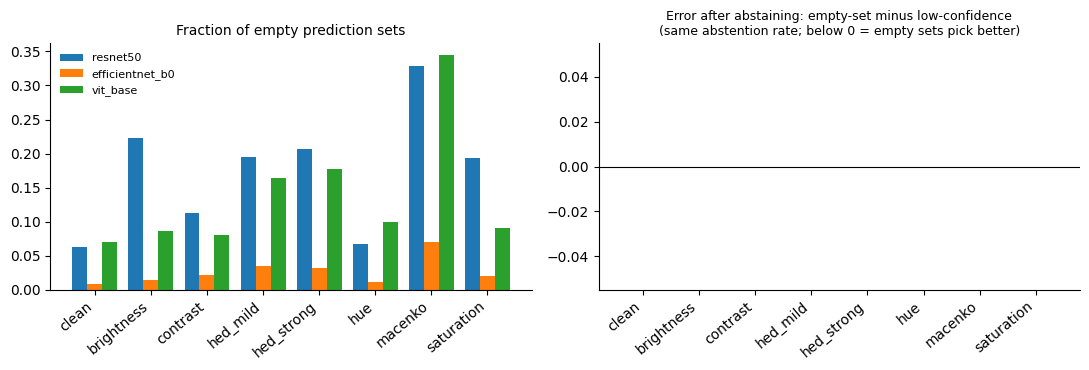


[2] paired leakage tests (random minus group macro-F1, per seed)
               model  n_seeds  mean_gap   ci_lo  ci_hi  t_test_p  wilcoxon_p  cohens_dz  seeds_with_gap_gt0  approx_seeds_for_80pct_power
            resnet50        5    0.0178 -0.0058 0.0415    0.1042      0.1250     0.9369                   4                             9
     efficientnet_b0        5    0.0168  0.0024 0.0311    0.0315      0.0625     1.4521                   5                             4
vit_base_patch16_224        5    0.0205 -0.0007 0.0418    0.0551      0.1250     1.1994                   4                             6
    mean of 3 models        5    0.0184  0.0074 0.0293    0.0095      0.0625     2.0882                   5                             2
   note: with 5 seeds the smallest possible two-sided Wilcoxon p is 0.0625, so it can never reach 0.05.


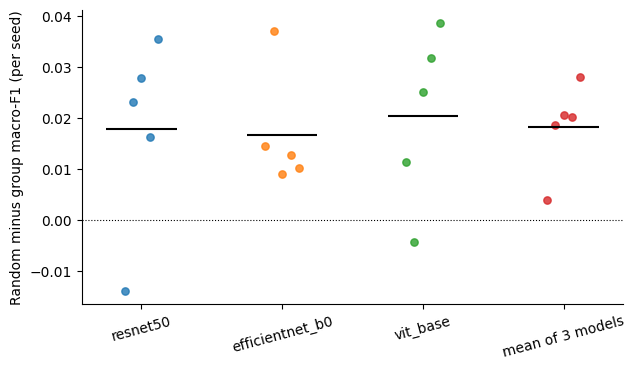


[3] Mondrian vs LAC, mean by shift family (seed 0)
                                              coverage  min_class_cov   size  frac_empty
model                family  method                                                     
efficientnet_b0      clean   lac-clean           0.942          0.869  1.006       0.008
                             lac-pooled          0.990          0.969  1.252       0.000
                             mondrian-clean      0.951          0.915  1.067       0.013
                             mondrian-pooled     0.985          0.965  1.241       0.000
                     hed     lac-clean           0.838          0.596  0.977       0.033
                             lac-pooled          0.953          0.831  1.511       0.000
                             mondrian-clean      0.827          0.685  1.007       0.074
                             mondrian-pooled     0.913          0.787  1.460       0.011
                     macenko lac-clean           0.585    

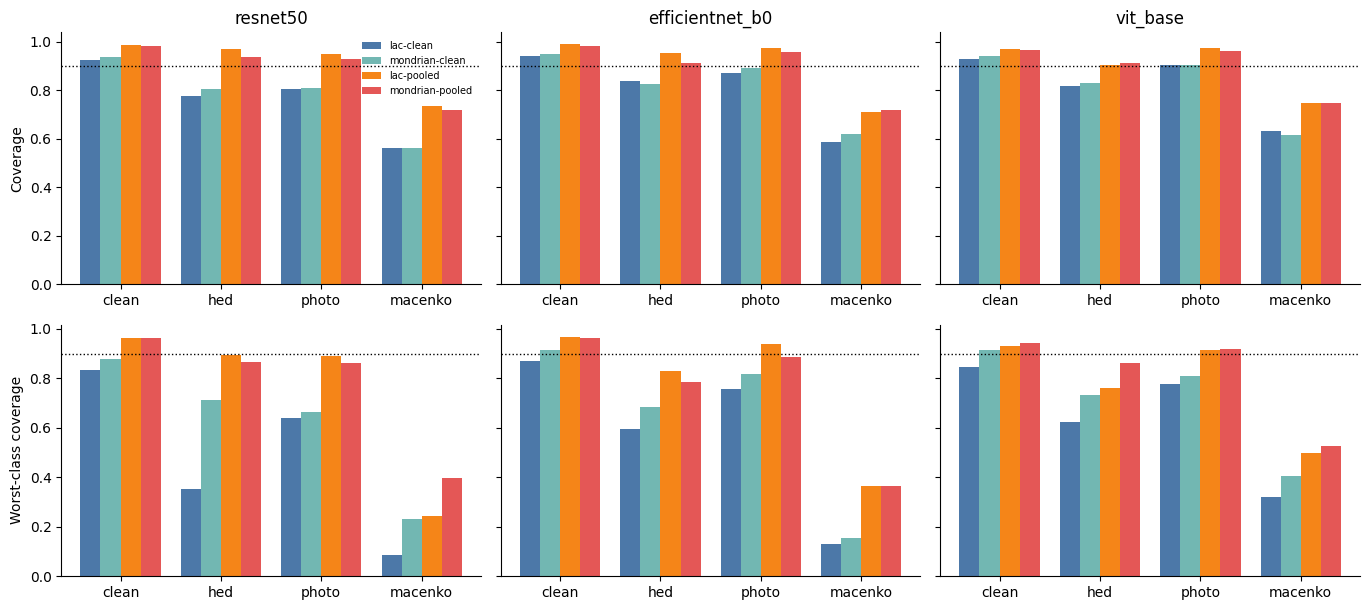


[4] coverage gap = empirical - 0.90 (negative = under-covers)
method                        lac-clean  lac-pooled
model                family                        
resnet50             clean        0.025       0.089
                     hed         -0.124       0.071
                     photo       -0.094       0.051
                     macenko     -0.337      -0.165
efficientnet_b0      clean        0.041       0.090
                     hed         -0.062       0.053
                     photo       -0.028       0.076
                     macenko     -0.315      -0.188
vit_base_patch16_224 clean        0.028       0.072
                     hed         -0.084       0.006
                     photo        0.003       0.074
                     macenko     -0.268      -0.152


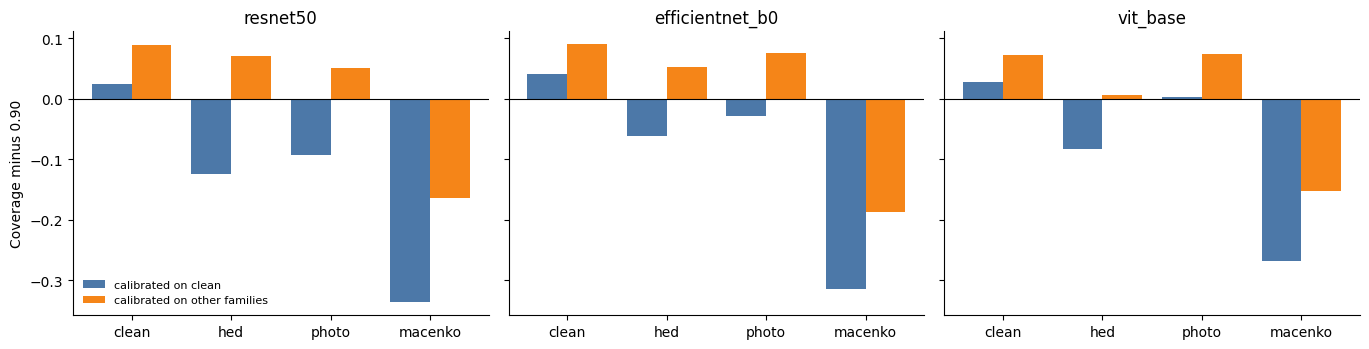


[5] ensemble vs single models, mean by family (seed 0, clean calibration)
                         macro_f1  coverage    ece   aurc
model           family                                   
efficientnet_b0 clean       0.938     0.942  0.033  0.006
                hed         0.832     0.838  0.034  0.033
                macenko     0.542     0.585  0.178  0.162
                photo       0.864     0.872  0.030  0.025
ensemble        clean       0.981     0.945  0.048  0.001
                hed         0.951     0.805  0.103  0.003
                macenko     0.786     0.537  0.082  0.056
                photo       0.954     0.862  0.069  0.005
resnet50        clean       0.973     0.925  0.014  0.002
                hed         0.888     0.776  0.026  0.016
                macenko     0.635     0.563  0.116  0.116
                photo       0.888     0.806  0.040  0.029
vit_base        clean       0.971     0.928  0.011  0.001
                hed         0.933     0.816  0.025  0.0

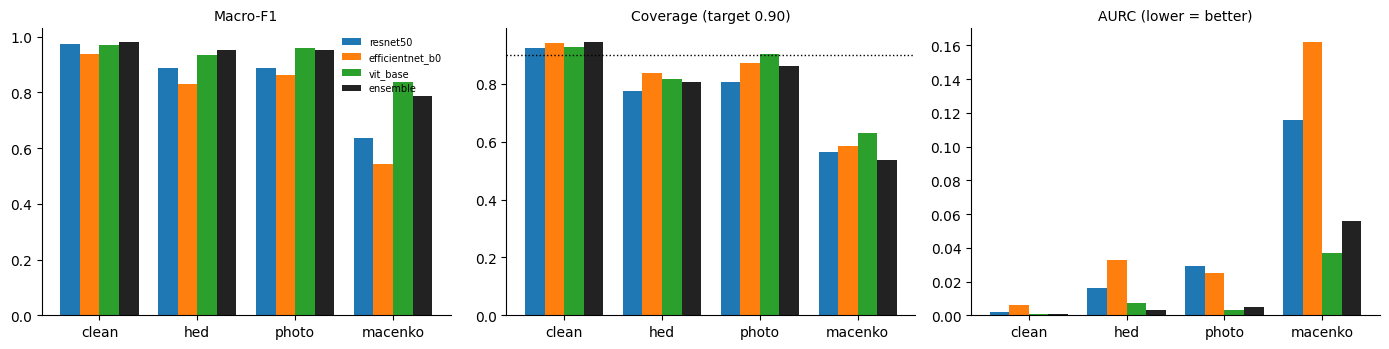


[6] XAI: change vs clean in (insertion minus deletion); CI excluding 0 = faithfulness changed
               model       cond               subset   n  mean_p_target  ins_minus_del_delta  ins_minus_del_lo  ins_minus_del_hi  ins_minus_del_norm_delta  ins_minus_del_norm_lo  ins_minus_del_norm_hi
            resnet50    macenko           all images 120         0.5915              -0.2022           -0.2363           -0.1692                   -0.3162                -0.5587                -0.0637
            resnet50    macenko prediction unchanged  77         0.8409              -0.1352           -0.1657           -0.1045                   -0.0778                -0.1305                -0.0200
            resnet50 hed_strong           all images 120         0.7476              -0.0649           -0.0905           -0.0400                   -0.0109                -0.0780                 0.0584
            resnet50 hed_strong prediction unchanged  98         0.8534              -0.0467         

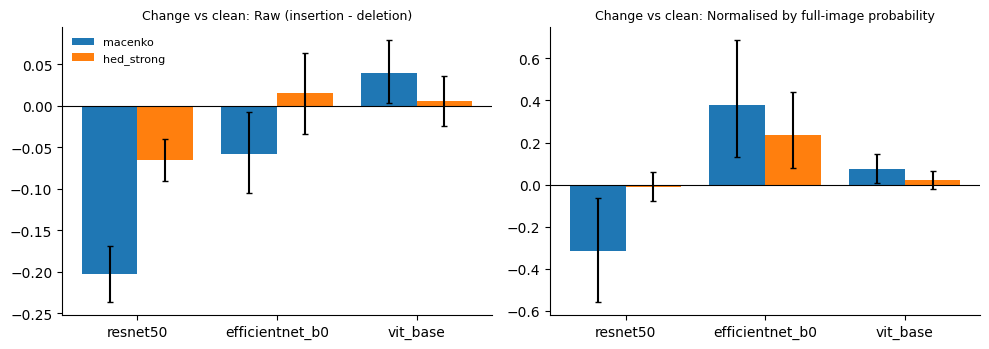


[7] images correct on clean that become wrong under shift (seed 0)
               model      shift  correct_to_wrong  wrong_to_correct  flip_rate  flip_dyskeratotic  flip_koilocytotic  flip_metaplastic  flip_parabasal  flip_superficial
            resnet50 hed_strong                54                 7     0.0902             0.0297             0.1008            0.3372          0.0210            0.0429
            resnet50    macenko               176                 4     0.2938             0.4851             0.2016            0.8023          0.1818            0.0429
     efficientnet_b0 hed_strong                75                18     0.1295             0.0300             0.3333            0.1765          0.0876            0.0490
     efficientnet_b0    macenko               221                11     0.3817             0.4000             0.6491            0.8118          0.2555            0.0210
vit_base_patch16_224 hed_strong                27                 4     0.0452         

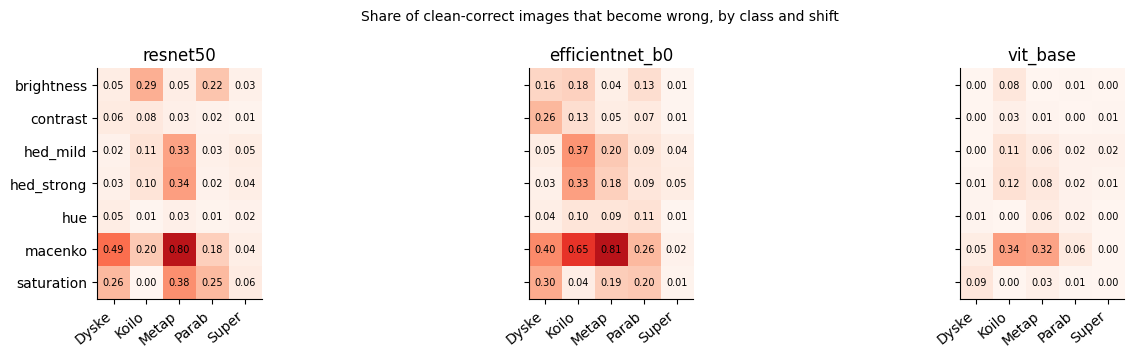

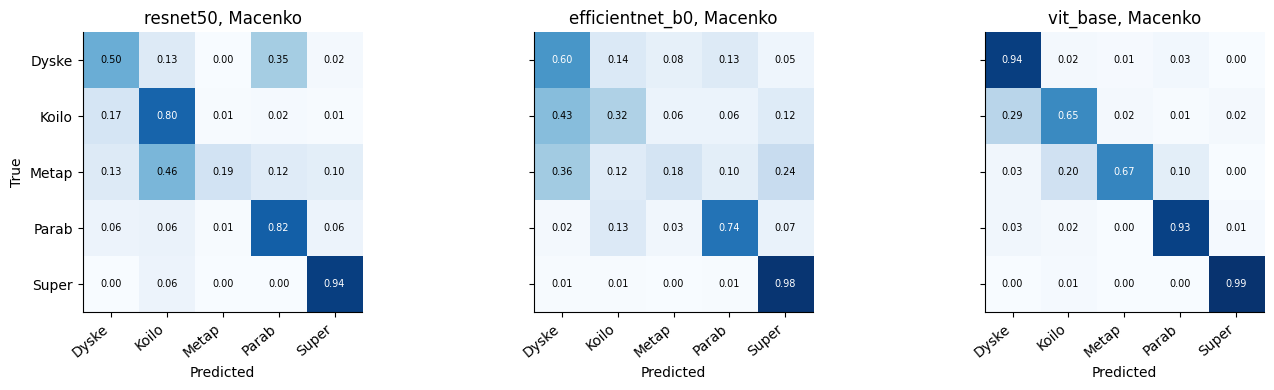


Saved F7 outputs to figures/ (f7_*). Re-run F5 to zip.


In [24]:
# F7: seven more outputs, all CPU, about a minute. Run in the same kernel after F6 (or a fresh kernel; it is self-contained).
#
#   Inputs : shift_logits_v2.pt (seed 0), baseline_results.csv (5 seeds), xai_per_image.csv (from the XAI cell)
#   Globals: classes, MODELS from your notebook.
#   Outputs: figures/f7_*.png/.pdf and figures/f7_*.csv.  Re-run F5 to zip them.
#
#   1 empty-set analysis (is an empty conformal set a useful abstain signal?)
#   2 paired leakage test per model and pooled over models (Wilcoxon, paired t, effect size, power)
#   3 Mondrian (class-conditional) conformal on the SIPaKMeD shifts
#   4 coverage-gap table by shift family
#   5 three-backbone ensemble
#   6 corrected XAI metrics (insertion minus deletion, probability-normalised AUC, paired CIs)
#   7 prediction-flip analysis (which classes break under which shift, and where they go)
#
# Items 1, 3, 4, 5, 7 use seed 0 (that is what shift_logits_v2.pt holds). Say so in the captions.

import os, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
ALPHA = 0.1
FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}
FAM_ORDER = ["clean", "hed", "photo", "macenko"]
SHORT = lambda n: n.replace("_patch16_224", "")
COL = {"lac-clean": "#4C78A8", "mondrian-clean": "#72B7B2", "lac-pooled": "#F58518", "mondrian-pooled": "#E45756"}


def save7(fig, stem):
    fig.savefig(f"{OUT}/{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/{stem}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)


def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def fit_T(logits, y):
    def nll(lt):
        p = softmax(logits / math.exp(lt))
        return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
    return math.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x)


def ece_np(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1)
    acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(conf[m].mean() - acc[m].mean())
    return e


def _q(s, alpha):
    n = len(s)
    return np.quantile(s, min(1.0, math.ceil((n + 1) * (1 - alpha)) / n), method="higher")


def lac_sets(p_cal, y_cal, p_test, alpha=ALPHA):
    q = _q(1 - p_cal[np.arange(len(y_cal)), y_cal], alpha)
    return (1 - p_test) <= q


def mondrian_sets(p_cal, y_cal, p_test, alpha=ALPHA):
    """Class-conditional split conformal: one threshold per true class."""
    K = p_cal.shape[1]
    q = np.array([_q(1 - p_cal[y_cal == c, c], alpha) if (y_cal == c).sum() > 1 else 1.0 for c in range(K)])
    return (1 - p_test) <= q[None, :]


def cover(S, y):
    return S[np.arange(len(y)), y]


def auroc(score, label):
    """P(score of a positive > score of a negative); positives = label 1."""
    label = np.asarray(label).astype(bool)
    if label.all() or (~label).all():
        return np.nan
    r = stats.rankdata(score)
    n1, n0 = label.sum(), (~label).sum()
    return (r[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def boot_mean(v, n=2000, seed=0):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    m = np.random.default_rng(seed).choice(v, (n, len(v))).mean(1)
    return v.mean(), *np.percentile(m, [2.5, 97.5])


def pooled(VL, split, name, yv, sh, shifts, T):
    pool = [s for s in shifts if FAMILY.get(s, s) != FAMILY.get(sh, sh)]
    return (np.concatenate([softmax(VL[(split, name, s)] / T) for s in pool]), np.tile(yv, len(pool)))


def run_f7(VL, TL, YV, YT, res, xai, classes, MODELS, sp="group"):
    K = len(classes)
    CN = [c[:5].title() for c in classes]
    shifts = ["clean"] + sorted({k[2] for k in VL if k[2] != "clean"})
    yv, yt = YV[sp], YT[sp]
    T0 = {n: fit_T(VL[(sp, n, "clean")], yv) for n in MODELS}
    P = lambda n, sh, T=None: softmax(TL[(sp, n, sh)] / (T or T0[n]))

    # ---- 1. empty-set analysis ------------------------------------------------------------------------------------
    rows = []
    for n in MODELS:
        pc = softmax(VL[(sp, n, "clean")] / T0[n])
        for sh in shifts:
            pt = P(n, sh); S = lac_sets(pc, yv, pt)
            empty = S.sum(1) == 0
            err = pt.argmax(1) != yt
            conf = pt.max(1)
            # confidence-threshold abstain at the SAME rate as empty sets, for a fair comparison
            k = int(empty.sum())
            thr_abst = np.zeros(len(yt), bool)
            if k > 0:
                thr_abst[np.argsort(conf)[:k]] = True
            rows.append(dict(model=n, shift=sh, frac_empty=empty.mean(),
                             acc_empty=(1 - err[empty]).mean() if empty.any() else np.nan,
                             acc_nonempty=(1 - err[~empty]).mean(),
                             err_after_empty_abstain=err[~empty].mean(),
                             err_after_lowconf_abstain_same_rate=err[~thr_abst].mean(),
                             auroc_empty_detects_error=auroc(empty.astype(float), err)))
    C1 = pd.DataFrame(rows).round(4); C1.to_csv(f"{OUT}/f7_1_empty_sets.csv", index=False)
    print("\n[1] empty conformal sets as an abstain signal (seed 0, clean calibration)"); print(C1.to_string(index=False))
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    w = 0.8 / len(MODELS)
    for j, n in enumerate(MODELS):
        d = C1[C1.model == n].set_index("shift").reindex(shifts)
        x = np.arange(len(shifts)) + (j - (len(MODELS) - 1) / 2) * w
        ax[0].bar(x, d["frac_empty"], w, label=SHORT(n))
        ax[1].bar(x, d["err_after_empty_abstain"] - d["err_after_lowconf_abstain_same_rate"], w, label=SHORT(n))
    for a in ax:
        a.set_xticks(range(len(shifts))); a.set_xticklabels(shifts, rotation=40, ha="right")
        a.spines[["top", "right"]].set_visible(False)
    ax[0].set_title("Fraction of empty prediction sets", fontsize=10); ax[0].legend(frameon=False, fontsize=8)
    ax[1].axhline(0, color="k", lw=0.8)
    ax[1].set_title("Error after abstaining: empty-set minus low-confidence\n(same abstention rate; below 0 = empty sets pick better)", fontsize=9)
    fig.tight_layout(); save7(fig, "f7_1_empty_sets")

    # ---- 2. paired leakage test -----------------------------------------------------------------------------------
    raw = res[(~res["calibrated"]) & res["split"].isin(["random", "group"])]
    rows, per_seed = [], {}
    for n in MODELS:
        r = raw[raw.model == n].pivot(index="seed", columns="split", values="macro_f1").dropna()
        per_seed[n] = (r["random"] - r["group"])
    per_seed["mean of 3 models"] = pd.concat(per_seed.values(), axis=1).dropna().mean(1)
    for n, d in per_seed.items():
        d = d.dropna(); m = d.mean(); sd = d.std(ddof=1); k = len(d)
        t = stats.ttest_1samp(d, 0.0).pvalue if k > 1 else np.nan               # paired t = one-sample t on the differences
        try:
            wp = stats.wilcoxon(d, alternative="two-sided").pvalue
        except ValueError:
            wp = np.nan
        dz = m / sd if sd > 0 else np.nan
        n80 = math.ceil(((1.96 + 0.84) / dz) ** 2) if dz and dz > 0 else np.nan
        h = stats.t.ppf(0.975, k - 1) * sd / math.sqrt(k)
        rows.append(dict(model=n, n_seeds=k, mean_gap=m, ci_lo=m - h, ci_hi=m + h, t_test_p=t, wilcoxon_p=wp,
                         cohens_dz=dz, seeds_with_gap_gt0=int((d > 0).sum()), approx_seeds_for_80pct_power=n80))
    C2 = pd.DataFrame(rows).round(4); C2.to_csv(f"{OUT}/f7_2_leakage_paired_tests.csv", index=False)
    print("\n[2] paired leakage tests (random minus group macro-F1, per seed)"); print(C2.to_string(index=False))
    print("   note: with 5 seeds the smallest possible two-sided Wilcoxon p is 0.0625, so it can never reach 0.05.")
    fig, a = plt.subplots(figsize=(6.5, 3.8))
    for i, (n, d) in enumerate(per_seed.items()):
        d = d.dropna()
        a.scatter(np.full(len(d), i) + np.linspace(-0.12, 0.12, len(d)), d, s=28, alpha=0.8)
        a.hlines(d.mean(), i - 0.25, i + 0.25, color="k")
    a.axhline(0, color="k", ls=":", lw=0.8)
    a.set_xticks(range(len(per_seed))); a.set_xticklabels([SHORT(n) for n in per_seed], rotation=15)
    a.set_ylabel("Random minus group macro-F1 (per seed)"); a.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); save7(fig, "f7_2_leakage_paired")

    # ---- 3. Mondrian conformal on the shifts ----------------------------------------------------------------------
    rows = []
    for n in MODELS:
        pc = softmax(VL[(sp, n, "clean")] / T0[n])
        for sh in shifts:
            pt = P(n, sh)
            pp, py = pooled(VL, sp, n, yv, sh, shifts, T0[n])
            for meth, S in [("lac-clean", lac_sets(pc, yv, pt)), ("mondrian-clean", mondrian_sets(pc, yv, pt)),
                            ("lac-pooled", lac_sets(pp, py, pt)), ("mondrian-pooled", mondrian_sets(pp, py, pt))]:
                cv = cover(S, yt)
                cc = [cv[yt == c].mean() for c in range(K)]
                rows.append(dict(model=n, shift=sh, family=FAMILY.get(sh, sh), method=meth, coverage=cv.mean(),
                                 min_class_cov=min(cc), size=S.sum(1).mean(), frac_empty=(S.sum(1) == 0).mean()))
    C3 = pd.DataFrame(rows).round(4); C3.to_csv(f"{OUT}/f7_3_mondrian_by_shift.csv", index=False)
    F3 = C3.groupby(["model", "family", "method"])[["coverage", "min_class_cov", "size", "frac_empty"]].mean().round(3)
    F3.to_csv(f"{OUT}/f7_3_mondrian_by_family.csv")
    print("\n[3] Mondrian vs LAC, mean by shift family (seed 0)"); print(F3.to_string())
    fig, ax = plt.subplots(2, len(MODELS), figsize=(4.6 * len(MODELS), 6.2), sharey="row")
    meths = list(COL)
    for j, n in enumerate(MODELS):
        for r, (col, ttl) in enumerate([("coverage", "Coverage"), ("min_class_cov", "Worst-class coverage")]):
            for mi, m in enumerate(meths):
                d = F3.loc[n].xs(m, level="method").reindex(FAM_ORDER)
                ax[r, j].bar(np.arange(len(FAM_ORDER)) + (mi - 1.5) * 0.2, d[col], 0.2, color=COL[m], label=m)
            ax[r, j].axhline(1 - ALPHA, color="k", ls=":", lw=1)
            ax[r, j].set_xticks(range(len(FAM_ORDER))); ax[r, j].set_xticklabels(FAM_ORDER)
            ax[r, j].spines[["top", "right"]].set_visible(False)
            if j == 0: ax[r, j].set_ylabel(ttl)
        ax[0, j].set_title(SHORT(n))
    ax[0, 0].legend(frameon=False, fontsize=7)
    fig.tight_layout(); save7(fig, "f7_3_mondrian_vs_lac")

    # ---- 4. coverage-gap table ------------------------------------------------------------------------------------
    G = C3[C3.method.isin(["lac-clean", "lac-pooled"])].copy()
    G["gap"] = G["coverage"] - (1 - ALPHA)
    G4 = G.groupby(["model", "family", "method"])["gap"].mean().unstack("method").reindex(
        pd.MultiIndex.from_product([MODELS, FAM_ORDER], names=["model", "family"])).round(3)
    G4.to_csv(f"{OUT}/f7_4_coverage_gap.csv")
    print("\n[4] coverage gap = empirical - 0.90 (negative = under-covers)"); print(G4.to_string())
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 3.6), sharey=True)
    for j, n in enumerate(MODELS):
        d = G4.loc[n].reindex(FAM_ORDER)
        ax[j].bar(np.arange(4) - 0.2, d["lac-clean"], 0.4, color=COL["lac-clean"], label="calibrated on clean")
        ax[j].bar(np.arange(4) + 0.2, d["lac-pooled"], 0.4, color=COL["lac-pooled"], label="calibrated on other families")
        ax[j].axhline(0, color="k", lw=0.8)
        ax[j].set_xticks(range(4)); ax[j].set_xticklabels(FAM_ORDER); ax[j].set_title(SHORT(n))
        ax[j].spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("Coverage minus 0.90"); ax[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); save7(fig, "f7_4_coverage_gap")

    # ---- 5. ensemble ----------------------------------------------------------------------------------------------
    def ens(shset, which):
        return np.mean([softmax(which[(sp, n, shset)] / T0[n]) for n in MODELS], axis=0)
    rows = []
    members = {SHORT(n): (lambda sh, n=n: P(n, sh), lambda n=n: softmax(VL[(sp, n, "clean")] / T0[n])) for n in MODELS}
    members["ensemble"] = (lambda sh: ens(sh, TL), lambda: ens("clean", VL))
    for name, (ptf, pcf) in members.items():
        pc = pcf()
        for sh in shifts:
            pt = ptf(sh); S = lac_sets(pc, yv, pt)
            conf, err = pt.max(1), (pt.argmax(1) != yt).astype(float)
            risk = np.cumsum(err[np.argsort(-conf)]) / np.arange(1, len(err) + 1)
            rows.append(dict(model=name, shift=sh, family=FAMILY.get(sh, sh), macro_f1=f1_score(yt, pt.argmax(1), average="macro"),
                             coverage=cover(S, yt).mean(), size=S.sum(1).mean(), ece=ece_np(pt, yt), aurc=risk.mean()))
    C5 = pd.DataFrame(rows).round(4); C5.to_csv(f"{OUT}/f7_5_ensemble_by_shift.csv", index=False)
    F5 = C5.groupby(["model", "family"])[["macro_f1", "coverage", "ece", "aurc"]].mean().round(3)
    F5.to_csv(f"{OUT}/f7_5_ensemble_by_family.csv")
    print("\n[5] ensemble vs single models, mean by family (seed 0, clean calibration)"); print(F5.to_string())
    names = list(members)
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    for a, (col, ttl) in zip(ax, [("macro_f1", "Macro-F1"), ("coverage", "Coverage (target 0.90)"), ("aurc", "AURC (lower = better)")]):
        for i, nm in enumerate(names):
            d = F5.loc[nm].reindex(FAM_ORDER)
            a.bar(np.arange(4) + (i - (len(names) - 1) / 2) * 0.2, d[col], 0.2, label=nm,
                  color="#222" if nm == "ensemble" else None)
        a.set_xticks(range(4)); a.set_xticklabels(FAM_ORDER); a.set_title(ttl, fontsize=10)
        a.spines[["top", "right"]].set_visible(False)
    ax[1].axhline(1 - ALPHA, color="k", ls=":", lw=1); ax[0].legend(frameon=False, fontsize=7)
    fig.tight_layout(); save7(fig, "f7_5_ensemble")

    # ---- 6. corrected XAI metrics ---------------------------------------------------------------------------------
    X = xai[xai.method == "saliency"].copy()
    X["ins_minus_del"] = X["ins_auc"] - X["del_auc"]
    ok = X["p_target"] > 0.05                                   # avoid dividing by a near-zero full-image probability
    X["del_norm"] = np.where(ok, X["del_auc"] / X["p_target"], np.nan)
    X["ins_norm"] = np.where(ok, X["ins_auc"] / X["p_target"], np.nan)
    X["ins_minus_del_norm"] = X["ins_norm"] - X["del_norm"]
    rows = []
    for n in X.model.unique():
        cl = X[(X.model == n) & (X.cond == "clean")].set_index("idx")
        for c in [c for c in X.cond.unique() if c != "clean"]:
            g = X[(X.model == n) & (X.cond == c)].set_index("idx")
            for subset, mask in [("all images", g.index == g.index), ("prediction unchanged", g["pred_same"].values)]:
                gg = g[mask]
                row = dict(model=n, cond=c, subset=subset, n=len(gg), mean_p_target=gg["p_target"].mean())
                for k in ["ins_minus_del", "ins_minus_del_norm"]:
                    m, lo, hi = boot_mean((gg[k] - cl.loc[gg.index, k]).values)
                    row.update({f"{k}_delta": m, f"{k}_lo": lo, f"{k}_hi": hi})
                rows.append(row)
    C6 = pd.DataFrame(rows).round(4); C6.to_csv(f"{OUT}/f7_6_xai_corrected.csv", index=False)
    print("\n[6] XAI: change vs clean in (insertion minus deletion); CI excluding 0 = faithfulness changed")
    print(C6[["model", "cond", "subset", "n", "mean_p_target", "ins_minus_del_delta", "ins_minus_del_lo", "ins_minus_del_hi",
              "ins_minus_del_norm_delta", "ins_minus_del_norm_lo", "ins_minus_del_norm_hi"]].to_string(index=False))
    clean_tab = X[X.cond == "clean"].groupby("model")[["ins_auc", "del_auc", "ins_minus_del"]].mean().round(3)
    print("\n   clean-image faithfulness (ins - del near 0 means the map is barely informative):"); print(clean_tab.to_string())
    d = C6[C6["subset"] == "all images"]
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
    for a, k, t in zip(ax, ["ins_minus_del", "ins_minus_del_norm"], ["Raw (insertion - deletion)", "Normalised by full-image probability"]):
        mods = list(d.model.unique())
        for i, c in enumerate(["macenko", "hed_strong"]):
            dd = d[d.cond == c].set_index("model").reindex(mods)
            a.bar(np.arange(len(mods)) + (i - 0.5) * 0.4, dd[f"{k}_delta"], 0.4,
                  yerr=np.vstack([dd[f"{k}_delta"] - dd[f"{k}_lo"], dd[f"{k}_hi"] - dd[f"{k}_delta"]]), capsize=2, label=c)
        a.axhline(0, color="k", lw=0.8); a.set_xticks(range(len(mods))); a.set_xticklabels([SHORT(m) for m in mods])
        a.set_title(f"Change vs clean: {t}", fontsize=9); a.spines[["top", "right"]].set_visible(False)
    ax[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); save7(fig, "f7_6_xai_corrected")

    # ---- 7. prediction-flip analysis ------------------------------------------------------------------------------
    rows, dest = [], {}
    for n in MODELS:
        yc = TL[(sp, n, "clean")].argmax(1)
        for sh in [s for s in shifts if s != "clean"]:
            ys = TL[(sp, n, sh)].argmax(1)
            good = yc == yt                                           # correct on clean
            broke = good & (ys != yt)
            fixed = (~good) & (ys == yt)
            row = dict(model=n, shift=sh, correct_to_wrong=int(broke.sum()), wrong_to_correct=int(fixed.sum()),
                       flip_rate=float(broke.sum() / max(good.sum(), 1)))
            for c in range(K):
                m = good & (yt == c)
                row[f"flip_{classes[c]}"] = float((broke & (yt == c)).sum() / max(m.sum(), 1))
            rows.append(row)
            if sh in ("macenko", "hed_strong"):
                cm = np.zeros((K, K))
                np.add.at(cm, (yt, ys), 1)
                dest[(n, sh)] = cm / cm.sum(1, keepdims=True)
    C7 = pd.DataFrame(rows).round(4); C7.to_csv(f"{OUT}/f7_7_prediction_flips.csv", index=False)
    print("\n[7] images correct on clean that become wrong under shift (seed 0)")
    print(C7[C7["shift"].isin(["macenko", "hed_strong"])].to_string(index=False))
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.8 * len(MODELS), 3.6))
    for j, n in enumerate(MODELS):
        d = C7[C7.model == n].set_index("shift")[[f"flip_{c}" for c in classes]]
        d = d.reindex([s for s in shifts if s != "clean"])
        im = ax[j].imshow(d.values, cmap="Reds", vmin=0, vmax=1)
        ax[j].set_xticks(range(K)); ax[j].set_xticklabels(CN, rotation=40, ha="right")
        ax[j].set_yticks(range(len(d))); ax[j].set_yticklabels(d.index if j == 0 else [])
        for i in range(len(d)):
            for c in range(K):
                ax[j].text(c, i, f"{d.values[i, c]:.2f}", ha="center", va="center", fontsize=7)
        ax[j].set_title(SHORT(n))
    fig.suptitle("Share of clean-correct images that become wrong, by class and shift", fontsize=10)
    fig.tight_layout(); save7(fig, "f7_7_flip_rate_by_class")
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.8 * len(MODELS), 4))
    for j, n in enumerate(MODELS):
        M = dest[(n, "macenko")]
        ax[j].imshow(M, cmap="Blues", vmin=0, vmax=1)
        ax[j].set_xticks(range(K)); ax[j].set_xticklabels(CN, rotation=40, ha="right")
        ax[j].set_yticks(range(K)); ax[j].set_yticklabels(CN if j == 0 else [])
        for i in range(K):
            for c in range(K):
                ax[j].text(c, i, f"{M[i, c]:.2f}", ha="center", va="center", fontsize=7, color="white" if M[i, c] > 0.5 else "black")
        ax[j].set_xlabel("Predicted"); ax[j].set_title(f"{SHORT(n)}, Macenko")
    ax[0].set_ylabel("True")
    fig.tight_layout(); save7(fig, "f7_7_macenko_confusion")
    print(f"\nSaved F7 outputs to {OUT}/ (f7_*). Re-run F5 to zip.")


def load_inputs():
    import torch
    try:
        S = torch.load("shift_logits_v2.pt", weights_only=False)
    except TypeError:
        S = torch.load("shift_logits_v2.pt")
    f = lambda t: t.detach().cpu().numpy().astype(np.float64)
    VL = {k: f(v) for k, v in S["VL"].items()}; TL = {k: f(v) for k, v in S["TL"].items()}
    YV = {k: v.numpy().astype(int) for k, v in S["YV"].items()}; YT = {k: v.numpy().astype(int) for k, v in S["YT"].items()}
    return VL, TL, YV, YT, pd.read_csv("baseline_results.csv"), pd.read_csv("xai_per_image.csv"), classes, MODELS


if "__SKIP_RUN__" not in globals():
    run_f7(*load_inputs())

   check group s1 resnet50: recomputed 0.9408 vs logged 0.9408
   check group s1 efficientnet_b0: recomputed 0.9187 vs logged 0.9202
   check group s1 vit_base_patch16_224: recomputed 0.9733 vs logged 0.9733
[group | seed 1] done in 229s
   check group s2 resnet50: recomputed 0.9231 vs logged 0.9231
   check group s2 efficientnet_b0: recomputed 0.9383 vs logged 0.9383
   check group s2 vit_base_patch16_224: recomputed 0.9485 vs logged 0.9485
[group | seed 2] done in 265s
   check group s3 resnet50: recomputed 0.9411 vs logged 0.9411
   check group s3 efficientnet_b0: recomputed 0.9279 vs logged 0.9279
   check group s3 vit_base_patch16_224: recomputed 0.9341 vs logged 0.9341
[group | seed 3] done in 234s
   check group s4 resnet50: recomputed 0.9397 vs logged 0.9397
   check group s4 efficientnet_b0: recomputed 0.9294 vs logged 0.9288
   check group s4 vit_base_patch16_224: recomputed 0.9417 vs logged 0.9417
[group | seed 4] done in 236s
seeds found: [0, 1, 2, 3, 4] | shifts: ['clean',

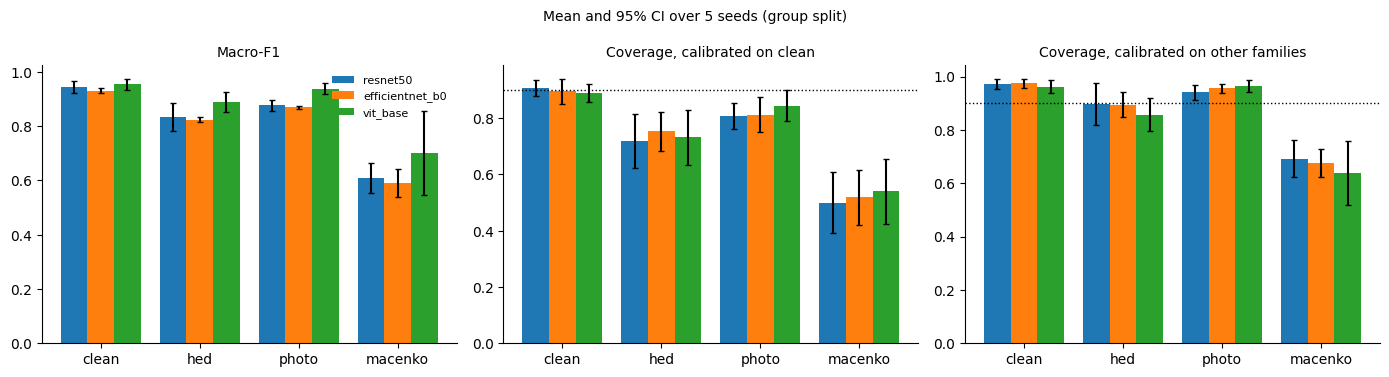


[2] coverage spread over random calibration subsets (all seeds pooled)
                                               mean      sd     p05     p95
model                shift      n_cal                                      
efficientnet_b0      clean      100          0.9046  0.0398  0.8449  0.9659
                                half of val  0.8983  0.0329  0.8526  0.9496
                     hed_strong 100          0.7705  0.0701  0.6690  0.8943
                                half of val  0.7550  0.0560  0.6804  0.8520
                     macenko    100          0.5465  0.0885  0.3991  0.6911
                                half of val  0.5292  0.0758  0.4020  0.6356
resnet50             clean      100          0.9131  0.0339  0.8521  0.9601
                                half of val  0.9080  0.0244  0.8693  0.9384
                     hed_strong 100          0.7389  0.0848  0.6094  0.8686
                                half of val  0.7210  0.0699  0.6151  0.8336
                

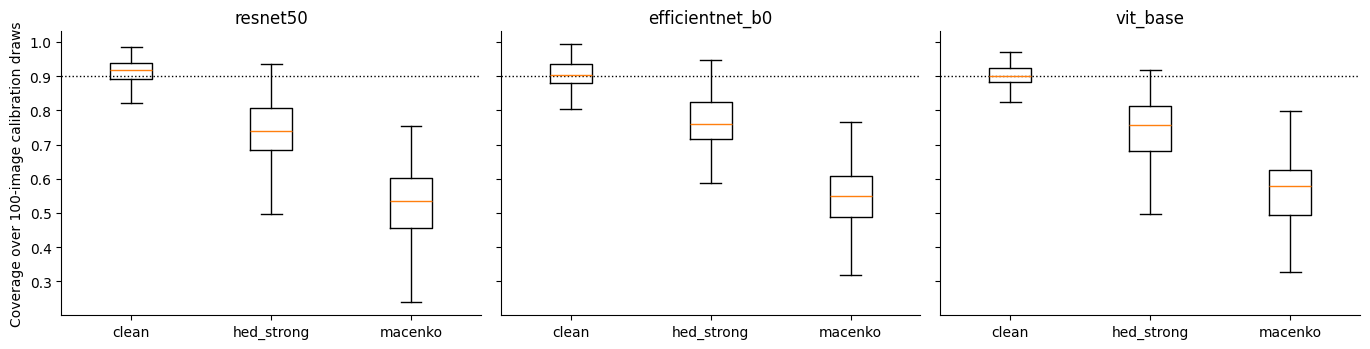


[3] LAC vs APS vs RAPS, clean calibration, mean over seeds
               model  family method  coverage  coverage_lo  coverage_hi   size  empty
     efficientnet_b0   clean    APS    0.8948       0.8477       0.9419 1.0978 0.0740
     efficientnet_b0   clean    LAC    0.8951       0.8499       0.9404 0.9362 0.0667
     efficientnet_b0   clean   RAPS    0.8949       0.8480       0.9417 1.0949 0.0737
     efficientnet_b0     hed    APS    0.8671       0.8013       0.9328 1.3498 0.0552
     efficientnet_b0     hed    LAC    0.7539       0.6845       0.8234 0.8503 0.1518
     efficientnet_b0     hed   RAPS    0.8659       0.8003       0.9315 1.3352 0.0550
     efficientnet_b0 macenko    APS    0.7543       0.7005       0.8080 1.6220 0.0361
     efficientnet_b0 macenko    LAC    0.5192       0.4214       0.6170 0.7419 0.2601
     efficientnet_b0 macenko   RAPS    0.7512       0.7019       0.8005 1.5935 0.0358
     efficientnet_b0   photo    APS    0.8725       0.8277       0.9172 1.1986 0

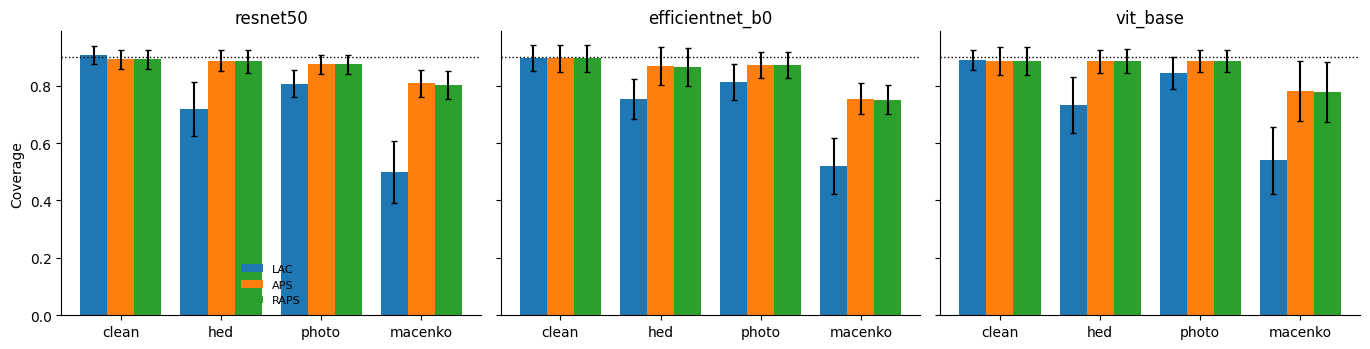


[4] binary normal vs abnormal (abnormal = ['koilocytotic', 'dyskeratotic']); threshold chosen on val for 90% specificity
               model  family  auroc  sens_at_val_spec90  spec_at_val_spec90  sens_at_0p5  spec_at_0p5
     efficientnet_b0   clean 0.9946              0.9879              0.8965       0.9550       0.9674
     efficientnet_b0     hed 0.9751              0.9611              0.7804       0.8923       0.9315
     efficientnet_b0 macenko 0.8730              0.9267              0.5985       0.7709       0.7992
     efficientnet_b0   photo 0.9860              0.9834              0.8299       0.9386       0.9304
            resnet50   clean 0.9952              0.9912              0.9035       0.9766       0.9658
            resnet50     hed 0.9811              0.9849              0.6818       0.9358       0.9000
            resnet50 macenko 0.8940              0.9532              0.5746       0.8109       0.7797
            resnet50   photo 0.9879              0.9846       

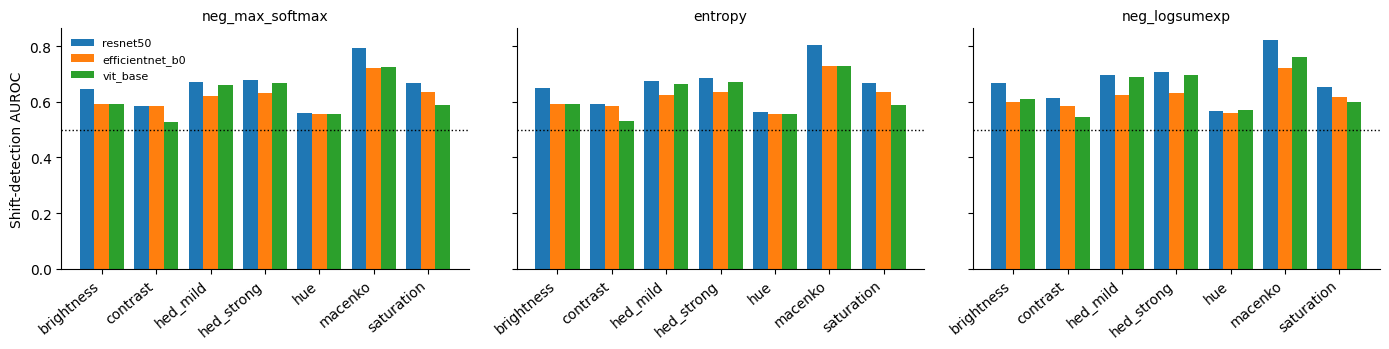


Saved F8 outputs to figures/ (f8_*). Re-run F5 to zip.


In [25]:
# F8: items 1 to 6 from the "analysis" list.  TWO CELLS.
#   CELL F8a (GPU, ~15 to 25 min): collect shift logits for seeds 1 to 4 (seed 0 already exists in shift_logits_v2.pt).
#   CELL F8b (CPU, ~1 to 3 min) : analyses on all 5 seeds.
#       1 shift results with 95% CIs over seeds        4 binary normal-vs-abnormal on SIPaKMeD
#       2 coverage variability (cal-set resampling,    5 per-class AUROC with CIs over seeds
#         test bootstrap, theory)                      6 shift detection from logits
#       3 APS / RAPS vs LAC
# Outputs: figures/f8_*.png/.pdf/.csv.   Re-run F5 afterwards to zip them.


# %% ===================== CELL F8a: collect shift logits for seeds 1 to 4 (GPU) =====================
# Needs from earlier cells: df, MODELS, DEVICE, classes, group_split, random_split, materialize, collect, SHIFTS, f1_score.
# SHIFTS must be the v2 version (cell 12: hed_mild 0.15, hed_strong 0.30). Do NOT re-run cell 10.
# Resumable: finished (split, seed) pairs are skipped, and the file is saved after each one.
import os, time
import numpy as np, pandas as pd, torch, timm
from sklearn.metrics import f1_score

SEEDS_COLLECT = [1, 2, 3, 4]
SPLITS_COLLECT = ["group"]            # add "random" if you want the same tables for the random split (doubles the time)
SEED_FILE = "shift_logits_seeds.pt"


def load_ckpt_seed(name, split, seed):
    m = timm.create_model(name, pretrained=False, num_classes=len(classes))
    m.load_state_dict(torch.load(f"ckpt_{split}_{name}_s{seed}.pt", map_location="cpu"))
    return m.to(DEVICE).eval()


def collect_seeds():
    store = torch.load(SEED_FILE, weights_only=False) if os.path.exists(SEED_FILE) else dict(VL={}, TL={}, YV={}, YT={})
    base = pd.read_csv("baseline_results.csv")
    for seed in SEEDS_COLLECT:
        for split in SPLITS_COLLECT:
            if (split, seed) in store["YV"]:
                print("skip", split, seed); continue
            t0 = time.time()
            tr, va, te = (group_split if split == "group" else random_split)(df, seed)
            models = {n: load_ckpt_seed(n, split, seed) for n in MODELS}
            for sh, f in SHIFTS.items():
                Xv, yv = materialize(va, f); Xt, yt = materialize(te, f)
                for n, m in models.items():
                    store["VL"][(split, seed, n, sh)] = collect(m, Xv)
                    store["TL"][(split, seed, n, sh)] = collect(m, Xt)
                store["YV"][(split, seed)], store["YT"][(split, seed)] = yv, yt
                del Xv, Xt
            # sanity: clean macro-F1 here must equal the one logged during training
            for n in MODELS:
                f1 = f1_score(yt.numpy(), store["TL"][(split, seed, n, "clean")].argmax(1).numpy(), average="macro")
                ref = base[(base.split == split) & (base.seed == seed) & (base.model == n) & (~base.calibrated)]["macro_f1"]
                print(f"   check {split} s{seed} {n}: recomputed {f1:.4f} vs logged {float(ref.iloc[0]):.4f}")
            del models; torch.cuda.empty_cache()
            torch.save(store, SEED_FILE)
            print(f"[{split} | seed {seed}] done in {time.time() - t0:.0f}s")


collect_seeds()


# %% ===================== CELL F8b: analyses on all seeds (CPU) =====================
# Needs: classes, MODELS (globals), shift_logits_v2.pt (seed 0), shift_logits_seeds.pt (seeds 1 to 4), baseline_results.csv.
import os, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.metrics import f1_score

OUT = "figures"; os.makedirs(OUT, exist_ok=True)
ALPHA = 0.1
FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}
FAM_ORDER = ["clean", "hed", "photo", "macenko"]
ABN_NAMES = ["koilocytotic", "dyskeratotic"]      # binary mapping used in the Sci Rep 2026 precedent; check it matches your ABN
SHORT = lambda n: n.replace("_patch16_224", "")


def save8(fig, stem):
    fig.savefig(f"{OUT}/{stem}.png", dpi=300, bbox_inches="tight")
    fig.savefig(f"{OUT}/{stem}.pdf", bbox_inches="tight")
    plt.show(); plt.close(fig)


def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z)
    return e / e.sum(1, keepdims=True)


def fit_T(logits, y):
    def nll(lt):
        p = softmax(logits / math.exp(lt))
        return -np.log(p[np.arange(len(y)), y] + 1e-12).mean()
    return math.exp(minimize_scalar(nll, bounds=(-3, 3), method="bounded").x)


def ece_np(p, y, bins=15):
    conf, pred = p.max(1), p.argmax(1)
    acc = (pred == y).astype(float)
    edges = np.linspace(0, 1, bins + 1); e = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            e += m.mean() * abs(conf[m].mean() - acc[m].mean())
    return e


def _q(s, alpha):
    n = len(s)
    return np.quantile(s, min(1.0, math.ceil((n + 1) * (1 - alpha)) / n), method="higher")


def lac_sets(p_cal, y_cal, p_test, alpha=ALPHA):
    return (1 - p_test) <= _q(1 - p_cal[np.arange(len(y_cal)), y_cal], alpha)


def _aps_scores(P, u, lam, kreg):
    K = P.shape[1]
    order = np.argsort(-P, 1); Ps = np.take_along_axis(P, order, 1)
    cum = np.cumsum(Ps, 1)
    Es = (cum - Ps) + u[:, None] * Ps + lam * np.maximum(np.arange(1, K + 1)[None, :] - kreg, 0)
    E = np.empty_like(Es); np.put_along_axis(E, order, Es, 1)
    return E


def aps_sets(p_cal, y_cal, p_test, alpha=ALPHA, lam=0.0, kreg=0, seed=0):
    """Randomised APS; lam > 0 gives RAPS (rank penalty)."""
    rng = np.random.default_rng(seed)
    Ec = _aps_scores(p_cal, rng.random(len(p_cal)), lam, kreg)
    q = _q(Ec[np.arange(len(y_cal)), y_cal], alpha)
    return _aps_scores(p_test, rng.random(len(p_test)), lam, kreg) <= q


def cover(S, y):
    return S[np.arange(len(y)), y]


def auroc(score, label):
    label = np.asarray(label).astype(bool)
    if label.all() or (~label).all():
        return np.nan
    r = stats.rankdata(score); n1, n0 = label.sum(), (~label).sum()
    return (r[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def tci(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]; n = len(x)
    if n < 2: return (x.mean() if n else np.nan), np.nan, np.nan
    h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / math.sqrt(n)
    return x.mean(), x.mean() - h, x.mean() + h


def agg_seeds(d, by, cols):
    """Mean and 95% t-CI over seeds. d must have a 'seed' column; rows are averaged within seed first."""
    per = d.groupby(["seed"] + by)[cols].mean().reset_index()
    rows = []
    for key, g in per.groupby(by):
        key = key if isinstance(key, tuple) else (key,)
        r = dict(zip(by, key)); r["n_seeds"] = g["seed"].nunique()
        for c in cols:
            m, lo, hi = tci(g[c]); r[c] = m; r[c + "_lo"] = lo; r[c + "_hi"] = hi
        rows.append(r)
    return pd.DataFrame(rows)


def load_all():
    import torch
    ld = lambda f: torch.load(f, weights_only=False)
    f = lambda t: t.detach().cpu().numpy().astype(np.float64)
    S0 = ld("shift_logits_v2.pt")
    VL = {(sp, 0, n, sh): f(v) for (sp, n, sh), v in S0["VL"].items()}
    TL = {(sp, 0, n, sh): f(v) for (sp, n, sh), v in S0["TL"].items()}
    YV = {(sp, 0): v.numpy().astype(int) for sp, v in S0["YV"].items()}
    YT = {(sp, 0): v.numpy().astype(int) for sp, v in S0["YT"].items()}
    if os.path.exists("shift_logits_seeds.pt"):
        S1 = ld("shift_logits_seeds.pt")
        VL.update({k: f(v) for k, v in S1["VL"].items()}); TL.update({k: f(v) for k, v in S1["TL"].items()})
        YV.update({k: v.numpy().astype(int) for k, v in S1["YV"].items()})
        YT.update({k: v.numpy().astype(int) for k, v in S1["YT"].items()})
    return VL, TL, YV, YT


def run_f8(VL, TL, YV, YT, classes, MODELS, sp="group", boot_n=1000, resample_n=200):
    K = len(classes)
    seeds = sorted({k[1] for k in VL if k[0] == sp})
    shifts = ["clean"] + sorted({k[3] for k in VL if k[3] != "clean"})
    print("seeds found:", seeds, "| shifts:", shifts)
    T0 = {(s, n): fit_T(VL[(sp, s, n, "clean")], YV[(sp, s)]) for s in seeds for n in MODELS}

    def pooled(s, n, sh):
        pool = [x for x in shifts if FAMILY.get(x, x) != FAMILY.get(sh, sh)]
        pl = np.concatenate([VL[(sp, s, n, x)] for x in pool]); py = np.tile(YV[(sp, s)], len(pool))
        Tp = fit_T(pl, py)
        return softmax(pl / Tp), py, Tp

    # ---- 1. shift results with CIs over seeds ---------------------------------------------------------------------
    rows = []
    for s in seeds:
        yv, yt = YV[(sp, s)], YT[(sp, s)]
        for n in MODELS:
            pc = softmax(VL[(sp, s, n, "clean")] / T0[(s, n)])
            for sh in shifts:
                tl = TL[(sp, s, n, sh)]; pt = softmax(tl / T0[(s, n)])
                Sc = lac_sets(pc, yv, pt)
                pp, py, Tp = pooled(s, n, sh); Sp = lac_sets(pp, py, softmax(tl / Tp))
                rows.append(dict(seed=s, model=n, shift=sh, family=FAMILY.get(sh, sh),
                                 macro_f1=f1_score(yt, tl.argmax(1), average="macro"),
                                 cov_clean_cal=cover(Sc, yt).mean(), size_clean_cal=Sc.sum(1).mean(),
                                 empty_clean_cal=(Sc.sum(1) == 0).mean(), cov_pooled_cal=cover(Sp, yt).mean(),
                                 size_pooled_cal=Sp.sum(1).mean(), ece_after_ts=ece_np(pt, yt)))
    R1 = pd.DataFrame(rows); R1.to_csv(f"{OUT}/f8_1_per_seed_shift_results.csv", index=False)
    cols = ["macro_f1", "cov_clean_cal", "cov_pooled_cal", "size_clean_cal", "size_pooled_cal", "empty_clean_cal", "ece_after_ts"]
    A1 = agg_seeds(R1, ["model", "family"], cols)
    A1["family"] = pd.Categorical(A1["family"], FAM_ORDER, ordered=True)
    A1 = A1.sort_values(["model", "family"]).round(4); A1.to_csv(f"{OUT}/f8_1_shift_family_ci.csv", index=False)
    print(f"\n[1] shift results by family, mean and 95% CI over {len(seeds)} seeds")
    print(A1[["model", "family", "n_seeds", "macro_f1", "macro_f1_lo", "macro_f1_hi", "cov_clean_cal", "cov_clean_cal_lo",
              "cov_clean_cal_hi", "cov_pooled_cal", "cov_pooled_cal_lo", "cov_pooled_cal_hi"]].to_string(index=False))
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
    for a, (c, t) in zip(ax, [("macro_f1", "Macro-F1"), ("cov_clean_cal", "Coverage, calibrated on clean"),
                              ("cov_pooled_cal", "Coverage, calibrated on other families")]):
        for i, n in enumerate(MODELS):
            d = A1[A1.model == n].set_index("family").reindex(FAM_ORDER)
            a.bar(np.arange(4) + (i - 1) * 0.27, d[c], 0.27, label=SHORT(n),
                  yerr=np.vstack([d[c] - d[c + "_lo"], d[c + "_hi"] - d[c]]), capsize=2)
        a.set_xticks(range(4)); a.set_xticklabels(FAM_ORDER); a.set_title(t, fontsize=10)
        a.spines[["top", "right"]].set_visible(False)
    ax[1].axhline(1 - ALPHA, color="k", ls=":", lw=1); ax[2].axhline(1 - ALPHA, color="k", ls=":", lw=1)
    ax[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"Mean and 95% CI over {len(seeds)} seeds ({sp} split)", fontsize=10)
    fig.tight_layout(); save8(fig, "f8_1_shift_family_ci")

    # ---- 2. coverage variability ----------------------------------------------------------------------------------
    rng = np.random.default_rng(0)
    rows = []
    for s in seeds:
        yv, yt = YV[(sp, s)], YT[(sp, s)]
        for n in MODELS:
            Pv = softmax(VL[(sp, s, n, "clean")] / T0[(s, n)])
            for sh in ["clean", "hed_strong", "macenko"]:
                pt = softmax(TL[(sp, s, n, sh)] / T0[(s, n)])
                for lab, ncal in [(100, 100), ("half of val", len(yv) // 2)]:
                    for _ in range(resample_n):
                        idx = rng.choice(len(yv), ncal, replace=False)
                        rows.append(dict(seed=s, model=n, shift=sh, n_cal=lab,
                                         cov=cover(lac_sets(Pv[idx], yv[idx], pt), yt).mean()))
    R2 = pd.DataFrame(rows)
    T2 = R2.groupby(["model", "shift", "n_cal"])["cov"].agg(mean="mean", sd="std",
                                                           p05=lambda x: x.quantile(.05), p95=lambda x: x.quantile(.95)).round(4)
    th = []
    for lab, ncal in [(100, 100), ("half of val", len(YV[(sp, seeds[0])]) // 2)]:
        l = math.floor((ncal + 1) * ALPHA); a_, b_ = ncal + 1 - l, l
        th.append(dict(n_cal=lab, n=ncal, theory_mean=a_ / (a_ + b_), theory_sd=math.sqrt(a_ * b_ / ((a_ + b_) ** 2 * (a_ + b_ + 1)))))
    TH = pd.DataFrame(th).round(4)
    T2.to_csv(f"{OUT}/f8_2_coverage_resampling.csv"); TH.to_csv(f"{OUT}/f8_2_theory_beta.csv", index=False)
    print("\n[2] coverage spread over random calibration subsets (all seeds pooled)"); print(T2.to_string())
    print("\n   exchangeable (no shift) theory: coverage ~ Beta; sd of coverage over calibration draws"); print(TH.to_string(index=False))
    # test-set bootstrap CI for the headline numbers, seed 0
    rows = []
    s = seeds[0]; yv, yt = YV[(sp, s)], YT[(sp, s)]
    for n in MODELS:
        pc = softmax(VL[(sp, s, n, "clean")] / T0[(s, n)])
        for sh in shifts:
            cv = cover(lac_sets(pc, yv, softmax(TL[(sp, s, n, sh)] / T0[(s, n)])), yt).astype(float)
            b = rng.choice(cv, (boot_n, len(cv))).mean(1)
            rows.append(dict(model=n, shift=sh, coverage=cv.mean(), ci_lo=np.percentile(b, 2.5), ci_hi=np.percentile(b, 97.5)))
    pd.DataFrame(rows).round(4).to_csv(f"{OUT}/f8_2_test_bootstrap_ci_seed{s}.csv", index=False)
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 3.6), sharey=True)
    for j, n in enumerate(MODELS):
        d = R2[(R2.model == n) & (R2.n_cal == 100)]
        data = [d[d["shift"] == sh]["cov"].values for sh in ["clean", "hed_strong", "macenko"]]
        ax[j].boxplot(data, showfliers=False)
        ax[j].set_xticklabels(["clean", "hed_strong", "macenko"]); ax[j].axhline(1 - ALPHA, color="k", ls=":", lw=1)
        ax[j].set_title(SHORT(n)); ax[j].spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("Coverage over 100-image calibration draws")
    fig.tight_layout(); save8(fig, "f8_2_coverage_resampling")

    # ---- 3. LAC vs APS vs RAPS ------------------------------------------------------------------------------------
    rows = []
    for s in seeds:
        yv, yt = YV[(sp, s)], YT[(sp, s)]
        for n in MODELS:
            pc = softmax(VL[(sp, s, n, "clean")] / T0[(s, n)])
            for sh in shifts:
                pt = softmax(TL[(sp, s, n, sh)] / T0[(s, n)])
                for meth, S in [("LAC", lac_sets(pc, yv, pt)), ("APS", aps_sets(pc, yv, pt, seed=s)),
                                ("RAPS", aps_sets(pc, yv, pt, lam=0.01, kreg=2, seed=s))]:
                    rows.append(dict(seed=s, model=n, family=FAMILY.get(sh, sh), method=meth,
                                     coverage=cover(S, yt).mean(), size=S.sum(1).mean(), empty=(S.sum(1) == 0).mean()))
    A3 = agg_seeds(pd.DataFrame(rows), ["model", "family", "method"], ["coverage", "size", "empty"]).round(4)
    A3.to_csv(f"{OUT}/f8_3_score_comparison.csv", index=False)
    print("\n[3] LAC vs APS vs RAPS, clean calibration, mean over seeds"); print(A3[["model", "family", "method", "coverage", "coverage_lo", "coverage_hi", "size", "empty"]].to_string(index=False))
    fig, ax = plt.subplots(1, len(MODELS), figsize=(4.6 * len(MODELS), 3.6), sharey=True)
    for j, n in enumerate(MODELS):
        for i, m in enumerate(["LAC", "APS", "RAPS"]):
            d = A3[(A3.model == n) & (A3.method == m)].set_index("family").reindex(FAM_ORDER)
            ax[j].bar(np.arange(4) + (i - 1) * 0.27, d["coverage"], 0.27, label=m,
                      yerr=np.vstack([d["coverage"] - d["coverage_lo"], d["coverage_hi"] - d["coverage"]]), capsize=2)
        ax[j].axhline(1 - ALPHA, color="k", ls=":", lw=1)
        ax[j].set_xticks(range(4)); ax[j].set_xticklabels(FAM_ORDER); ax[j].set_title(SHORT(n))
        ax[j].spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("Coverage"); ax[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); save8(fig, "f8_3_lac_vs_aps_raps")

    # ---- 4. binary normal vs abnormal on SIPaKMeD -----------------------------------------------------------------
    abn = [classes.index(c) for c in ABN_NAMES]
    rows = []
    for s in seeds:
        yv, yt = YV[(sp, s)], YT[(sp, s)]
        ybv, ybt = np.isin(yv, abn).astype(int), np.isin(yt, abn).astype(int)
        for n in MODELS:
            pa_v = softmax(VL[(sp, s, n, "clean")] / T0[(s, n)])[:, abn].sum(1)
            thr = np.quantile(pa_v[ybv == 0], 0.90)                     # threshold giving ~90% specificity on val
            for sh in shifts:
                pa = softmax(TL[(sp, s, n, sh)] / T0[(s, n)])[:, abn].sum(1)
                rows.append(dict(seed=s, model=n, family=FAMILY.get(sh, sh), auroc=auroc(pa, ybt),
                                 sens_at_val_spec90=(pa[ybt == 1] > thr).mean(), spec_at_val_spec90=(pa[ybt == 0] <= thr).mean(),
                                 sens_at_0p5=(pa[ybt == 1] > 0.5).mean(), spec_at_0p5=(pa[ybt == 0] <= 0.5).mean()))
    A4 = agg_seeds(pd.DataFrame(rows), ["model", "family"], ["auroc", "sens_at_val_spec90", "spec_at_val_spec90",
                                                              "sens_at_0p5", "spec_at_0p5"]).round(4)
    A4.to_csv(f"{OUT}/f8_4_binary_normal_abnormal.csv", index=False)
    print(f"\n[4] binary normal vs abnormal (abnormal = {ABN_NAMES}); threshold chosen on val for 90% specificity")
    print(A4[["model", "family", "auroc", "sens_at_val_spec90", "spec_at_val_spec90", "sens_at_0p5", "spec_at_0p5"]].to_string(index=False))

    # ---- 5. per-class AUROC ---------------------------------------------------------------------------------------
    rows = []
    for s in seeds:
        yt = YT[(sp, s)]
        for n in MODELS:
            pt = softmax(TL[(sp, s, n, "clean")] / T0[(s, n)])
            r = dict(seed=s, model=n)
            for c in range(K):
                r[classes[c]] = auroc(pt[:, c], (yt == c).astype(int))
            r["macro"] = np.nanmean([r[c] for c in classes]); rows.append(r)
    A5 = agg_seeds(pd.DataFrame(rows), ["model"], classes + ["macro"]).round(4)
    A5.to_csv(f"{OUT}/f8_5_per_class_auroc.csv", index=False)
    print("\n[5] one-vs-rest AUROC, clean test, mean over seeds (CI columns in the CSV)")
    print(A5[["model"] + classes + ["macro"]].to_string(index=False))

    # ---- 6. shift detection from logits ---------------------------------------------------------------------------
    def scores(lg):
        p = softmax(lg); H = -(p * np.log(p + 1e-12)).sum(1)
        lse = np.log(np.exp(lg - lg.max(1, keepdims=True)).sum(1)) + lg.max(1)
        return {"neg_max_softmax": -p.max(1), "entropy": H, "neg_logsumexp": -lse}
    rows = []
    for s in seeds:
        for n in MODELS:
            sc0 = scores(TL[(sp, s, n, "clean")])
            for sh in [x for x in shifts if x != "clean"]:
                sc1 = scores(TL[(sp, s, n, sh)])
                for k in sc0:
                    lab = np.r_[np.zeros(len(sc0[k])), np.ones(len(sc1[k]))]
                    rows.append(dict(seed=s, model=n, shift=sh, score=k, auroc=auroc(np.r_[sc0[k], sc1[k]], lab)))
    D = pd.DataFrame(rows)
    A6 = agg_seeds(D, ["model", "shift", "score"], ["auroc"]).round(4); A6.to_csv(f"{OUT}/f8_6_shift_detection.csv", index=False)
    print("\n[6] AUROC of detecting 'this test image is shifted' from the logits (0.5 = cannot tell)")
    print(A6[A6.score == "neg_max_softmax"].pivot(index="shift", columns="model", values="auroc").round(3).to_string())
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
    sh_list = [x for x in shifts if x != "clean"]
    for a, sc in zip(ax, ["neg_max_softmax", "entropy", "neg_logsumexp"]):
        d = A6[A6.score == sc].pivot(index="shift", columns="model", values="auroc").reindex(sh_list)[MODELS]
        for i, n in enumerate(MODELS):
            a.bar(np.arange(len(sh_list)) + (i - 1) * 0.27, d[n], 0.27, label=SHORT(n))
        a.axhline(0.5, color="k", ls=":", lw=1)
        a.set_xticks(range(len(sh_list))); a.set_xticklabels(sh_list, rotation=40, ha="right"); a.set_title(sc, fontsize=10)
        a.spines[["top", "right"]].set_visible(False)
    ax[0].set_ylabel("Shift-detection AUROC"); ax[0].legend(frameon=False, fontsize=8)
    fig.tight_layout(); save8(fig, "f8_6_shift_detection")
    print(f"\nSaved F8 outputs to {OUT}/ (f8_*). Re-run F5 to zip.")


if "__SKIP_RUN__" not in globals():
    run_f8(*load_all(), classes, MODELS)

Images per group:
 count    966.00
mean       4.19
std        3.70
min        1.00
25%        1.00
50%        3.00
75%        6.00
max       26.00
dtype: float64


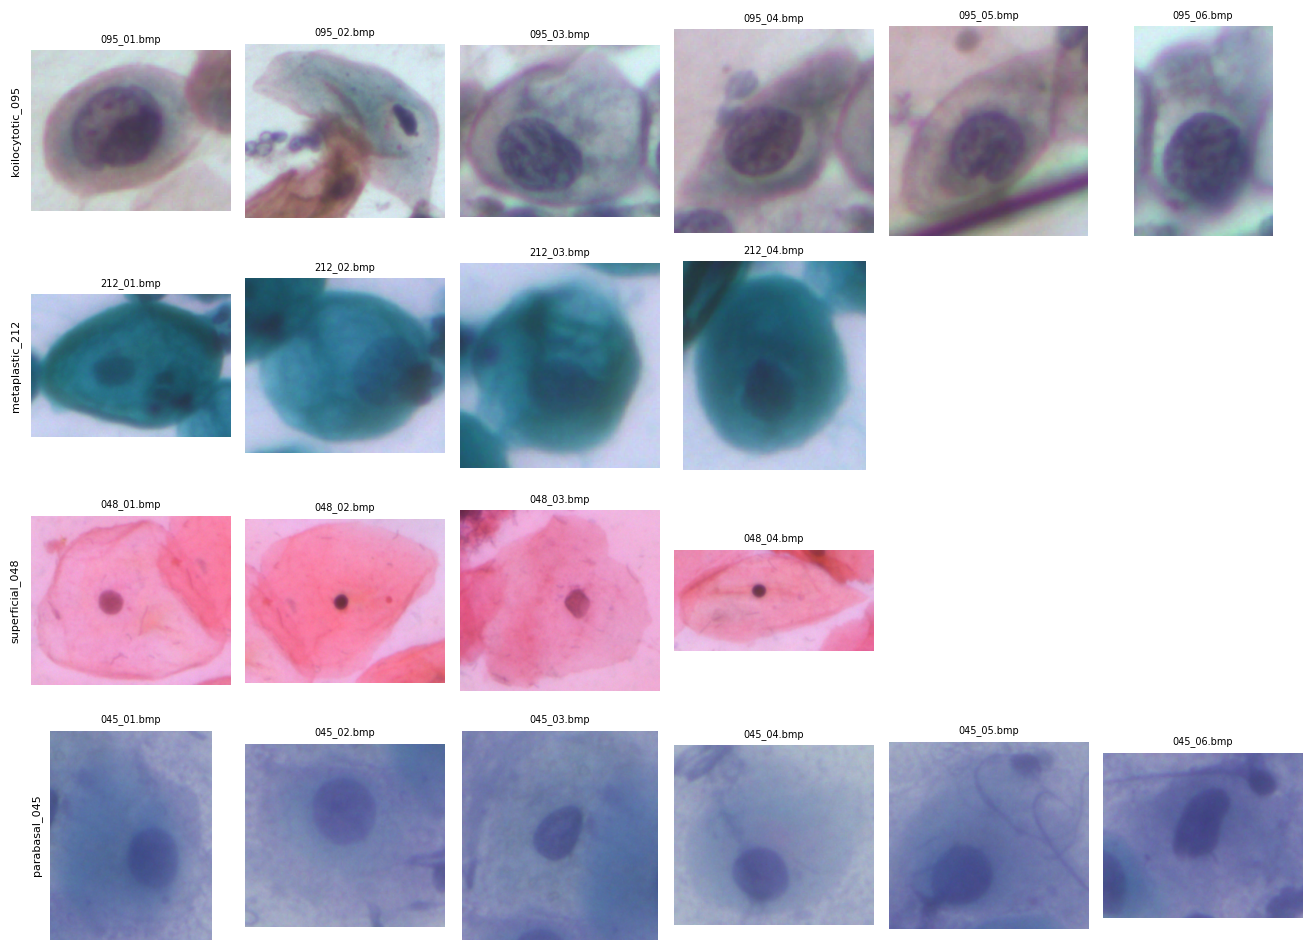

mean cosine  same-group: 0.415 | different-group, same class: 0.133
same-group more similar in 98.1% of anchors (n=753)
Coverage by shift family (target 0.90)
method   clean-cal  max-shift (proposed)  pooled  pooled-Mondrian
family                                                           
hed          0.747                 0.983   0.892            0.883
macenko      0.534                 0.797   0.679            0.692
photo        0.848                 0.988   0.967            0.945

Summary over all shifts (mean / worst coverage, mean set size)
                             cov_mean  cov_worst  size_mean
split  method                                              
group  clean-cal                0.806      0.563      0.879
       max-shift (proposed)     0.968      0.774      1.566
       pooled                   0.927      0.704      1.212
       pooled-Mondrian          0.910      0.712      1.186
random clean-cal                0.742      0.421      0.794
       max-shift (proposed)

In [28]:
# Paste each CELL into a new Kaggle cell, in order.
# CELL G needs: df, loader, eval_tf, DEVICE (from earlier cells). CELL G2 recomputes embeddings as EMB.
# CELL M needs only the saved shift_logits_v2.pt (no GPU, runs in seconds).
# NOTE: written from the notebook's own code; not executed here (no torch in my sandbox).


# %% ===================== CELL G: do same-prefix images really look like one slide? =====================
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

sizes = df.groupby("group").size()
print("Images per group:\n", sizes.describe().round(2))

rng = np.random.default_rng(0)
cands = sizes[sizes >= 4].index.to_numpy()
pick = rng.choice(cands, size=4, replace=False)           # 4 random groups
NCOL = 6
fig, ax = plt.subplots(len(pick), NCOL, figsize=(2.2 * NCOL, 2.4 * len(pick)))
for r, g in enumerate(pick):
    paths = df.loc[df["group"] == g, "path"].tolist()[:NCOL]
    for c in range(NCOL):
        ax[r, c].axis("off")
        if c < len(paths):
            ax[r, c].imshow(Image.open(paths[c]).convert("RGB"))
            ax[r, c].set_title(Path(paths[c]).name, fontsize=7)
    ax[r, 0].text(-0.05, 0.5, g, transform=ax[r, 0].transAxes, rotation=90,
                  va="center", ha="right", fontsize=8)
plt.tight_layout(); plt.savefig("group_check_samples.png", dpi=150); plt.show()


# %% ===================== CELL G2: same-group vs different-group similarity (needs GPU, ~1 min) =====================
import torch, timm
import torch.nn.functional as F

@torch.no_grad()
def embed_resnet(dframe):
    m = timm.create_model("resnet50", pretrained=True, num_classes=0).to(DEVICE).eval()
    out = torch.cat([m(x.to(DEVICE)).cpu() for x, _ in loader(dframe, eval_tf, False)])
    del m; torch.cuda.empty_cache()
    return F.normalize(out - out.mean(0, keepdim=True), dim=1)

EMB = embed_resnet(df.reset_index(drop=True))      # new name: nothing else overwrites it
g_arr, y_arr = df["group"].to_numpy(), df["y"].to_numpy()

same, diff = [], []
for i in np.random.default_rng(1).choice(len(df), 800, replace=False):
    sim = (EMB[i] @ EMB.T).numpy()
    m_same = (g_arr == g_arr[i]); m_same[i] = False
    m_diff = (y_arr == y_arr[i]) & (g_arr != g_arr[i])
    if m_same.any():
        same.append(sim[m_same].mean()); diff.append(sim[m_diff].mean())
same, diff = np.array(same), np.array(diff)
print(f"mean cosine  same-group: {same.mean():.3f} | different-group, same class: {diff.mean():.3f}")
print(f"same-group more similar in {(same > diff).mean():.1%} of anchors (n={len(same)})")


# %% ===================== CELL M: shift-aware conformal prediction (no retraining) =====================
import math, pandas as pd
import torch, torch.nn.functional as F

D = torch.load("shift_logits_v2.pt", map_location="cpu")      # dict(VL, TL, YV, YT); keys (split, model, shift)
VL, TL, YV, YT = D["VL"], D["TL"], D["YV"], D["YT"]
SHIFTS = sorted({k[2] for k in VL})
MODELS = sorted({k[1] for k in VL})
FAMILY = {"clean": "clean", "hed_mild": "hed", "hed_strong": "hed", "brightness": "photo",
          "contrast": "photo", "saturation": "photo", "hue": "photo", "macenko": "macenko"}
ALPHA = 0.1


def fit_temperature(l, y):
    logT = torch.zeros(1, requires_grad=True)
    opt = torch.optim.LBFGS([logT], lr=0.1, max_iter=100)
    def closure():
        opt.zero_grad(); loss = F.cross_entropy(l / logT.exp(), y); loss.backward(); return loss
    opt.step(closure)
    return float(logT.detach().exp())


def qhat(sc, alpha=ALPHA):
    n = len(sc); k = math.ceil((n + 1) * (1 - alpha))
    return float("inf") if k > n else torch.sort(sc).values[k - 1].item()


def nonconf(p, y):                       # LAC score
    return 1 - p[torch.arange(len(y)), y]


def sets_from_q(test_p, q):              # q: scalar or per-class tensor
    return (1 - test_p) <= q


rows = []
for split in ["random", "group"]:
    yv, yt = YV[split], YT[split]
    for name in MODELS:
        T0 = fit_temperature(VL[(split, name, "clean")], yv)
        for sh in SHIFTS:
            if sh == "clean":
                continue
            tl = TL[(split, name, sh)].float()
            pool = [s for s in SHIFTS if FAMILY[s] != FAMILY[sh]]       # leave-one-FAMILY-out, contains clean
            pool_l = torch.cat([VL[(split, name, s)].float() for s in pool])
            pool_y = yv.repeat(len(pool))
            Tp = fit_temperature(pool_l, pool_y)
            pp = F.softmax(pool_l / Tp, 1)
            tp = F.softmax(tl / Tp, 1)

            out = {}
            # 1) baseline: calibrate on clean val only
            out["clean-cal"] = sets_from_q(F.softmax(tl / T0, 1),
                                           qhat(nonconf(F.softmax(VL[(split, name, "clean")].float() / T0, 1), yv)))
            # 2) pooled: one quantile over all pool shifts
            out["pooled"] = sets_from_q(tp, qhat(nonconf(pp, pool_y)))
            # 3) PROPOSED  max-shift: quantile computed per calibration shift, take the most conservative
            qs = [qhat(nonconf(F.softmax(VL[(split, name, s)].float() / Tp, 1), yv)) for s in pool]
            out["max-shift (proposed)"] = sets_from_q(tp, max(qs))
            # 4) pooled + class-conditional (Mondrian)
            qc = torch.tensor([qhat(nonconf(pp, pool_y)[pool_y == c]) for c in range(tp.shape[1])])
            out["pooled-Mondrian"] = sets_from_q(tp, qc[None, :])

            for method, S in out.items():
                cov_i = S[torch.arange(len(yt)), yt].float()
                rows.append(dict(split=split, model=name, shift=sh, family=FAMILY[sh], method=method,
                                 coverage=cov_i.mean().item(),
                                 avg_size=S.sum(1).float().mean().item(),
                                 worst_class_cov=min(cov_i[yt == c].mean().item() for c in range(S.shape[1]))))

R = pd.DataFrame(rows)
R.to_csv("shift_aware_conformal.csv", index=False)
pd.set_option("display.width", 200)

print("Coverage by shift family (target 0.90)")
print(R.pivot_table(index="family", columns="method", values="coverage").round(3))
print("\nSummary over all shifts (mean / worst coverage, mean set size)")
print(R.groupby(["split", "method"]).agg(cov_mean=("coverage", "mean"), cov_worst=("coverage", "min"),
                                        size_mean=("avg_size", "mean")).round(3))

In [35]:

# ================================================================
# CELL ABL-2: TRAINING-TIME ABLATION STUDY
# SIPaKMeD | ResNet50 | Group-wise split
# ================================================================

import copy, gc, os, time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import timm
import torchvision.transforms as T
import torchvision.transforms.functional as TF

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score
from scipy import stats

# ------------------------------------------------
# 1. CHECK REQUIRED VARIABLES
# ------------------------------------------------

_need = [
    "df", "classes", "DEVICE", "BS", "LR", "norm",
    "eval_tf", "loader", "run_epoch", "get_logits",
    "fit_temperature", "ece", "conformal_sets",
    "group_split", "seed_all", "materialize",
    "hed_jitter_v2", "macenko_norm"
]

_missing = [n for n in _need if n not in globals()]
assert not _missing, (
    f"Missing required variables/functions: {_missing}. "
    "Run the corresponding earlier notebook cells."
)

# IMPORTANT: Never use global IMG here.
# Another notebook cell overwrites IMG with a directory path.
ABL_IMG_SIZE = 224

from torch.utils.data import Dataset, DataLoader

# ------------------------------------------------
# 2. EXPERIMENT CONFIGURATION
# ------------------------------------------------

ABL_MODEL = "resnet50"
ABL_EPOCHS = 10

ABL_SEEDS = [0]

ABL_RESULTS = "ablation_training.csv"
ABL_SUMMARY = "ablation_training_summary.csv"

ALPHA = 0.10

ABL_SHIFTS = {
    "clean": lambda im, r: im,

    "hed_mild": hed_jitter_v2(0.15),
    "hed_strong": hed_jitter_v2(0.30),

    "brightness": lambda im, r:
        TF.adjust_brightness(im, 0.6),

    "contrast": lambda im, r:
        TF.adjust_contrast(im, 0.6),

    "saturation": lambda im, r:
        TF.adjust_saturation(im, 0.4),

    "hue": lambda im, r:
        TF.adjust_hue(im, 0.06),

    "macenko": macenko_norm
}

FAMILY = {
    "clean": "clean",
    "hed_mild": "hed",
    "hed_strong": "hed",
    "brightness": "photo",
    "contrast": "photo",
    "saturation": "photo",
    "hue": "photo",
    "macenko": "macenko"
}

# ------------------------------------------------
# 3. ABLATION VARIANTS
# ------------------------------------------------

VARIANTS = {

    "A0 no augmentation":
        dict(flip=False, rot=False,
             jitter=False, hed_p=0.0),

    "A1 geometric only":
        dict(flip=True, rot=True,
             jitter=False, hed_p=0.0),

    "A2 geometric + ColorJitter (base)":
        dict(flip=True, rot=True,
             jitter=True, hed_p=0.0),

    "A3 + HED aug (p=0.7, s 0.05-0.35)":
        dict(flip=True, rot=True,
             jitter=True, hed_p=0.7,
             hed_rng=(0.05, 0.35)),

    "A4 + HED aug, p=0.3":
        dict(flip=True, rot=True,
             jitter=True, hed_p=0.3,
             hed_rng=(0.05, 0.35)),

    "A5 + HED aug, mild (s 0.05-0.15)":
        dict(flip=True, rot=True,
             jitter=True, hed_p=0.7,
             hed_rng=(0.05, 0.15)),

    "A6 HED aug without ColorJitter":
        dict(flip=True, rot=True,
             jitter=False, hed_p=0.7,
             hed_rng=(0.05, 0.35)),

    "A7 random init (no ImageNet)":
        dict(flip=True, rot=True,
             jitter=True, hed_p=0.0,
             pretrained=False)
}

RUN = list(VARIANTS.keys())

# ------------------------------------------------
# 4. TRAINING TRANSFORMS
# ------------------------------------------------

def tf_train(c):

    ops = [
        T.Resize((ABL_IMG_SIZE, ABL_IMG_SIZE))
    ]

    if c["flip"]:
        ops += [
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip()
        ]

    if c["rot"]:
        ops += [
            T.RandomRotation(20)
        ]

    if c["jitter"]:
        ops += [
            T.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2,
                hue=0.05
            )
        ]

    return T.Compose(
        ops + [
            T.ToTensor(),
            norm
        ]
    )


# ------------------------------------------------
# 5. CUSTOM DATASET
# ------------------------------------------------

class AblDS(Dataset):

    def __init__(self, d, transform,
                 hed_p=0.0,
                 hed_rng=(0.05, 0.35)):

        self.paths = d["path"].tolist()
        self.labels = d["y"].tolist()

        self.transform = transform
        self.hed_p = hed_p
        self.hed_rng = hed_rng

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):

        img = Image.open(
            self.paths[i]
        ).convert("RGB")

        rng = np.random.default_rng()

        if self.hed_p > 0 and rng.random() < self.hed_p:

            strength = rng.uniform(*self.hed_rng)

            img = hed_jitter_v2(strength)(img, rng)

        return self.transform(img), self.labels[i]


# ------------------------------------------------
# 6. INDEPENDENT LOGIT COLLECTION
# Avoids conflict with the later collect() function.
# ------------------------------------------------

@torch.no_grad()
def abl_collect_logits(model, X, batch_size=64):

    model.eval()
    outputs = []

    for i in range(0, len(X), batch_size):

        xb = X[i:i + batch_size].to(
            DEVICE
        ).float()

        logits = model(xb)

        outputs.append(logits.cpu())

    return torch.cat(outputs, dim=0)


# ------------------------------------------------
# 7. TRAIN EACH ABLATION VARIANT
# ------------------------------------------------

def train_variant(c, seed, tr, va):

    seed_all(seed)

    train_ds = AblDS(
        tr,
        tf_train(c),
        c["hed_p"],
        c.get("hed_rng", (0.05, 0.35))
    )

    dl_tr = DataLoader(
        train_ds,
        batch_size=BS,
        shuffle=True,
        num_workers=2,
        pin_memory=(DEVICE == "cuda")
    )

    dl_va = loader(va, eval_tf, False)

    model = timm.create_model(
        ABL_MODEL,
        pretrained=c.get("pretrained", True),
        num_classes=len(classes)
    ).to(DEVICE)

    opt = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=1e-4
    )

    best_f1 = -1.0
    best_state = None

    for ep in range(ABL_EPOCHS):

        loss = run_epoch(model, dl_tr, opt)

        vl, vy = get_logits(model, dl_va)

        f1 = f1_score(
            vy.numpy(),
            vl.argmax(1).numpy(),
            average="macro"
        )

        print(
            f"Epoch {ep+1:02d}/{ABL_EPOCHS} "
            f"| Train Loss: {loss:.4f} "
            f"| Val Macro-F1: {f1:.4f}"
        )

        if f1 > best_f1:

            best_f1 = f1

            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

    model.load_state_dict(best_state)

    return model.eval()


# ------------------------------------------------
# 8. EVALUATE EACH VARIANT
# ------------------------------------------------

def eval_variant(model, XV, XT, yv, yt, tag, seed):

    VLd = {
        s: abl_collect_logits(model, XV[s])
        for s in ABL_SHIFTS
    }

    TLd = {
        s: abl_collect_logits(model, XT[s])
        for s in ABL_SHIFTS
    }

    T0 = fit_temperature(
        VLd["clean"], yv
    )

    cal_clean = F.softmax(
        VLd["clean"] / T0, dim=1
    )

    results = []

    for sh in ABL_SHIFTS:

        tl = TLd[sh]

        row = {
            "variant": tag,
            "seed": seed,
            "shift": sh,
            "family": FAMILY[sh],

            "macro_f1": f1_score(
                yt.numpy(),
                tl.argmax(1).numpy(),
                average="macro"
            )
        }

        # Leave-one-family-out calibration pool
        pool = [
            s for s in ABL_SHIFTS
            if FAMILY[s] != FAMILY[sh]
        ]

        pl = torch.cat([
            VLd[s] for s in pool
        ])

        py = yv.repeat(len(pool))

        Tp = fit_temperature(pl, py)

        calibration_methods = [
            (
                "clean",
                cal_clean,
                yv,
                T0
            ),
            (
                "lofo",
                F.softmax(pl / Tp, dim=1),
                py,
                Tp
            )
        ]

        for meth, cp, cy, Tm in calibration_methods:

            test_prob = F.softmax(
                tl / Tm, dim=1
            )

            sets = conformal_sets(
                cp, cy, test_prob, ALPHA
            )

            correct = sets[
                torch.arange(len(yt)), yt
            ]

            row[f"cov_{meth}"] = (
                correct.float().mean().item()
            )

            row[f"size_{meth}"] = (
                sets.sum(1).float().mean().item()
            )

            row[f"ece_{meth}"] = ece(
                tl / Tm, yt
            )

        results.append(row)

    return results


# ------------------------------------------------
# 9. RESUMABLE EXPERIMENT EXECUTION
# ------------------------------------------------

rows = []
done = set()

if os.path.exists(ABL_RESULTS):

    previous = pd.read_csv(ABL_RESULTS)

    rows = previous.to_dict("records")

    done = set(
        zip(previous["variant"], previous["seed"])
    )

for seed in ABL_SEEDS:

    tr, va, te = group_split(df, seed)

    todo = [
        v for v in RUN
        if (v, seed) not in done
    ]

    if not todo:
        print(f"Seed {seed}: all variants already completed.")
        continue

    t0 = time.time()

    # Cache shifted validation and test images once per seed
    XV, XT = {}, {}

    for sh, transform in ABL_SHIFTS.items():

        XV[sh], yv = materialize(
            va, transform
        )

        XT[sh], yt = materialize(
            te, transform
        )

    print(
        f"\n[Seed {seed}] Shifted images cached "
        f"in {time.time()-t0:.1f} seconds"
    )

    for v in todo:

        print(f"\n[{v} | seed {seed}]")

        t1 = time.time()

        model = train_variant(
            VARIANTS[v], seed, tr, va
        )

        new_rows = eval_variant(
            model, XV, XT, yv, yt, v, seed
        )

        rows.extend(new_rows)

        # Save after every completed variant
        pd.DataFrame(rows).to_csv(
            ABL_RESULTS, index=False
        )

        print(
            f"Completed {v} in "
            f"{time.time()-t1:.1f} seconds"
        )

        del model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    del XV, XT
    gc.collect()


# ------------------------------------------------
# 10. SUMMARY TABLE WITH CONFIDENCE INTERVALS
# ------------------------------------------------

A = pd.read_csv(ABL_RESULTS)

summary_rows = []

for (variant, seed), g in A.groupby(
    ["variant", "seed"]
):

    clean = g[g["shift"] == "clean"]
    shifted = g[g["shift"] != "clean"]

    if clean.empty or shifted.empty:
        continue

    summary_rows.append({

        "variant": variant,
        "seed": seed,

        "f1_clean": clean["macro_f1"].mean(),

        "f1_shift": shifted["macro_f1"].mean(),

        "f1_hed": shifted[
            shifted.family == "hed"
        ]["macro_f1"].mean(),

        "f1_photo": shifted[
            shifted.family == "photo"
        ]["macro_f1"].mean(),

        "f1_macenko": shifted[
            shifted.family == "macenko"
        ]["macro_f1"].mean(),

        "cov_clean": shifted["cov_clean"].mean(),

        "cov_lofo": shifted["cov_lofo"].mean(),

        "cov_lofo_min": shifted["cov_lofo"].min(),

        "size_lofo": shifted["size_lofo"].mean(),

        "ece_clean": shifted["ece_clean"].mean(),

        "ece_lofo": shifted["ece_lofo"].mean()
    })


PS = pd.DataFrame(summary_rows)

# Mean and 95% confidence interval across seeds
final_rows = []

metrics_list = [
    "f1_clean", "f1_shift",
    "f1_hed", "f1_photo", "f1_macenko",
    "cov_clean", "cov_lofo", "cov_lofo_min",
    "size_lofo", "ece_clean", "ece_lofo"
]

for variant, g in PS.groupby("variant"):

    result = {
        "variant": variant,
        "n_seeds": g["seed"].nunique()
    }

    for col in metrics_list:

        values = g[col].dropna().values.astype(float)

        result[col] = (
            values.mean() if len(values) else np.nan
        )

        if len(values) > 1:

            ci = (
                stats.t.ppf(
                    0.975, len(values) - 1
                )
                * values.std(ddof=1)
                / np.sqrt(len(values))
            )

            result[col + "_ci"] = ci

        else:
            result[col + "_ci"] = np.nan

    final_rows.append(result)


TAB = pd.DataFrame(final_rows)

# Preserve the original experimental order
TAB["variant"] = pd.Categorical(
    TAB["variant"],
    categories=list(VARIANTS.keys()),
    ordered=True
)

TAB = TAB.sort_values("variant").reset_index(drop=True)

# Difference from the base augmentation strategy
base = "A2 geometric + ColorJitter (base)"

if base in TAB["variant"].astype(str).values:

    base_row = TAB[
        TAB["variant"].astype(str) == base
    ].iloc[0]

    for col in [
        "f1_clean", "f1_shift",
        "f1_macenko", "cov_clean",
        "cov_lofo", "size_lofo",
        "ece_clean"
    ]:

        TAB["d_" + col] = (
            TAB[col] - base_row[col]
        )


TAB.to_csv(
    ABL_SUMMARY, index=False
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 260)

print("\n" + "=" * 90)
print("TABLE A4: TRAINING-TIME ABLATION STUDY")
print("Model: ResNet50 | Split: Group-wise")
print("Target conformal coverage:", 1 - ALPHA)
print("=" * 90)

print(
    TAB[
        ["variant", "n_seeds"] + metrics_list
    ].round(4).to_string(index=False)
)

print("\nSaved files:")
print("1.", ABL_RESULTS)
print("2.", ABL_SUMMARY)

print("\nABLATION STUDY COMPLETED")



[Seed 0] Shifted images cached in 69.0 seconds

[A0 no augmentation | seed 0]
Epoch 01/10 | Train Loss: 1.4297 | Val Macro-F1: 0.7530
Epoch 02/10 | Train Loss: 0.8060 | Val Macro-F1: 0.8863
Epoch 03/10 | Train Loss: 0.3768 | Val Macro-F1: 0.9032
Epoch 04/10 | Train Loss: 0.2462 | Val Macro-F1: 0.9231
Epoch 05/10 | Train Loss: 0.1674 | Val Macro-F1: 0.9405
Epoch 06/10 | Train Loss: 0.1300 | Val Macro-F1: 0.9513
Epoch 07/10 | Train Loss: 0.1132 | Val Macro-F1: 0.9401
Epoch 08/10 | Train Loss: 0.0740 | Val Macro-F1: 0.9270
Epoch 09/10 | Train Loss: 0.0744 | Val Macro-F1: 0.9555
Epoch 10/10 | Train Loss: 0.0582 | Val Macro-F1: 0.9438
Completed A0 no augmentation in 384.3 seconds

[A1 geometric only | seed 0]
Epoch 01/10 | Train Loss: 1.4331 | Val Macro-F1: 0.7743
Epoch 02/10 | Train Loss: 0.7926 | Val Macro-F1: 0.8704
Epoch 03/10 | Train Loss: 0.3936 | Val Macro-F1: 0.8928
Epoch 04/10 | Train Loss: 0.2924 | Val Macro-F1: 0.9138
Epoch 05/10 | Train Loss: 0.2249 | Val Macro-F1: 0.9277
Epoch

In [36]:

# ================================================================
# CERVICAL CANCER DETECTION
# 5-FOLD STRATIFIED GROUP CROSS-VALIDATION
# ResNet50 | EfficientNet-B0 | ViT-B/16
# ================================================================

!pip install timm -q

import os, re, gc, time, copy, random, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import timm
import torchvision.transforms as T

from PIL import Image
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import (
    StratifiedGroupKFold, GroupShuffleSplit
)
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report, confusion_matrix
)

# ===================== CONFIGURATION =====================

DATA_ROOT = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"

MODELS = [
    "resnet50",
    "efficientnet_b0",
    "vit_base_patch16_224"
]

N_FOLDS = 5
EPOCHS = 10
BS = 32
LR = 1e-4
IMG = 224
SEED = 42

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CLASS_KEYS = [
    "dyskeratotic",
    "koilocytotic",
    "metaplastic",
    "parabasal",
    "superficial"
]

print("Device:", DEVICE)

assert Path(DATA_ROOT).exists(), (
    "Dataset path not found. Check DATA_ROOT."
)

# ===================== REPRODUCIBILITY =====================

def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# ===================== DATASET COLLECTION =====================

def get_class(path):
    parts = [x.lower() for x in path.parts]

    for cls in CLASS_KEYS:
        if any(cls in part for part in parts):
            return cls

    return path.parent.name.lower()


def get_group(path, cls):
    # Group images sharing the same numeric filename prefix
    match = re.match(r"^(\d+)_\d+", path.stem)

    if match:
        return f"{cls}_{match.group(1)}"

    return f"{cls}_{path.stem}"


extensions = {
    ".bmp", ".png", ".jpg", ".jpeg", ".tif", ".tiff"
}

files = [
    p for p in Path(DATA_ROOT).rglob("*")
    if p.suffix.lower() in extensions
]

cropped = [
    p for p in files
    if "cropped" in str(p).lower()
]

if cropped:
    files = cropped

df = pd.DataFrame({
    "path": [str(p) for p in files]
})

df["cls"] = [
    get_class(p) for p in files
]

df["group"] = [
    get_group(p, c)
    for p, c in zip(files, df["cls"])
]

# Remove exact duplicate images
df["md5"] = [
    hashlib.md5(Path(p).read_bytes()).hexdigest()
    for p in df["path"]
]

df = df.drop_duplicates("md5").reset_index(drop=True)

classes = sorted(df["cls"].unique())

assert len(classes) == 5, (
    f"Expected 5 classes, found {classes}. "
    "Check dataset folder structure."
)

class_to_id = {
    cls: i for i, cls in enumerate(classes)
}

df["y"] = df["cls"].map(class_to_id)

print("\nDataset Summary")
print("-----------------------------")
print("Total images:", len(df))
print("Total groups:", df["group"].nunique())
print(df["cls"].value_counts())

# ===================== IMAGE PREPROCESSING =====================

norm = T.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

train_tf = T.Compose([
    T.Resize((IMG, IMG)),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(20),
    T.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2,
        hue=0.05
    ),
    T.ToTensor(),
    norm
])

eval_tf = T.Compose([
    T.Resize((IMG, IMG)),
    T.ToTensor(),
    norm
])


class CervicalDataset(Dataset):

    def __init__(self, data, transform):
        self.paths = data["path"].tolist()
        self.labels = data["y"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):

        image = Image.open(
            self.paths[index]
        ).convert("RGB")

        image = self.transform(image)

        label = self.labels[index]

        return image, label


def make_loader(data, transform, shuffle):

    return DataLoader(
        CervicalDataset(data, transform),
        batch_size=BS,
        shuffle=shuffle,
        num_workers=2,
        pin_memory=(DEVICE == "cuda")
    )

# ===================== TRAINING FUNCTION =====================

def train_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0
    total_samples = 0

    for images, labels in loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = model(images)

        loss = F.cross_entropy(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    return total_loss / total_samples


# ===================== PREDICTION FUNCTION =====================

@torch.no_grad()
def predict(model, loader):

    model.eval()

    predictions = []
    actuals = []

    for images, labels in loader:

        images = images.to(DEVICE)

        outputs = model(images)

        predictions.extend(
            outputs.argmax(1).cpu().numpy()
        )

        actuals.extend(labels.numpy())

    return np.array(predictions), np.array(actuals)


# ===================== 5-FOLD CROSS VALIDATION =====================

cv = StratifiedGroupKFold(
    n_splits=N_FOLDS,
    shuffle=True,
    random_state=SEED
)

results = []
confusion_results = []

for model_name in MODELS:

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    for fold, (train_idx, test_idx) in enumerate(
        cv.split(
            df,
            df["y"],
            groups=df["group"]
        ),
        start=1
    ):

        print(f"\nFOLD {fold}/{N_FOLDS}")

        seed_all(SEED + fold)

        # Outer training and testing sets
        outer_train = df.iloc[train_idx].copy()
        test_df = df.iloc[test_idx].copy()

        # Inner group-independent validation split
        inner_split = GroupShuffleSplit(
            n_splits=1,
            test_size=0.15,
            random_state=SEED + fold
        )

        tr_idx, val_idx = next(
            inner_split.split(
                outer_train,
                groups=outer_train["group"]
            )
        )

        train_df = outer_train.iloc[tr_idx].copy()
        val_df = outer_train.iloc[val_idx].copy()

        # Check group leakage
        assert set(train_df["group"]).isdisjoint(
            set(val_df["group"])
        )

        assert set(train_df["group"]).isdisjoint(
            set(test_df["group"])
        )

        assert set(val_df["group"]).isdisjoint(
            set(test_df["group"])
        )

        print(
            "Train:", len(train_df),
            "| Validation:", len(val_df),
            "| Test:", len(test_df)
        )

        # Data loaders
        train_loader = make_loader(
            train_df, train_tf, True
        )

        val_loader = make_loader(
            val_df, eval_tf, False
        )

        test_loader = make_loader(
            test_df, eval_tf, False
        )

        # Initialize pretrained model
        model = timm.create_model(
            model_name,
            pretrained=True,
            num_classes=len(classes)
        ).to(DEVICE)

        model_lr = (
            3e-5 if "vit" in model_name else LR
        )

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=model_lr,
            weight_decay=1e-4
        )

        best_f1 = -1
        best_state = None

        # Model training
        start_time = time.time()

        for epoch in range(EPOCHS):

            loss = train_epoch(
                model,
                train_loader,
                optimizer
            )

            val_pred, val_true = predict(
                model,
                val_loader
            )

            val_f1 = f1_score(
                val_true,
                val_pred,
                labels=np.arange(len(classes)),
                average="macro",
                zero_division=0
            )

            print(
                f"Epoch {epoch+1}/{EPOCHS} | "
                f"Loss: {loss:.4f} | "
                f"Validation F1: {val_f1:.4f}"
            )

            if val_f1 > best_f1:

                best_f1 = val_f1

                best_state = {
                    k: v.detach().cpu().clone()
                    for k, v in model.state_dict().items()
                }

        # Restore best validation model
        model.load_state_dict(best_state)

        # Independent test evaluation
        y_pred, y_true = predict(
            model,
            test_loader
        )

        # Calculate metrics
        accuracy = accuracy_score(
            y_true, y_pred
        )

        precision = precision_score(
            y_true,
            y_pred,
            labels=np.arange(len(classes)),
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            y_true,
            y_pred,
            labels=np.arange(len(classes)),
            average="macro",
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            y_pred,
            labels=np.arange(len(classes)),
            average="macro",
            zero_division=0
        )

        # Store fold results
        results.append({
            "Model": model_name,
            "Fold": fold,
            "Train_Images": len(train_df),
            "Validation_Images": len(val_df),
            "Test_Images": len(test_df),
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1_Score": f1,
            "Best_Validation_F1": best_f1,
            "Training_Time_Min": (
                time.time() - start_time
            ) / 60
        })

        # Store confusion matrix
        cm = confusion_matrix(
            y_true,
            y_pred,
            labels=np.arange(len(classes))
        )

        confusion_results.append({
            "Model": model_name,
            "Fold": fold,
            "Confusion_Matrix": cm.tolist()
        })

        print("\nClassification Report:")
        print(
            classification_report(
                y_true,
                y_pred,
                labels=np.arange(len(classes)),
                target_names=classes,
                zero_division=0
            )
        )

        print("Fold Accuracy:", round(accuracy, 4))
        print("Fold Precision:", round(precision, 4))
        print("Fold Recall:", round(recall, 4))
        print("Fold F1-score:", round(f1, 4))

        # Save fold checkpoint
        checkpoint_name = (
            f"{model_name}_fold_{fold}.pt"
        )

        torch.save(
            best_state,
            checkpoint_name
        )

        # Release memory
        del model, optimizer, best_state
        del train_loader, val_loader, test_loader

        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

# ===================== SAVE FOLD RESULTS =====================

results_df = pd.DataFrame(results)

results_df.to_csv(
    "5fold_individual_results.csv",
    index=False
)

# ===================== MEAN AND STANDARD DEVIATION =====================

summary = results_df.groupby("Model").agg({
    "Accuracy": ["mean", "std"],
    "Precision": ["mean", "std"],
    "Recall": ["mean", "std"],
    "F1_Score": ["mean", "std"]
})

summary.to_csv(
    "5fold_mean_std_summary.csv"
)

# ===================== DISPLAY FINAL RESULTS =====================

print("\n" + "=" * 75)
print("FINAL 5-FOLD CROSS-VALIDATION RESULTS")
print("=" * 75)

print(summary.round(4))

print("\nINDIVIDUAL FOLD RESULTS")
print(results_df.round(4).to_string(index=False))

# ===================== SAVE CONFUSION MATRICES =====================

cm_df = pd.DataFrame(confusion_results)

cm_df.to_csv(
    "5fold_confusion_matrices.csv",
    index=False
)

print("\nEXPERIMENT COMPLETED SUCCESSFULLY")

print("\nGenerated Files:")
print("1. 5fold_individual_results.csv")
print("2. 5fold_mean_std_summary.csv")
print("3. 5fold_confusion_matrices.csv")
print("4. Model fold checkpoints (.pt)")



Device: cuda

Dataset Summary
-----------------------------
Total images: 4049
Total groups: 966
cls
superficial     831
koilocytotic    825
dyskeratotic    813
metaplastic     793
parabasal       787
Name: count, dtype: int64

MODEL: resnet50

FOLD 1/5
Train: 2729 | Validation: 506 | Test: 814
Epoch 1/10 | Loss: 1.4252 | Validation F1: 0.7541
Epoch 2/10 | Loss: 0.7612 | Validation F1: 0.8633
Epoch 3/10 | Loss: 0.3865 | Validation F1: 0.8875
Epoch 4/10 | Loss: 0.2900 | Validation F1: 0.9288
Epoch 5/10 | Loss: 0.2597 | Validation F1: 0.8768
Epoch 6/10 | Loss: 0.2276 | Validation F1: 0.9317
Epoch 7/10 | Loss: 0.2009 | Validation F1: 0.9015
Epoch 8/10 | Loss: 0.1717 | Validation F1: 0.9318
Epoch 9/10 | Loss: 0.1707 | Validation F1: 0.9116
Epoch 10/10 | Loss: 0.1448 | Validation F1: 0.9245

Classification Report:
              precision    recall  f1-score   support

dyskeratotic       0.97      0.94      0.95       204
koilocytotic       0.81      0.92      0.86       159
 metaplastic    

In [41]:
import pandas as pd, numpy as np, ast
cm = pd.read_csv("5fold_confusion_matrices.csv")
cm["M"] = cm["Confusion_Matrix"].apply(ast.literal_eval)
for m, g in cm.groupby("Model"):
    S = sum(np.array(a) for a in g["M"])
    print(m, dict(zip(classes, (S.diagonal() / S.sum(1)).round(3))))

efficientnet_b0 {'dyskeratotic': np.float64(0.929), 'koilocytotic': np.float64(0.847), 'metaplastic': np.float64(0.885), 'parabasal': np.float64(0.957), 'superficial': np.float64(0.986)}
resnet50 {'dyskeratotic': np.float64(0.966), 'koilocytotic': np.float64(0.897), 'metaplastic': np.float64(0.91), 'parabasal': np.float64(0.98), 'superficial': np.float64(0.978)}
vit_base_patch16_224 {'dyskeratotic': np.float64(0.951), 'koilocytotic': np.float64(0.916), 'metaplastic': np.float64(0.936), 'parabasal': np.float64(0.986), 'superficial': np.float64(0.987)}


In [43]:
# Needs: ABN, yh, specs, dl_h from your Herlev cells (same kernel)
print("ABN (abnormal SIPaKMeD class ids):", ABN, "->", [classes[i] for i in ABN])
print("Herlev images:", len(yh), "| normal:", int((yh == 0).sum()), "| abnormal:", int((yh == 1).sum()))
try:
    print(h_df.groupby(["cls", "y"]).size())     # use your Herlev dataframe name if different
except Exception as e:
    print("Herlev dataframe name differs, so paste your Herlev loading cell instead:", e)

ABN (abnormal SIPaKMeD class ids): [0, 1] -> ['dyskeratotic', 'koilocytotic']
Herlev images: 917 | normal: 242 | abnormal: 675
Herlev dataframe name differs, so paste your Herlev loading cell instead: name 'h_df' is not defined


In [44]:
# Needs: df, H (dHash, 4049x64), embed_all, random_split, group_split
import numpy as np, torch
E = embed_all(df)
E = E - E.mean(0, keepdim=True)
E = torch.nn.functional.normalize(E, dim=1).numpy()

rows = []
for name, fn in [("random", random_split), ("group", group_split)]:
    tr, va, te = fn(df, 0)
    ti, ei = tr.index.values, te.index.values
    cos_max = (E[ei] @ E[ti].T).max(1)
    ham_min = np.array([(H[i][None, :] != H[ti]).sum(1).min() for i in ei])
    for c in [0.90, 0.95]:
        for h in [0, 4, 8]:
            rows.append(dict(split=name, cos=c, ham=h,
                             OR=((cos_max >= c) | (ham_min <= h)).mean(),
                             AND=((cos_max >= c) & (ham_min <= h)).mean(),
                             cos_only=(cos_max >= c).mean(),
                             ham_only=(ham_min <= h).mean()))
import pandas as pd
print(pd.DataFrame(rows).round(3).to_string(index=False))

 split  cos  ham    OR   AND  cos_only  ham_only
random 0.90    0 0.041 0.007     0.036     0.012
random 0.90    4 0.194 0.031     0.036     0.189
random 0.90    8 0.480 0.036     0.036     0.480
random 0.95    0 0.015 0.002     0.005     0.012
random 0.95    4 0.189 0.005     0.005     0.189
random 0.95    8 0.480 0.005     0.005     0.480
 group 0.90    0 0.037 0.003     0.026     0.015
 group 0.90    4 0.174 0.023     0.026     0.171
 group 0.90    8 0.449 0.026     0.026     0.449
 group 0.95    0 0.015 0.000     0.000     0.015
 group 0.95    4 0.171 0.000     0.000     0.171
 group 0.95    8 0.449 0.000     0.000     0.449


In [37]:
import sys, platform, torch, torchvision, timm, sklearn, scipy, numpy, pandas, PIL, skimage
print("Python", sys.version.split()[0], "|", platform.platform())
for n, m in [("torch", torch), ("torchvision", torchvision), ("timm", timm), ("scikit-learn", sklearn),
             ("scikit-image", skimage), ("scipy", scipy), ("numpy", numpy), ("pandas", pandas), ("Pillow", PIL)]:
    print(f"{n}: {m.__version__}")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("GPU:", p.name, "| memory GB:", round(p.total_memory / 1e9, 1), "| CUDA:", torch.version.cuda)
else:
    print("No GPU")

Python 3.13.16 | Linux-6.18.55+-x86_64-with-glibc2.39
torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
timm: 1.0.30
scikit-learn: 1.6.1
scikit-image: 0.25.2
scipy: 1.16.3
numpy: 2.1.3
pandas: 2.3.3
Pillow: 13.0.0
GPU: Tesla T4 | memory GB: 15.6 | CUDA: 13.0


In [38]:
import zipfile, glob, os

W = "/kaggle/working"
def make_zip(pattern, out, folder):
    seen = set()
    with zipfile.ZipFile(out, "w", zipfile.ZIP_DEFLATED) as z:
        for f in sorted(glob.glob(pattern, recursive=True)):
            name = os.path.basename(f)
            if name in seen:
                continue
            seen.add(name)
            z.write(f, f"{folder}/{name}")
    print(len(seen), "unique files ->", out)

make_zip(f"{W}/**/*.png", f"{W}/images_png_only.zip", "png")
make_zip(f"{W}/**/*.csv", f"{W}/tables_csv_only.zip", "csv")

35 unique files -> /kaggle/working/images_png_only.zip
56 unique files -> /kaggle/working/tables_csv_only.zip


In [39]:
import os, glob, shutil, zipfile

W = "/kaggle/working"
OUT = f"{W}/final_results"
IMG, TAB = f"{OUT}/images", f"{OUT}/tables"
shutil.rmtree(OUT, ignore_errors=True)
os.makedirs(IMG); os.makedirs(TAB)

def collect(pattern, dest):
    seen = set()
    for f in sorted(glob.glob(pattern, recursive=True)):
        if f.startswith(OUT):          # skip our own output folder
            continue
        name = os.path.basename(f)
        if name in seen:
            continue
        seen.add(name)
        shutil.copy(f, f"{dest}/{name}")
    return len(seen)

n_img = collect(f"{W}/**/*.png", IMG)
n_tab = collect(f"{W}/**/*.csv", TAB)

zip_path = f"{W}/final_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for root, _, files in os.walk(OUT):
        for f in files:
            full = os.path.join(root, f)
            z.write(full, os.path.relpath(full, OUT))

print(n_img, "images ->", IMG)
print(n_tab, "tables ->", TAB)
print("zip ->", zip_path)

35 images -> /kaggle/working/final_results/images
56 tables -> /kaggle/working/final_results/tables
zip -> /kaggle/working/final_results.zip


In [40]:
from IPython.display import FileLink
FileLink("final_results.zip")

/kaggle/working/final_results.zip